# **Predicting In-Hospital Mortality in Patients With Traumatic Brain Injury Using Early ICU Data**

**Authors:** Cindy Chen, Keith Megara Osores Vicuña, Ema Stangova 

**Master:** Health Data Science

**Subject:** Electronic Health Records (EHR)

**Course:** 2025-2026

---

## **Table of Contents**

**1. [Data extraction and cohort construction](#section1)**   

**2. [Data validation and cleaning](#section2)**   
&emsp; **2.1 [Import data and perform categorical segregation](#section21)**  
&emsp; **2.2 [Analysing biologically implausible values](#section22)**  
&emsp; **2.3 [Evaluating missing values](#section23)**   
&emsp; **2.4 [Exploratory statistics (outliers)](#section24)**    

**3. [Data visualization and exploratory analysis](#section3)**  

**4. [Logistic regression model](#section4)**   

---

**Important note:** This notebook was created using Python 3.13.7. For a proper execution, the required packages are listed in the txt file named 'requirements.txt' located in the same folder as this notebook. It can be done by running in following command on Powershell or Command Prompt: `pip install -r requirements.txt`.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import plotly.express as px

from scipy.stats import skew, kurtosis, chi2_contingency
from phik import phik_matrix
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    confusion_matrix,
    classification_report,
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings

warnings.filterwarnings("ignore")

---
<a id='section1'></a>
# **1. Data extraction and cohort construction**

The data extraction was performed using SQL on the MIMIC-III database and consisted of three main steps: 
1. Cohort identification
2. Aggregation of early ICU clinical measurements 
3. Aggregation of early laboratory values

**1. Cohort identification**  
A retrospective cohort of adult patients with traumatic brain injury (TBI) was identified using the ``PATIENTS``, ``ADMISSIONS``, ``ICUSTAYS``, and ``DIAGNOSES_ICD`` tables. Patients were included if they were aged 18 years or older at the time of hospital admission and had an ICD-9 diagnosis code corresponding to TBI (see table below).  

Codes 800–804 refer to skull fractures, while codes 850–854 represent intracranial injury. The specific descriptions are shown in the following table.

| **ICD-9 Code** | **Description**                                                    |
| -------------- | ------------------------------------------------------------------ |
| **800**        | Fracture of vault of skull                                         |
| **801**        | Fracture of base of skull                                          |
| **802**        | Fracture of face bones                                             |
| **803**        | Other and unqualified skull fractures                              |
| **804**        | Multiple fractures involving skull or face                         |
| **850**        | Concussion                                                         |
| **851**        | Cerebral laceration and contusion                                  |
| **852**        | Subarachnoid, subdural, and extradural hemorrhage following injury |
| **853**        | Other and unspecified intracranial hemorrhage following injury     |
| **854**        | Intracranial injury of other and unspecified nature                |

For patients with multiple ICU stays, a single ICU stay was selected per patient, prioritizing the terminal ICU stay for non-survivors and the earliest ICU stay for survivors. Patient demographics (age and sex), ICU admission and discharge times, ICU length of stay, and in-hospital mortality were also extracted. Patients were not excluded based on ICU length of stay, as early mortality or short ICU stays may reflect greater injury severity and excluding such cases could introduce survivorship bias.   

**2. Aggregation of early ICU clinical measurements**  
Early ICU clinical measurements were obtained from the ``CHARTEVENTS`` table and restricted to the first 24 hours following ICU admission. Only numeric values were included.

The following variables were derived at the ICU-stay level:

- **Glasgow Coma Scale (GCS)**: components (eye, verbal, motor), and total GCS. For GCS components, the minimum recorded value within the first 24 hours was used, reflecting the worst documented neurological status.
    - Eye-opening component (E): reflects level of arousal and neurological function (1-4)
    - Verbal response component (V): assesses cognitive and language respinse (1-5)
    - Motor response component (M): assesses a person's ability to move in reponse to commands or pain (1-6)
- **Total GCS**: calculated as the sum of the three components.
- **Mean arterial pressure (MAP)**: computed as the average of all recorded values during the first 24 hours. It's an indicator of cerebral perfusion (hypotension is associated with worse TBI outcomes).
- **Oxygen saturation (SpO₂)**: computed as the average of all recorded values during the first 24 hours. Reflects adequacy of oxygenation (hypoxia is a known secondary brain injury factor).
- **Mechanical ventilation status**: it was defined as a binary indicator based on any documentation of ventilator use during the first 24h. Serves as a marker of injury severity and respiratory failure.

For intubated patients with missing verbal GCS scores, the verbal component was assigned a value of 1, consistent with common clinical conventions.

**3. Aggregation of early laboratory values**   
Laboratory measurements were extracted from the ``LABEVENTS`` table and linked at the hospital admission level. Laboratory values recorded within the first 24 hours after ICU admission were included.

The following laboratory biomarkers were summarized using the mean value within the 24-hour window:

- **Serum sodium**: electrolyte disturbances are common in TBI and may affect cerebral edema and mortality.
- **Serum glucose**: stress hyperglycemia is associated with poor neurologic and ICU outcomes.
- **Hemoglobin**: reflects oxygen-carrying capacity (anemia may worsen cerebral hypooxia).

The final dataset was constructed by joining the TBI cohort with the aggregated clinical and laboratory data. Each row represents a single selected ICU stay per TBI patient, incorporating demographics, early physiologic measurements, laboratory biomarkers, mechanical ventilation status, ICU length of stay, and in-hospital mortality.   

**Reference(s):**
- https://mimic.mit.edu/docs/iii/tables/
- https://www.glasgowcomascale.org/what-is-gcs/ 

In [2]:
# SQL used to extract the data
sql = """WITH tbi_icustays AS (
    SELECT
        P.SUBJECT_ID,
        A.HADM_ID,
        I.ICUSTAY_ID,
        P.GENDER,
        TIMESTAMPDIFF(YEAR, P.DOB, A.ADMITTIME) AS AGE,
        I.INTIME  AS ICU_INTIME_RAW,
        I.OUTTIME AS ICU_OUTTIME_RAW,
        TIMESTAMPDIFF(SECOND, I.INTIME, I.OUTTIME) / 3600.0 AS ICU_LOS_HOURS,
        A.HOSPITAL_EXPIRE_FLAG AS IN_HOSPITAL_MORTALITY
    FROM ICUSTAYS I
    JOIN ADMISSIONS A ON I.HADM_ID = A.HADM_ID
    JOIN PATIENTS P ON A.SUBJECT_ID = P.SUBJECT_ID
    WHERE
        TIMESTAMPDIFF(YEAR, P.DOB, A.ADMITTIME) >= 18
        AND EXISTS (
            SELECT 1
            FROM DIAGNOSES_ICD D
            WHERE D.HADM_ID = A.HADM_ID
              AND (
                   (D.ICD9_CODE >= '800' AND D.ICD9_CODE < '805')
                OR (D.ICD9_CODE >= '850' AND D.ICD9_CODE < '855')
              )
        )
),
selected_icu AS (
    SELECT *
    FROM (
        SELECT
            T.*,
            ROW_NUMBER() OVER (
                PARTITION BY SUBJECT_ID
                ORDER BY
                    IN_HOSPITAL_MORTALITY DESC,
                    CASE 
                        WHEN IN_HOSPITAL_MORTALITY = 1 THEN UNIX_TIMESTAMP(ICU_INTIME_RAW) * -1
                        ELSE UNIX_TIMESTAMP(ICU_INTIME_RAW)
                    END
            ) AS rn
        FROM tbi_icustays T
    ) x
    WHERE rn = 1
),
icd9_agg AS (
    SELECT
        D.HADM_ID,
        GROUP_CONCAT(
            DISTINCT CAST(D.ICD9_CODE AS CHAR)
            ORDER BY CAST(D.ICD9_CODE AS CHAR)
            SEPARATOR ';'
        ) AS ICD9_CODES
    FROM DIAGNOSES_ICD D
    JOIN selected_icu S ON D.HADM_ID = S.HADM_ID
    WHERE
        (D.ICD9_CODE >= '800' AND D.ICD9_CODE < '805')
        OR (D.ICD9_CODE >= '850' AND D.ICD9_CODE < '855')
    GROUP BY D.HADM_ID
),
ce_agg AS (
    SELECT
        CE.ICUSTAY_ID,
        MIN(CASE WHEN CE.ITEMID IN (184,220739) THEN CE.VALUENUM END) AS GCS_EYE,
        MIN(CASE WHEN CE.ITEMID IN (723,223900) THEN CE.VALUENUM END) AS GCS_VERBAL_RAW,
        MIN(CASE WHEN CE.ITEMID IN (454,223901) THEN CE.VALUENUM END) AS GCS_MOTOR_RAW,
        AVG(CASE WHEN CE.ITEMID IN (456,220052) THEN CE.VALUENUM END) AS MEAN_MAP,
        AVG(CASE WHEN CE.ITEMID IN (646,220277) THEN CE.VALUENUM END) AS MEAN_SPO2,
        MAX(CASE WHEN CE.ITEMID IN (720,223848,223849) THEN 1 ELSE 0 END) AS MECH_VENT
    FROM CHARTEVENTS CE
    JOIN selected_icu S ON CE.ICUSTAY_ID = S.ICUSTAY_ID
    WHERE
        CE.VALUENUM IS NOT NULL
        AND CE.ITEMID IN (
            184,220739,454,223900,223901,
            456,220052,646,220277,
            720,223848,223849
        )
        AND CE.CHARTTIME BETWEEN S.ICU_INTIME_RAW
                             AND DATE_ADD(S.ICU_INTIME_RAW, INTERVAL 24 HOUR)
    GROUP BY CE.ICUSTAY_ID
),
le_agg AS (
    SELECT
        LE.HADM_ID,
        AVG(CASE WHEN LE.ITEMID = 50983 THEN LE.VALUENUM END) AS SODIUM,
        AVG(CASE WHEN LE.ITEMID = 50809 THEN LE.VALUENUM END) AS GLUCOSE_SERUM,
        AVG(CASE WHEN LE.ITEMID = 51222 THEN LE.VALUENUM END) AS HEMOGLOBIN
    FROM LABEVENTS LE
    JOIN selected_icu S ON LE.HADM_ID = S.HADM_ID
    WHERE
        LE.VALUENUM IS NOT NULL
        AND LE.ITEMID IN (50983,50809,51222)
        AND LE.CHARTTIME BETWEEN S.ICU_INTIME_RAW
                             AND DATE_ADD(S.ICU_INTIME_RAW, INTERVAL 24 HOUR)
    GROUP BY LE.HADM_ID
)
SELECT
    S.SUBJECT_ID,
    S.HADM_ID,
    S.ICUSTAY_ID,
    I.ICD9_CODES,
    S.GENDER,
    S.AGE,
    DATE_FORMAT(S.ICU_INTIME_RAW, '%d/%m/%Y %H:%i') AS ICU_INTIME,
    DATE_FORMAT(S.ICU_OUTTIME_RAW, '%d/%m/%Y %H:%i') AS ICU_OUTTIME,
    S.ICU_LOS_HOURS,
    S.IN_HOSPITAL_MORTALITY,
    CE.GCS_EYE,
    CASE
        WHEN CE.GCS_VERBAL_RAW IS NULL AND CE.MECH_VENT = 1 THEN 1
        ELSE CE.GCS_VERBAL_RAW
    END AS GCS_VERBAL,
    COALESCE(CE.GCS_MOTOR_RAW, 1) AS GCS_MOTOR,
    GREATEST(
        COALESCE(CE.GCS_EYE,1)
      + COALESCE(CE.GCS_MOTOR_RAW,1)
      + CASE
            WHEN CE.GCS_VERBAL_RAW IS NULL AND CE.MECH_VENT = 1 THEN 1
            ELSE COALESCE(CE.GCS_VERBAL_RAW,1)
        END,
        3
    ) AS TOTAL_GCS,
    CE.MEAN_MAP,
    CE.MEAN_SPO2,
    CE.MECH_VENT,
    LE.SODIUM,
    LE.GLUCOSE_SERUM,
    LE.HEMOGLOBIN
FROM selected_icu S
LEFT JOIN ce_agg CE ON S.ICUSTAY_ID = CE.ICUSTAY_ID
LEFT JOIN le_agg LE ON S.HADM_ID = LE.HADM_ID
LEFT JOIN icd9_agg I ON S.HADM_ID = I.HADM_ID
ORDER BY S.SUBJECT_ID;"""

---
<a id='section2'></a>
# **2. Data validation and cleaning**

<a id='section21'></a>
## **2.1 Import data and perform categorical segregation**

In [3]:
df = pd.read_csv("data/TBI_cohort_final.csv", sep=",", na_values=["?", " ", ""])
display(df.head(20))

,SUBJECT_ID,HADM_ID,ICUSTAY_ID,ICD9_CODES,GENDER,AGE,ICU_INTIME,ICU_OUTTIME,ICU_LOS_HOURS,IN_HOSPITAL_MORTALITY,GCS_EYE,GCS_VERBAL,GCS_MOTOR,TOTAL_GCS,MEAN_MAP,MEAN_SPO2,MECH_VENT,SODIUM,GLUCOSE_SERUM,HEMOGLOBIN
0,65,143430,244776,80012,M,26,10/08/2132 07:13,13/08/2132 15:03,79.8236,0,2.0,NaN,5.0,8.0,88.641043,98.846154,0.0,133.000000,NaN,14.600000
1,80,115385,256068,80416,M,43,11/11/2148 12:13,12/11/2148 16:46,28.5631,0,3.0,NaN,6.0,10.0,83.916667,97.875000,0.0,140.000000,NaN,14.400000
2,96,170324,211943,85181,M,38,31/03/2156 16:11,20/04/2156 16:53,480.6931,0,1.0,NaN,1.0,3.0,NaN,99.777778,0.0,140.500000,NaN,12.550000
3,129,164174,238431,85300,M,36,27/03/2157 08:46,28/03/2157 17:53,33.1103,0,1.0,NaN,1.0,3.0,80.571429,98.896552,0.0,144.000000,NaN,13.700000
4,141,168006,234668,80120,M,80,06/11/2140 11:09,09/11/2140 22:35,83.4361,1,1.0,NaN,1.0,3.0,75.809528,86.760000,0.0,139.800000,NaN,6.280000
5,144,137432,269520,85221,M,54,14/07/2197 21:24,20/07/2197 17:38,140.2300,0,2.0,NaN,5.0,8.0,NaN,98.437500,0.0,139.000000,132.0,13.350000
6,147,103631,252947,80111;8021;80229;8024;8026,M,24,24/06/2158 18:50,01/07/2158 17:22,166.5247,0,1.0,NaN,5.0,7.0,95.944482,99.967742,0.0,139.500000,NaN,12.600000
7,155,147148,295168,8028,M,32,08/09/2125 12:41,09/09/2125 18:14,29.5467,0,4.0,NaN,6.0,11.0,82.246383,98.625000,0.0,139.333333,NaN,12.600000
8,157,110545,235058,85222,M,80,17/05/2106 11:00,19/05/2106 12:29,49.4914,0,3.0,NaN,6.0,10.0,83.357150,97.296296,0.0,141.000000,NaN,11.700000
9,183,113341,252525,85300,M,51,03/07/2188 16:43,04/07/2188 19:44,27.0247,0,3.0,NaN,6.0,10.0,88.333298,98.695652,0.0,147.000000,110.0,10.300000


In [4]:
print(df.isna().sum())

SUBJECT_ID                  0
HADM_ID                     0
ICUSTAY_ID                  0
ICD9_CODES                  0
GENDER                      0
AGE                         0
ICU_INTIME                  0
ICU_OUTTIME                 1
ICU_LOS_HOURS               1
IN_HOSPITAL_MORTALITY       0
GCS_EYE                    50
GCS_VERBAL               1603
GCS_MOTOR                   0
TOTAL_GCS                   0
MEAN_MAP                  884
MEAN_SPO2                  42
MECH_VENT                  41
SODIUM                    150
GLUCOSE_SERUM            1956
HEMOGLOBIN                188
dtype: int64


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2717 entries, 0 to 2716
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SUBJECT_ID             2717 non-null   int64  
 1   HADM_ID                2717 non-null   int64  
 2   ICUSTAY_ID             2717 non-null   int64  
 3   ICD9_CODES             2717 non-null   object 
 4   GENDER                 2717 non-null   object 
 5   AGE                    2717 non-null   int64  
 6   ICU_INTIME             2717 non-null   object 
 7   ICU_OUTTIME            2716 non-null   object 
 8   ICU_LOS_HOURS          2716 non-null   float64
 9   IN_HOSPITAL_MORTALITY  2717 non-null   int64  
 10  GCS_EYE                2667 non-null   float64
 11  GCS_VERBAL             1114 non-null   float64
 12  GCS_MOTOR              2717 non-null   float64
 13  TOTAL_GCS              2717 non-null   float64
 14  MEAN_MAP               1833 non-null   float64
 15  MEAN

In [6]:
# Checking duplicates
print(f"There are {df['SUBJECT_ID'].duplicated().sum()} duplicated patients.")
print(f"There are {df['ICUSTAY_ID'].duplicated().sum()} duplicated ICU stays.")

There are 0 duplicated patients.
There are 0 duplicated ICU stays.


The dataset consists of 2,717 patients and 2,717 ICU stays (i.e. one ICU stay per patient) described by 20 variables, including demographic information, clinical measurements, and outcomes. Several physiological and laboratory variables exhibit missing values, which is consistent with routine clinical practice in EHR data. No cleaning or imputation was applied at this stage.

In our dataset we have 4 types of values: 
1. **Identifiers**: SUBJECT_ID, HADM_ID, ICUSTAY_ID, ICD9_CODES
2. **Categorial variables**: GENDER, IN_HOSPITAL_MORTALITY, MECH_VENT
3. **Datatime variables**: INTIME, OUTTIME
4. **Numerical variables**: including both continuous measurements (AGE, ICU_LOS_HOURS, MEAN_MAP, MEAN_SPO2, SODIUM, GLUCOSE_SERUM, HEMOGLOBIN) and ordinal clinical scores (GCS_EYE, GCS_VERBAL, GCS_MOTOR, MIN_GSC)

In [7]:
# Datetime variables
datetime_cols = ["ICU_INTIME", "ICU_OUTTIME"]

# Categorical / binary variables
categorical_cols = ["GENDER", "MECH_VENT", "IN_HOSPITAL_MORTALITY"]

# Ordinal clinical scores
ordinal_cols = ["GCS_EYE", "GCS_VERBAL", "GCS_MOTOR", "TOTAL_GCS"]

# Continuous numerical variables
continuous_numeric_cols = [
    "AGE",
    "ICU_LOS_HOURS",
    "MEAN_MAP",
    "MEAN_SPO2",
    "SODIUM",
    "GLUCOSE_SERUM",
    "HEMOGLOBIN",
]

In [8]:
# Data type conversions
for col in datetime_cols:
    df[col] = pd.to_datetime(df[col], format="%d/%m/%Y %H:%M", errors="raise")

df["GENDER"] = df["GENDER"].astype("category")

binary_cols = ["MECH_VENT", "IN_HOSPITAL_MORTALITY"]
df[binary_cols] = df[binary_cols].astype("Int64")

df[ordinal_cols] = (
    df[ordinal_cols].apply(pd.to_numeric, errors="coerce").astype("Int64")
)

df[continuous_numeric_cols] = df[continuous_numeric_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Sanity check
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2717 entries, 0 to 2716
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   SUBJECT_ID             2717 non-null   int64         
 1   HADM_ID                2717 non-null   int64         
 2   ICUSTAY_ID             2717 non-null   int64         
 3   ICD9_CODES             2717 non-null   object        
 4   GENDER                 2717 non-null   category      
 5   AGE                    2717 non-null   int64         
 6   ICU_INTIME             2717 non-null   datetime64[ns]
 7   ICU_OUTTIME            2716 non-null   datetime64[ns]
 8   ICU_LOS_HOURS          2716 non-null   float64       
 9   IN_HOSPITAL_MORTALITY  2717 non-null   Int64         
 10  GCS_EYE                2667 non-null   Int64         
 11  GCS_VERBAL             1114 non-null   Int64         
 12  GCS_MOTOR              2717 non-null   Int64         
 13  TOT

In [9]:
# Summary statistics
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
SUBJECT_ID,2717.0,38385.903938,65.0,14498.0,28102.0,62803.0,99935.0,29283.843942
HADM_ID,2717.0,149340.554288,100011.0,124523.0,148499.0,173499.0,199976.0,28573.792229
ICUSTAY_ID,2717.0,249840.297755,200044.0,225247.0,249665.0,274553.0,299992.0,28856.025015
AGE,2717.0,73.947368,18.0,40.0,61.0,79.0,306.0,66.794481
ICU_INTIME,2717,2151-08-11 17:07:59.050423296,2100-07-18 23:52:00,2126-06-05 22:37:00,2152-12-05 03:42:00,2176-07-26 20:44:00,2207-12-13 20:57:00,NaN
ICU_OUTTIME,2716,2151-08-20 17:19:29.381443584,2100-07-23 16:49:00,2126-06-17 07:36:00,2152-12-13 07:30:00,2176-08-02 21:04:30,2207-12-24 19:35:00,NaN
ICU_LOS_HOURS,2716.0,105.267623,0.0853,27.1092,49.17635,115.55025,1842.2667,144.100765
IN_HOSPITAL_MORTALITY,2717.0,0.155318,0.0,0.0,0.0,0.0,1.0,0.362275
GCS_EYE,2667.0,2.312336,1.0,1.0,3.0,3.0,4.0,1.247176
GCS_VERBAL,1114.0,2.631957,1.0,1.0,1.0,5.0,5.0,1.822566


<a id='section22'></a>
## **2.2 Analysing biologically implausible values**

**Biological Plausible ranges:**
- **Age**: 0 - 89 years
    - DOB is the date of birth of the given patient. Patients who are older than 89 years old at any time in the database have had their date of birth shifted to obscure their age and comply with HIPAA. The shift process was as follows: the patient’s age at their first admission was determined. The date of birth was then set to exactly 300 years before their first admission. Important considerations 
DOB has been shifted for patients older than 89. The median age for the patients whose date of birth was shifted is 91.4.
- **ICU_LOS_HOURS**: > 0.0000 hours
- **GCS Eye Opening (E)**: 1–4
    - 1 = no eye opening
    - 4 = spontaneous eye opening
- **GCS Verbal Response (V)**: 1–5
    - 1 = no verbal response
    - 5 = oriented verbal response
- **GCS Motor Response (M)**: 1–6
    - 1 = no motor response
    - 6 = obeys commands
- **GLUCOSE_SERUM (mg/dL)**: 40 - 600 mg/dL (normal range: 70-100 mg/dL)
- **TOTAL_GCS (Total Glasgow Coma Scale)**: 3 - 15
- **MEAN_MAP (Mean Arterial Pressure, mmHg)**: 40 - 180 mmHg (normal range: 70-100 mmHg)
- **MEAN_SPO2 (Oxygen Saturation in %)**: 50 - 100%, but it must be considered that values below 80% are generally regarded as critical.
- **MECH_VENT (Mechanical Ventilation)**: binary variable (0 = no, 1 = yes)
- **SODIUM(mmol/L)**: 120 - 170 mmol/L (normal range: 135-145 mmol/L), extrems are very rare. 
- **HEMOGLOBIN (g/dL)**: ~ 3 - 20 g/dL (normal range in woman: 12 - 16, in men: 14 - 18 g/dL)

**Reference(s):**
- https://mimic.mit.edu/docs/iii/tables/
- https://www.glasgowcomascale.org/what-is-gcs/ 
- https://www.healthline.com/health/mean-arterial-pressure#takeaway
- https://www.mayoclinic.org/symptoms/hypoxemia/basics/definition/sym-20050930 
- https://www.mayoclinic.org/diseases-conditions/hyponatremia/symptoms-causes/syc-20373711 
- https://ada.com/hemoglobin-levels/

In [10]:
# Replace ages >= 299 with 91.4
df["AGE"] = df["AGE"].where(df["AGE"] < 299, 91.4).astype(float)

In [11]:
# Dictionary with plausible ranges for each column
plausible_ranges = {
    "AGE": (0, 92),
    "ICU_LOS_HOURS": (0, np.inf),
    "GCS_EYE": (1, 4),
    "GCS_VERBAL": (1, 5),
    "GCS_MOTOR": (1, 6),
    "GLUCOSE_SERUM": (40, 600),
    "TOTAL_GCS": (3, 15),
    "MEAN_MAP": (40, 180),
    "MEAN_SPO2": (50, 100),
    "MECH_VENT": (0, 1),
    "SODIUM": (120, 170),
    "HEMOGLOBIN": (3, 20),
}

In [12]:
plausibility_flags = {
    var: df[var].between(low, high) | df[var].isna()
    for var, (low, high) in plausible_ranges.items()
}

# Count only implausible values (exclude missing)
false_counts = {
    var: ((~flags) & df[var].notna()).sum() for var, flags in plausibility_flags.items()
}

plausibility_summary = pd.DataFrame.from_dict(
    false_counts, orient="index", columns=["n_implausible"]
).sort_values("n_implausible", ascending=False)

# Detailed summary table
summary_rows = []

for var, flags in plausibility_flags.items():
    summary_rows.append(
        {
            "variable": var,
            "plausible": flags.sum(),
            "implausible": ((~flags) & df[var].notna()).sum(),
            "missing": df[var].isna().sum(),
        }
    )

summary_df = pd.DataFrame(summary_rows)

# Display results
print("Implausible values per variable:")
display(plausibility_summary)

print("\nDetailed plausibility summary:")
display(summary_df)

Implausible values per variable:


,n_implausible
MEAN_MAP,10
MEAN_SPO2,2
SODIUM,2
GLUCOSE_SERUM,1
HEMOGLOBIN,1
GCS_EYE,0
ICU_LOS_HOURS,0
AGE,0
GCS_VERBAL,0
GCS_MOTOR,0



Detailed plausibility summary:


,variable,plausible,implausible,missing
0,AGE,2717,0,0
1,ICU_LOS_HOURS,2717,0,1
2,GCS_EYE,2717,0,50
3,GCS_VERBAL,2717,0,1603
4,GCS_MOTOR,2717,0,0
5,GLUCOSE_SERUM,2716,1,1956
6,TOTAL_GCS,2717,0,0
7,MEAN_MAP,2707,10,884
8,MEAN_SPO2,2715,2,42
9,MECH_VENT,2717,0,41


In [13]:
# Create a mask for all implausible values
implausible_overall = pd.DataFrame(
    {var: (~flags) & df[var].notna() for var, flags in plausibility_flags.items()}
)

# Stack to get row/column pairs where values are implausible
implausible_values = implausible_overall.stack()
implausible_values = implausible_values[implausible_values]

# Show the DataFrame
implausible_df = pd.DataFrame(
    {
        "row": implausible_values.index.get_level_values(0),
        "variable": implausible_values.index.get_level_values(1),
        "value": [df.loc[i, var] for i, var in implausible_values.index],
    }
)

display(implausible_df)

,row,variable,value
0,18,SODIUM,118.750000
1,415,MEAN_MAP,34.222217
2,496,MEAN_MAP,30.933333
3,739,HEMOGLOBIN,20.750000
4,805,MEAN_MAP,28.238100
5,1026,GLUCOSE_SERUM,611.333333
6,1394,MEAN_SPO2,29.857143
7,1460,MEAN_MAP,37.666667
8,1702,MEAN_MAP,-22.000000
9,1764,MEAN_MAP,-34.000000


In [14]:
# MEAN_MAP: valid 30–200
df.loc[~df["MEAN_MAP"].between(30, 200), "MEAN_MAP"] = pd.NA

# SODIUM: valid 120–170
df.loc[~df["SODIUM"].between(120, 170), "SODIUM"] = pd.NA

# MEAN_SPO2: valid 50–100
df.loc[~df["MEAN_SPO2"].between(50, 100), "MEAN_SPO2"] = pd.NA

# Hemoglobin: valid 3–25
df.loc[~df["HEMOGLOBIN"].between(3, 25), "HEMOGLOBIN"] = pd.NA

# Glucose serum: valid 40–600
df.loc[~df["GLUCOSE_SERUM"].between(40, 600), "GLUCOSE_SERUM"] = pd.NA

We determined that the variable ``TOTAL_GCS`` could not be used in further analyses because it represents the sum of the individual GCS components, and one of these components (``GCS_VERBAL``) contains a substantial proportion of missing values. Consequently, ``TOTAL_GCS`` was excluded from subsequent analyses.  

To retain clinically relevant information on neurological status, we initially derived a new variable representing the lowest recorded value among the available GCS components (``GCS_EYE``, ``GCS_VERBAL``, and ``GCS_MOTOR``). This variable ranged from 1 to 6 and was named ``MIN_GCS``.
However, further assessment revealed that ``GCS_VERBAL`` itself exhibited more than 50% missingness. Therefore, this variable was also excluded from further analyses.  

In addition, the variable ``GLUCOSE_SERUM`` was dropped due to excessive missing data (over 50%).

In [15]:
# Add MIN_GCS column
df["MIN_GCS"] = df[["GCS_EYE", "GCS_VERBAL", "GCS_MOTOR"]].min(axis=1)
display(df["MIN_GCS"].describe())

count      2717.0
mean     2.178506
std      1.270259
min           1.0
25%           1.0
50%           1.0
75%           3.0
max           4.0
Name: MIN_GCS, dtype: Float64

In [16]:
display(df["MIN_GCS"].value_counts().sort_index())

MIN_GCS
1    1359
2     147
3     578
4     633
Name: count, dtype: Int64

In [17]:
# Perentage of missing values
(df.isna().mean() * 100).round(2)

SUBJECT_ID                0.00
HADM_ID                   0.00
ICUSTAY_ID                0.00
ICD9_CODES                0.00
GENDER                    0.00
AGE                       0.00
ICU_INTIME                0.00
ICU_OUTTIME               0.04
ICU_LOS_HOURS             0.04
IN_HOSPITAL_MORTALITY     0.00
GCS_EYE                   1.84
GCS_VERBAL               59.00
GCS_MOTOR                 0.00
TOTAL_GCS                 0.00
MEAN_MAP                 32.76
MEAN_SPO2                 1.62
MECH_VENT                 1.51
SODIUM                    5.59
GLUCOSE_SERUM            72.03
HEMOGLOBIN                6.92
MIN_GCS                   0.00
dtype: float64

In [18]:
# Exclude TOTAL_GCS and columns with >50% missing values
df = df.drop(columns=["TOTAL_GCS"])
df = df.drop(columns=["GLUCOSE_SERUM"])
df = df.drop(columns=["GCS_VERBAL"])

<a id='section23'></a>
## **2.3 Evaluating missing values**

In [19]:
# Total number of missing values in the entire DataFrame
print(f"Total number of missing values in the dataset is {df.isna().sum().sum()}.")

Total number of missing values in the dataset is 1367.


In [20]:
# Missing values per column calculated in percentage
missing_percent = df.isna().mean() * 100
print(missing_percent.sort_values(ascending=False))

MEAN_MAP                 32.756717
HEMOGLOBIN                6.919396
SODIUM                    5.594406
GCS_EYE                   1.840265
MEAN_SPO2                 1.619433
MECH_VENT                 1.509017
ICU_LOS_HOURS             0.036805
ICU_OUTTIME               0.036805
HADM_ID                   0.000000
SUBJECT_ID                0.000000
IN_HOSPITAL_MORTALITY     0.000000
ICU_INTIME                0.000000
GENDER                    0.000000
AGE                       0.000000
ICD9_CODES                0.000000
ICUSTAY_ID                0.000000
GCS_MOTOR                 0.000000
MIN_GCS                   0.000000
dtype: float64


In [21]:
# Missing values per column
missing_values = df.isna().sum()
print(missing_values.sort_values(ascending=False))

MEAN_MAP                 890
HEMOGLOBIN               188
SODIUM                   152
GCS_EYE                   50
MEAN_SPO2                 44
MECH_VENT                 41
ICU_LOS_HOURS              1
ICU_OUTTIME                1
HADM_ID                    0
SUBJECT_ID                 0
IN_HOSPITAL_MORTALITY      0
ICU_INTIME                 0
GENDER                     0
AGE                        0
ICD9_CODES                 0
ICUSTAY_ID                 0
GCS_MOTOR                  0
MIN_GCS                    0
dtype: int64


In [22]:
# Number of rows that contain at least one missing value
print(
    f"Number of rows that have at least 1 missing value: {(df.isna().mean(axis=1) > 0).sum()}."
)

Number of rows that have at least 1 missing value: 995.


**Handling missing values: Imputation method**

The imputation method applied depends on the variable type and the percentage of their missing values.
- For **numerical values**, we use:
    - *Mean imputation*: If the missing value percentage is lower than 5%.
    - *KNN imputation*: If the missing value percentage is between 5% and 30%.
    - *Median imputation*: If the missing value percentage is higher than 30%.
- For **categorial values** use the *mode*.

In [23]:
# MEAN_MAP: Median imputation is applied since almost 33% are missing values.
df["MEAN_MAP"] = df["MEAN_MAP"].fillna(df["MEAN_MAP"].median())

In [24]:
# HEMOGLOBIN and SODIUM: KNN model is applied
# Columns to impute
knn_cols = ["HEMOGLOBIN", "SODIUM"]

# Step 1: Scale the columns
scaler = StandardScaler()
df[knn_cols] = scaler.fit_transform(df[knn_cols])

# Step 2: Apply KNN imputer
imputer = KNNImputer(n_neighbors=5, weights="distance")
df[knn_cols] = imputer.fit_transform(df[knn_cols])

# Step 3: Inverse scale to original values
df[knn_cols] = scaler.inverse_transform(df[knn_cols])

In [25]:
# Mean imputation is applied to low missing values (<5%)
# GCS_EYE (1.80%), MEAN_SPO2 (1.62%)
df["GCS_EYE"] = df["GCS_EYE"].fillna(round(df["GCS_EYE"].mean()))
df["MEAN_SPO2"] = df["MEAN_SPO2"].fillna(df["MEAN_SPO2"].mean())

In [26]:
# Mode imputation: Applied to categorical variables (eg. MECH_VENT with 0.95% of missing values)
df["MECH_VENT"] = df["MECH_VENT"].fillna(df["MECH_VENT"].mode()[0])

In [27]:
print(df.isna().sum())

SUBJECT_ID               0
HADM_ID                  0
ICUSTAY_ID               0
ICD9_CODES               0
GENDER                   0
AGE                      0
ICU_INTIME               0
ICU_OUTTIME              1
ICU_LOS_HOURS            1
IN_HOSPITAL_MORTALITY    0
GCS_EYE                  0
GCS_MOTOR                0
MEAN_MAP                 0
MEAN_SPO2                0
MECH_VENT                0
SODIUM                   0
HEMOGLOBIN               0
MIN_GCS                  0
dtype: int64


In [28]:
# Analysing the admission and the discharge time and date from the patient's ICU stays
missing_intime = df[df["ICU_INTIME"].isna()]
print(f"Number of rows where the admission time is missing: {missing_intime.shape[0]}")

missing_outtime = df[df["ICU_OUTTIME"].isna()]
print(f"Number of rows where the discharge time is missing: {missing_outtime.shape[0]}")

missing_los = df[df["ICU_LOS_HOURS"].isna()]
print(f"Number of rows where the length of stay is missing: {missing_los.shape[0]}")

both_missing = df[df["ICU_OUTTIME"].isna() & df["ICU_LOS_HOURS"].isna()]
print(
    f"There is {len(both_missing)} row in which both the discharge time and the length of stay is missing."
)
display(both_missing)

Number of rows where the admission time is missing: 0
Number of rows where the discharge time is missing: 1
Number of rows where the length of stay is missing: 1
There is 1 row in which both the discharge time and the length of stay is missing.


,SUBJECT_ID,HADM_ID,ICUSTAY_ID,ICD9_CODES,GENDER,AGE,ICU_INTIME,ICU_OUTTIME,ICU_LOS_HOURS,IN_HOSPITAL_MORTALITY,GCS_EYE,GCS_MOTOR,MEAN_MAP,MEAN_SPO2,MECH_VENT,SODIUM,HEMOGLOBIN,MIN_GCS
481,10128,148324,246075,85202,M,37.0,2117-03-29 18:58:00,NaT,NaN,0,2,1,80.166667,97.621463,0,141.0,12.0,1


Since there is only 1 row without LOS and outtime variables, we decided to drop it.

In [29]:
df = df.dropna(subset=["ICU_OUTTIME"])

In [30]:
# Reevaluate the missing values per column calculated in percentage
print(df.isna().mean().sort_values(ascending=False))

SUBJECT_ID               0.0
HADM_ID                  0.0
ICUSTAY_ID               0.0
ICD9_CODES               0.0
GENDER                   0.0
AGE                      0.0
ICU_INTIME               0.0
ICU_OUTTIME              0.0
ICU_LOS_HOURS            0.0
IN_HOSPITAL_MORTALITY    0.0
GCS_EYE                  0.0
GCS_MOTOR                0.0
MEAN_MAP                 0.0
MEAN_SPO2                0.0
MECH_VENT                0.0
SODIUM                   0.0
HEMOGLOBIN               0.0
MIN_GCS                  0.0
dtype: float64


<a id='section24'></a>
## **2.4 Exploratory statistics (outliers)**

**IQR method** 

In [31]:
outlier_cols = ["AGE", "ICU_LOS_HOURS", "MEAN_MAP", "MEAN_SPO2", "SODIUM", "HEMOGLOBIN"]

In [32]:
# IQR function
def iqr_limits(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR


Variable AGE has 0 outliers.


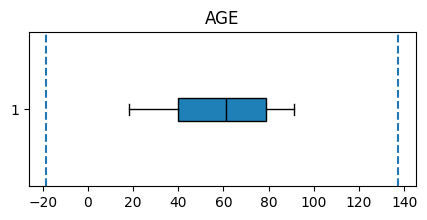


Variable ICU_LOS_HOURS has 307 outliers.


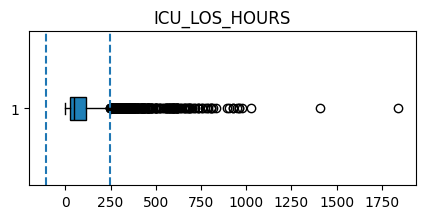


Variable MEAN_MAP has 362 outliers.


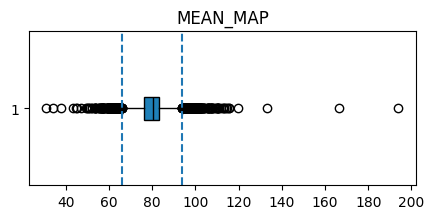


Variable MEAN_SPO2 has 70 outliers.


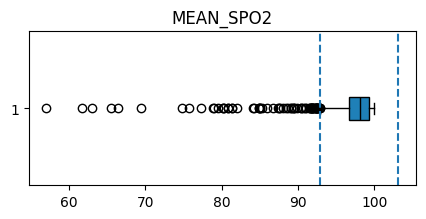


Variable SODIUM has 151 outliers.


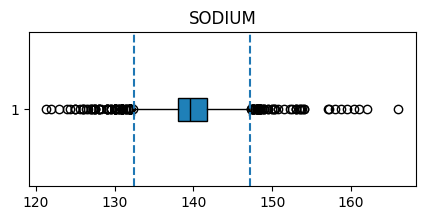


Variable HEMOGLOBIN has 15 outliers.


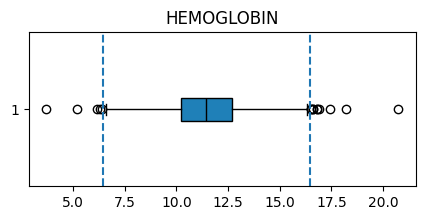

In [33]:
palette = cm.get_cmap("YlGnBu", 4)

for col in outlier_cols:
    lower, upper = iqr_limits(df[col])
    print(
        "\nVariable",
        col,
        "has",
        ((df[col] < lower) | (df[col] > upper)).sum(),
        "outliers.",
    )
    plt.figure(figsize=(5, 2))
    plt.boxplot(
        df[col],
        vert=False,
        patch_artist=True,
        boxprops=dict(facecolor=palette(2)),
        medianprops=dict(color="black"),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black"),
    )
    plt.axvline(lower, linestyle="--")
    plt.axvline(upper, linestyle="--")
    plt.title(col)
    plt.savefig(f"figures/{col}_boxplot.png", bbox_inches="tight", dpi=300)
    plt.show()

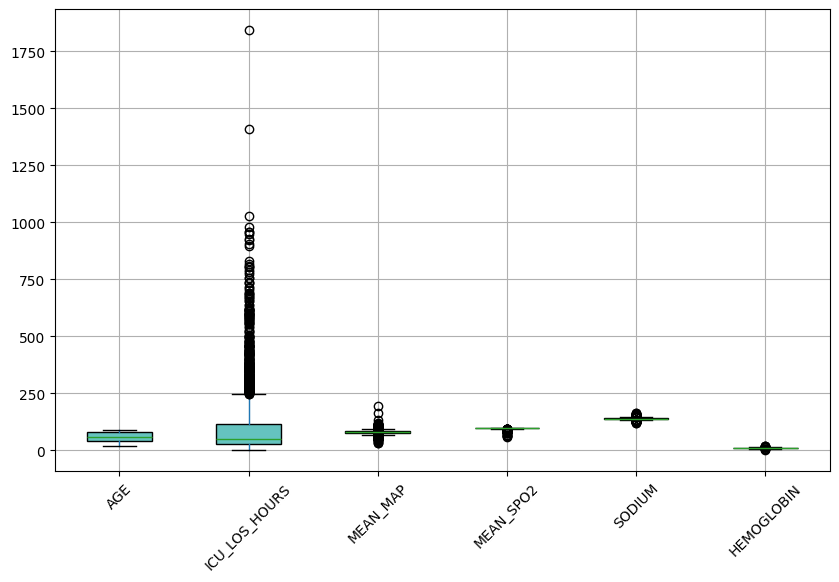

In [34]:
plt.figure(figsize=(10, 6))
df[outlier_cols].boxplot(
    patch_artist=True, boxprops=dict(facecolor=sns.color_palette("YlGnBu")[2])
)
plt.xticks(rotation=45)
plt.savefig(f"figures/overall_boxplots.png", bbox_inches="tight", dpi=300)
plt.show()

Outliers were assessed using the interquartile range (IQR) method and visualized using boxplots. Extreme but physiologically plausible values were retained in the analysis.

**Data Balance**

Data balance was assessed for key demographic and clinical variables. Particular attention was given to patient sex (female vs. male) and in-hospital mortality (survival vs. death), as these are binary variables with potential class imbalance. Due to the nature of the study, data balance was not evaluated for the mechanical ventilation variable. In addition, patients were stratified into age groups in order to assess the distribution of data across the age spectrum.

In [35]:
print(df["GENDER"].value_counts(normalize=True) * 100)

GENDER
M    62.297496
F    37.702504
Name: proportion, dtype: float64


In [36]:
print(df["IN_HOSPITAL_MORTALITY"].value_counts(normalize=True) * 100)

IN_HOSPITAL_MORTALITY
0    84.462445
1    15.537555
Name: proportion, dtype: Float64


In [37]:
df["AGE_GROUP"] = pd.cut(
    df["AGE"],
    bins=[0, 30, 40, 50, 60, 70, 80, 120],
    labels=["<30", "30-39", "40-49", "50–59", "60–69", "70-79", "≥80"],
)

print(df["AGE_GROUP"].value_counts(normalize=True) * 100)

AGE_GROUP
≥80      22.643594
<30      17.120766
70-79    16.494845
50–59    12.776141
40-49    11.524300
60–69    11.303387
30-39     8.136966
Name: proportion, dtype: float64


In [38]:
print("Percentage of deceased/alive patients grouped by gender:")
display(pd.crosstab(df["GENDER"], df["IN_HOSPITAL_MORTALITY"], normalize="index") * 100)

Percentage of deceased/alive patients grouped by gender:


IN_HOSPITAL_MORTALITY,0,1
GENDER,,
F,82.519531,17.480469
M,85.638298,14.361702


In [39]:
print("Amount of deceased/alive patients grouped by gender:")
display(pd.crosstab(df["GENDER"], df["IN_HOSPITAL_MORTALITY"]))

Amount of deceased/alive patients grouped by gender:


IN_HOSPITAL_MORTALITY,0,1
GENDER,,
F,845,179
M,1449,243


In [40]:
print("Amount of deceased/alive patients grouped by age group:")
display(pd.crosstab(df["AGE_GROUP"], df["IN_HOSPITAL_MORTALITY"]))

Amount of deceased/alive patients grouped by age group:


IN_HOSPITAL_MORTALITY,0,1
AGE_GROUP,,
<30,428,37
30-39,205,16
40-49,282,31
50–59,308,39
60–69,254,53
70-79,349,99
≥80,468,147


The study cohort consisted predominantly of male patients (62.3%). In-hospital mortality occurred in 15.5% of cases, indicating a moderate class imbalance. Age groups were reasonably balanced, with a higher proportion of patients aged ≥80 years (22.6% of the cohort).
Mortality increased markedly with advancing age, reaching its highest level among the oldest patients. Although male patients were more numerous, mortality rates were comparable between males and females. For clearer interpretation, these results were summarized in a unified table and accompanying visualizations

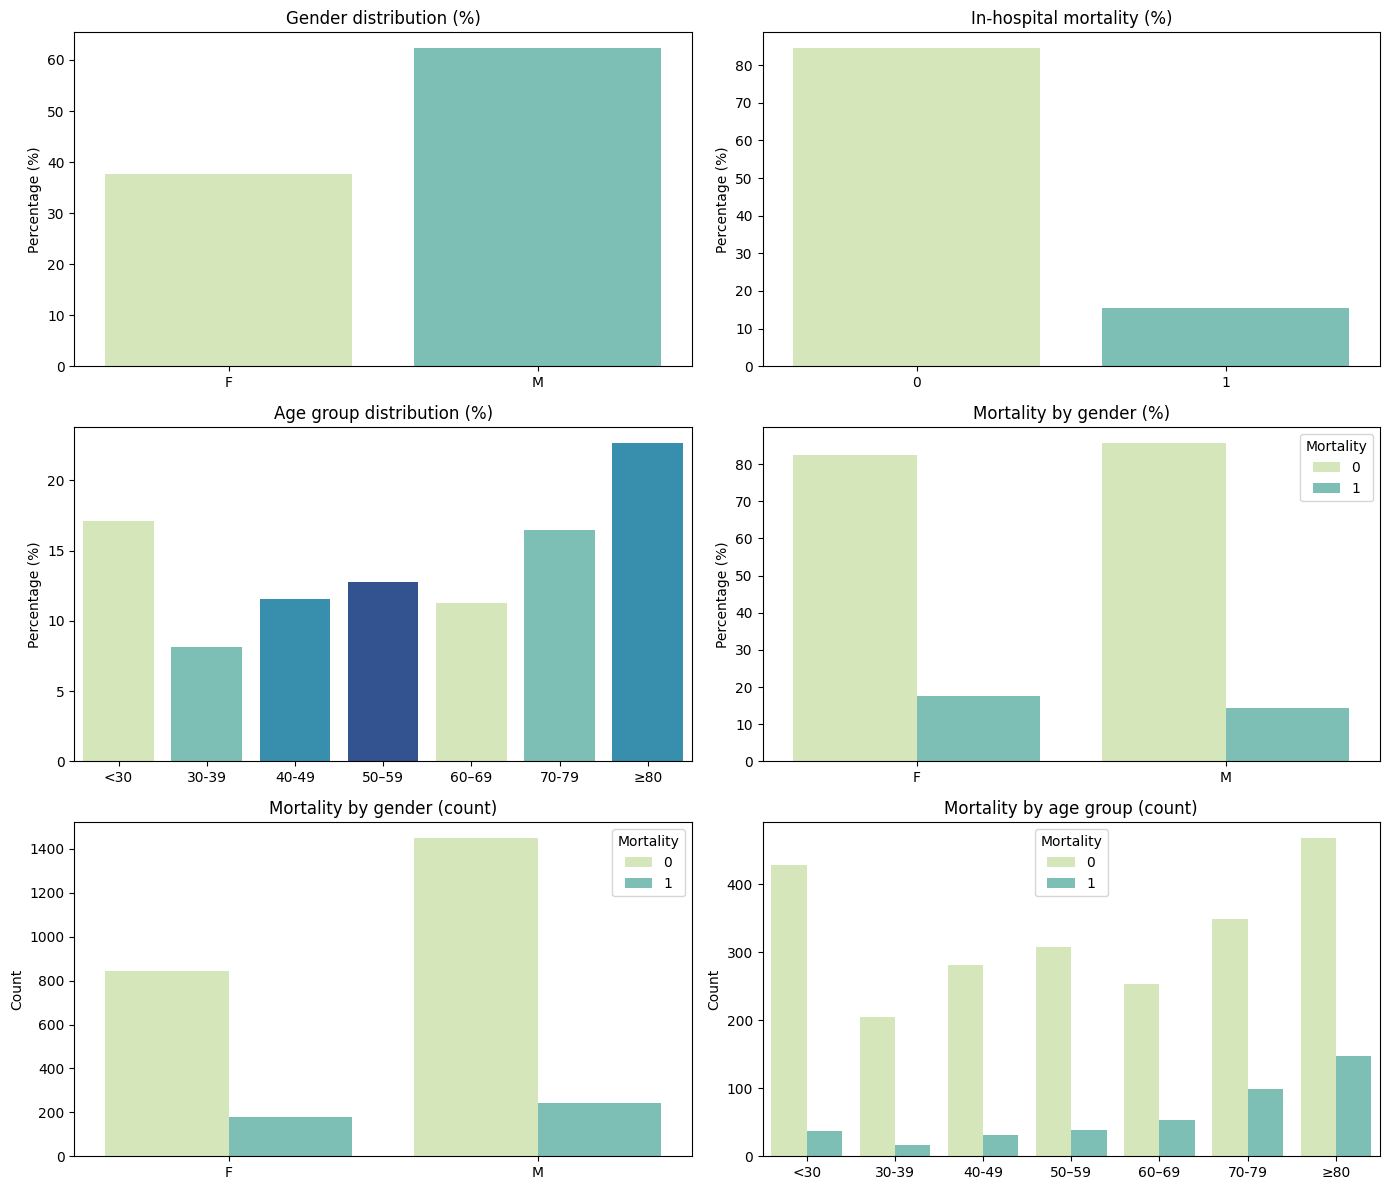

In [41]:
gender_mortality_cnt = (
    pd.crosstab(df["GENDER"], df["IN_HOSPITAL_MORTALITY"])
    .reset_index()
    .melt(id_vars="GENDER", var_name="IN_HOSPITAL_MORTALITY", value_name="COUNT")
)

age_mortality_cnt = (
    pd.crosstab(df["AGE_GROUP"], df["IN_HOSPITAL_MORTALITY"])
    .reset_index()
    .melt(id_vars="AGE_GROUP", var_name="IN_HOSPITAL_MORTALITY", value_name="COUNT")
)

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

palette = sns.color_palette("YlGnBu", n_colors=4)

# Gender distribution (%)
gender_pct = df["GENDER"].value_counts(normalize=True).mul(100).reset_index()
gender_pct.columns = ["GENDER", "PERCENT"]

sns.barplot(data=gender_pct, x="GENDER", y="PERCENT", palette=palette, ax=axes[0])
axes[0].set_title("Gender distribution (%)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Percentage (%)")

# In-hospital mortality (%)
mortality_pct = (
    df["IN_HOSPITAL_MORTALITY"].value_counts(normalize=True).mul(100).reset_index()
)
mortality_pct.columns = ["IN_HOSPITAL_MORTALITY", "PERCENT"]

sns.barplot(
    data=mortality_pct,
    x="IN_HOSPITAL_MORTALITY",
    y="PERCENT",
    palette=palette,
    ax=axes[1],
)
axes[1].set_title("In-hospital mortality (%)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Percentage (%)")

# Age group distribution (%)
age_pct = (
    df["AGE_GROUP"].value_counts(normalize=True).mul(100).sort_index().reset_index()
)
age_pct.columns = ["AGE_GROUP", "PERCENT"]

sns.barplot(data=age_pct, x="AGE_GROUP", y="PERCENT", palette=palette, ax=axes[2])
axes[2].set_title("Age group distribution (%)")
axes[2].set_xlabel("")
axes[2].set_ylabel("Percentage (%)")
axes[2].tick_params(axis="x", rotation=0)

# Mortality by gender (%)
gender_mortality_pct = (
    pd.crosstab(df["GENDER"], df["IN_HOSPITAL_MORTALITY"], normalize="index")
    .mul(100)
    .reset_index()
    .melt(id_vars="GENDER", var_name="IN_HOSPITAL_MORTALITY", value_name="PERCENT")
)

sns.barplot(
    data=gender_mortality_pct,
    x="GENDER",
    y="PERCENT",
    hue="IN_HOSPITAL_MORTALITY",
    palette=palette,
    ax=axes[3],
)
axes[3].set_title("Mortality by gender (%)")
axes[3].set_xlabel("")
axes[3].set_ylabel("Percentage (%)")
axes[3].legend(title="Mortality")

# Mortality by gender (count)
gender_mortality_cnt = (
    pd.crosstab(df["GENDER"], df["IN_HOSPITAL_MORTALITY"])
    .reset_index()
    .melt(id_vars="GENDER", var_name="IN_HOSPITAL_MORTALITY", value_name="COUNT")
)

sns.barplot(
    data=gender_mortality_cnt,
    x="GENDER",
    y="COUNT",
    hue="IN_HOSPITAL_MORTALITY",
    palette=palette,
    ax=axes[4],
)
axes[4].set_title("Mortality by gender (count)")
axes[4].set_xlabel("")
axes[4].set_ylabel("Count")
axes[4].legend(title="Mortality")

# Mortality by age group (count)
sns.barplot(
    data=age_mortality_cnt,
    x="AGE_GROUP",
    y="COUNT",
    hue="IN_HOSPITAL_MORTALITY",
    palette=palette,
    ax=axes[5],
)
axes[5].set_title("Mortality by age group (count)")
axes[5].set_xlabel("")
axes[5].set_ylabel("Count")
axes[5].tick_params(axis="x", rotation=0)
axes[5].legend(title="Mortality")
plt.tight_layout()
plt.savefig("figures/gender_age_mortality_overview.png", dpi=300, bbox_inches="tight")
plt.show()

**Correlation analysis**

We will now briefly look at the correlations to see which columns would not be useful for the ML model, due to being highly correlated with one another

In [42]:
# Set a threshold
threshold = 0.7

# Create a matrix of Pearson correlations
corr = df.corr(numeric_only=True)
np.fill_diagonal(
    corr.values, 0
)  # change the 100% correlations of the column with itself to 0

mask = corr.abs() >= threshold
cols = mask.any(axis=0)
filtered_corr = corr.loc[cols, cols]
display(filtered_corr)

,GCS_EYE,GCS_MOTOR,MIN_GCS
GCS_EYE,0.000000,0.729296,0.936270
GCS_MOTOR,0.729296,0.000000,0.708529
MIN_GCS,0.936270,0.708529,0.000000


- Using a correlation threshold of |r| ≥ 0.7, strong correlation was observed between ``GCS_MOTOR`` and ``MIN_GCS``. Given that ``MIN_GCS`` was derived from individual GCS components, it was retained so that multicollinearity is analysed in the begining of modelling section.

**Distribution shape statistics for each variable:**

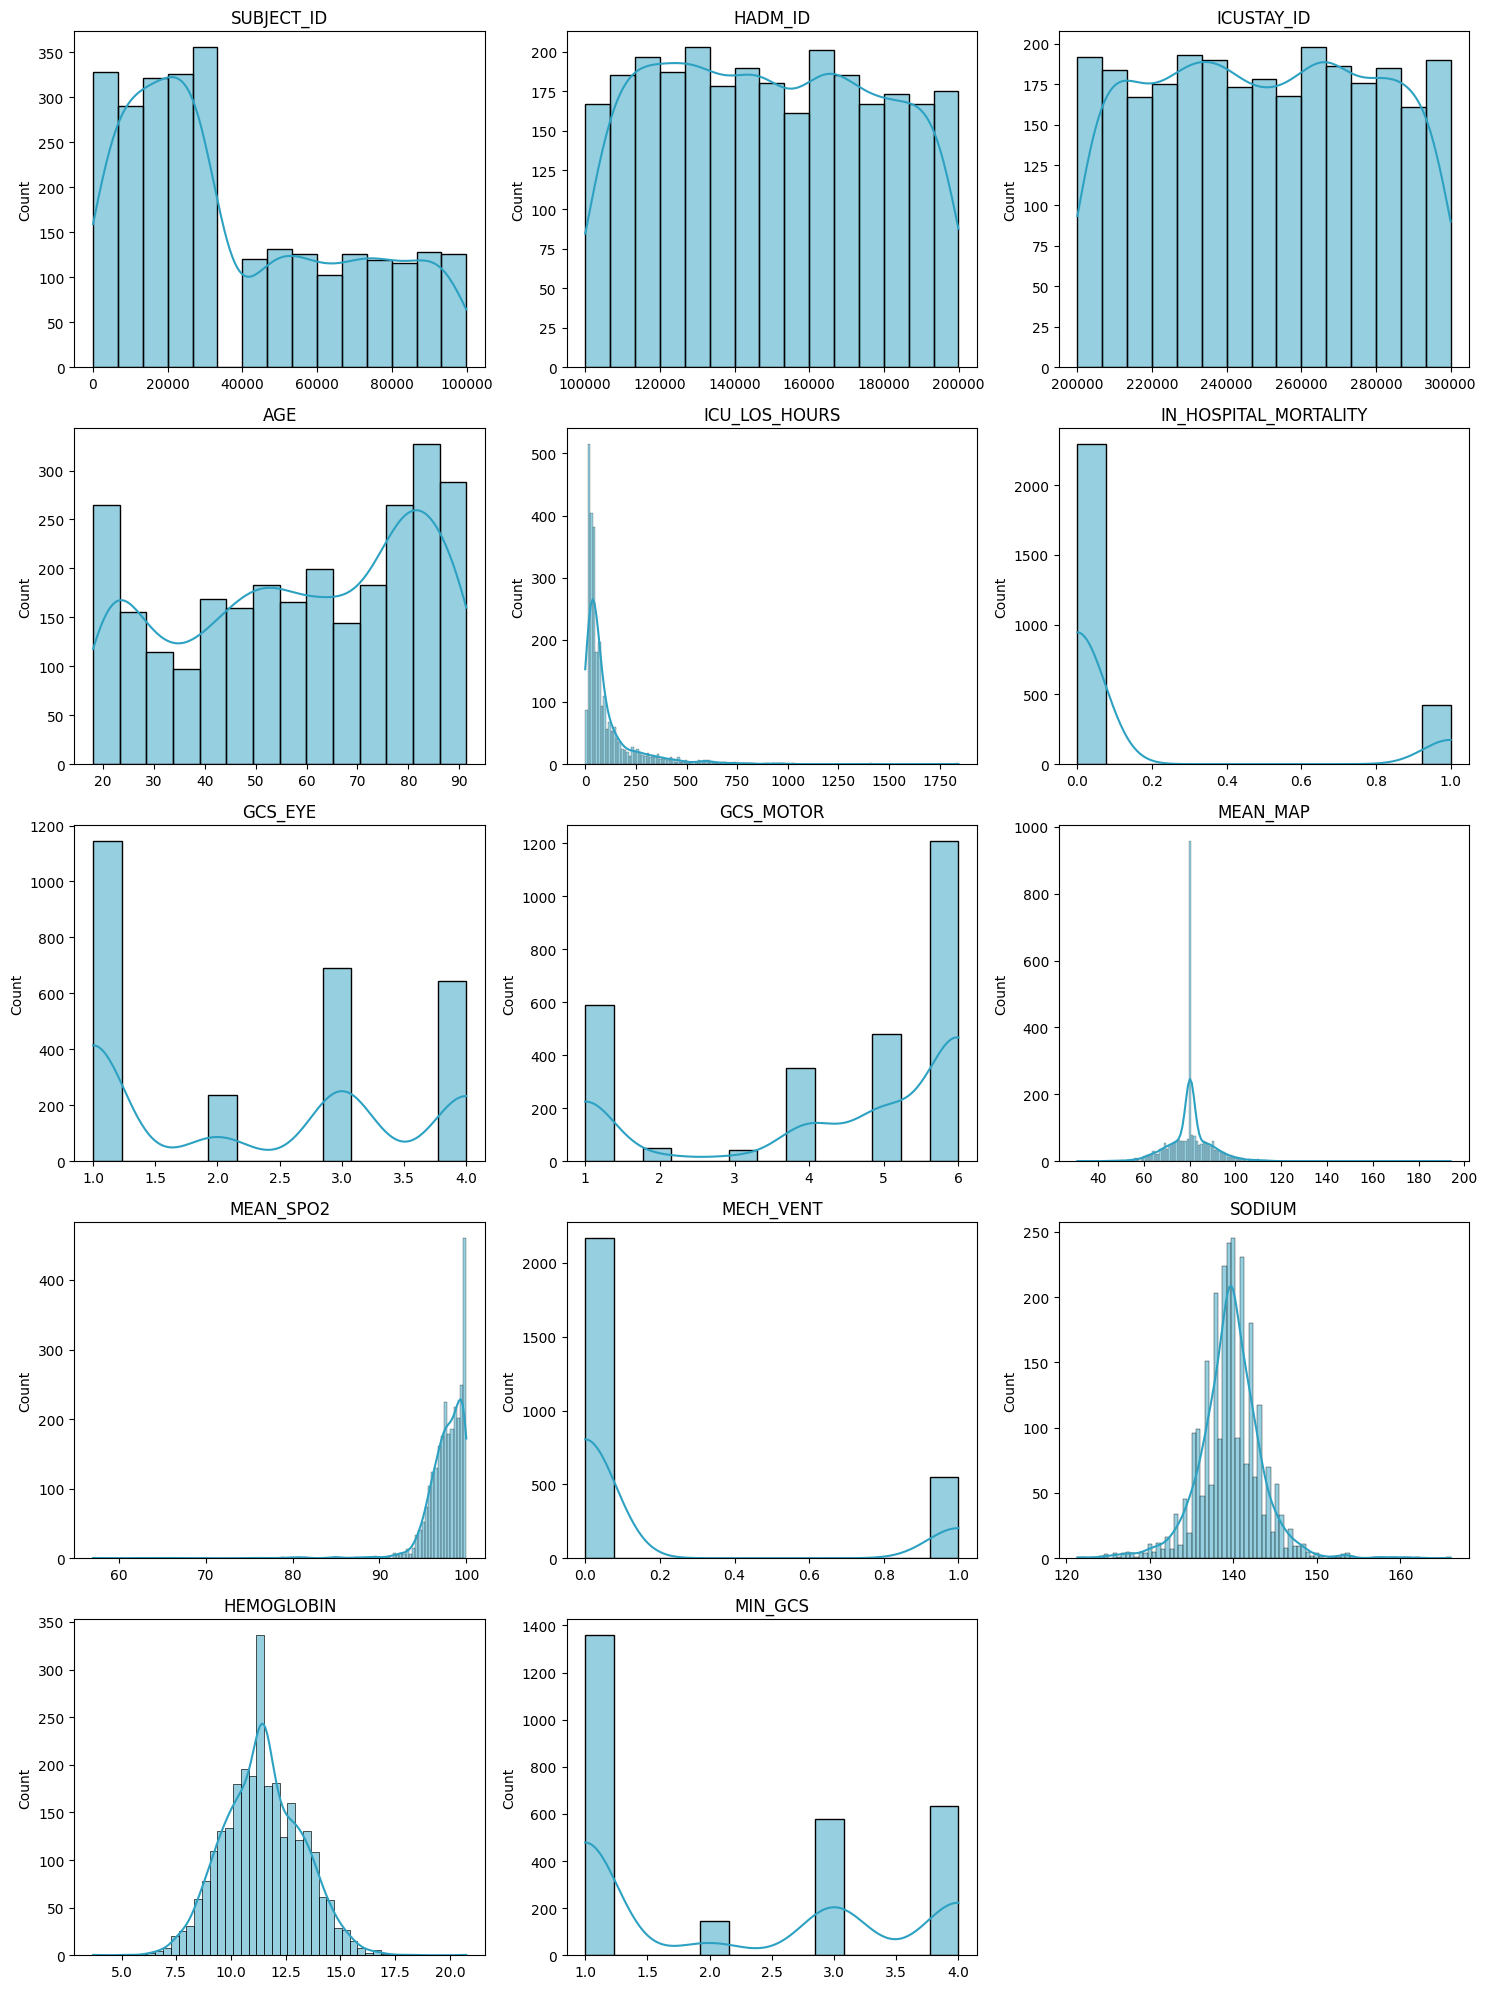

In [43]:
numeric_df = df.select_dtypes(include=["number"])

n_cols = 3
n_rows = int(np.ceil(len(numeric_df.columns) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

palette = sns.color_palette("YlGnBu")

for i, col in enumerate(numeric_df.columns):
    sns.histplot(data=numeric_df, x=col, kde=True, color=palette[3], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

# Removal of empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig("figures/numeric_variable_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

Overall, the observed distributional patterns were clinically plausible. However, further transformation may be required depending on the skewness/kurtosis assessment.

We copy the numeric variables but only maintain those relevant to skewness/kurtosis assessment.  
Identifiers and binary variables have no statistical meaning in this case.

In [44]:
numeric_df = df.select_dtypes(include=["number"])
distribution_metrics = numeric_df.drop(
    columns=[
        "SUBJECT_ID",
        "HADM_ID",
        "ICUSTAY_ID",
        "IN_HOSPITAL_MORTALITY",
        "MECH_VENT",
    ]
).copy()

In [45]:
for col in distribution_metrics.columns:
    values = distribution_metrics[col]

    skewness = skew(values, nan_policy="omit")
    kurt = kurtosis(values, nan_policy="omit")

    print(f"{col}")
    print(f"  skewness: {skewness:.2f}, kurtosis: {kurt:.2f}\n")

AGE
  skewness: -0.26, kurtosis: -1.20

ICU_LOS_HOURS
  skewness: 3.40, kurtosis: 17.77

GCS_EYE
  skewness: 0.15, kurtosis: -1.62

GCS_MOTOR
  skewness: -0.86, kurtosis: -0.89

MEAN_MAP
  skewness: 0.93, kurtosis: 11.41

MEAN_SPO2
  skewness: -5.79, kurtosis: 56.43

SODIUM
  skewness: 0.21, kurtosis: 4.40

HEMOGLOBIN
  skewness: 0.11, kurtosis: 0.20

MIN_GCS
  skewness: 0.34, kurtosis: -1.61



**Skewness and kurtosis** 
were evaluated to assess distributional properties and the presence of extreme values among numeric variables.
- Age, sodium, and hemoglobin exhibited low skewness and acceptable kurtosis, indicating approximately symmetric distributions. ICU length of stay (``ICU_LOS_HOURS``) showed pronounced right skewness and high kurtosis, reflecting a heavy-tailed distribution driven by a small number of prolonged ICU stays. Mean arterial pressure (``MEAN_MAP``) demonstrated moderate right skewness with elevated kurtosis, suggesting the presence of extreme but clinically plausible values. Mean oxygen saturation (``MEAN_SPO2``) exhibited strong left skewness and very high kurtosis, consistent with a ceiling effect. Neurological variables (GCS components and ``MIN_GCS``) displayed mild asymmetry and low kurtosis, reflecting bounded clinical scales with a predominance of lower scores.

**Strategies for handling outliers with high kurtosis:**
- A log transformation was applied to ``ICU_LOS_HOURS`` to reduce skewness and compress extreme values, thereby stabilizing variance. 
- Mild winsorization was considered for ``MEAN_MAP`` to limit the influence of extreme observations while retaining all data points. These approaches help improve coefficient stability and inference reliability in logistic regression models.

**Reference(s):**

- https://medium.com/@post.gourang/the-art-of-handling-outlier-153215d49460
- https://en.wikipedia.org/wiki/Log_transformation_(statistics)
- https://www.datacamp.com/tutorial/winsorized-mean

**Skewed variables that need transforming:** 

1. Log transformation: ``ICU_LOS_HOURS`` (very skewed, heavy-tailed). Log transform stabilizes variance and reduces leverage of extreme stays.
2. Mild winsorization: ``MEAN_MAP`` (moderate skew, heavy tails)

For a logistic regression model, reducing skew and influence of extreme values helps stabilize coefficients and p-values.

In [46]:
# Check possitivity (required for log transformation)
print("Number of non-positive values: ", (df["ICU_LOS_HOURS"] <= 0).sum())

# Log Transformation
df["log_ICU_LOS"] = np.log(df["ICU_LOS_HOURS"] + 1)

print("ICU_LOS log transformation: ")
print(f"- Skew: {skew(df['ICU_LOS_HOURS']):.2f} to {skew(df['log_ICU_LOS']):.2f}")
print(
    f"- Kurtosis: {kurtosis(df['ICU_LOS_HOURS']):.2f} to {kurtosis(df['log_ICU_LOS']):.2f}"
)

Number of non-positive values:  0
ICU_LOS log transformation: 
- Skew: 3.40 to 0.36
- Kurtosis: 17.77 to 0.14


``ICU_LOS`` was effectively normalized by log transformation. The resulting distribution is almost symmetric and extreme heavy tails are almost normla tails (0.19), meaning extreme ICU stays no longer dominate the model.

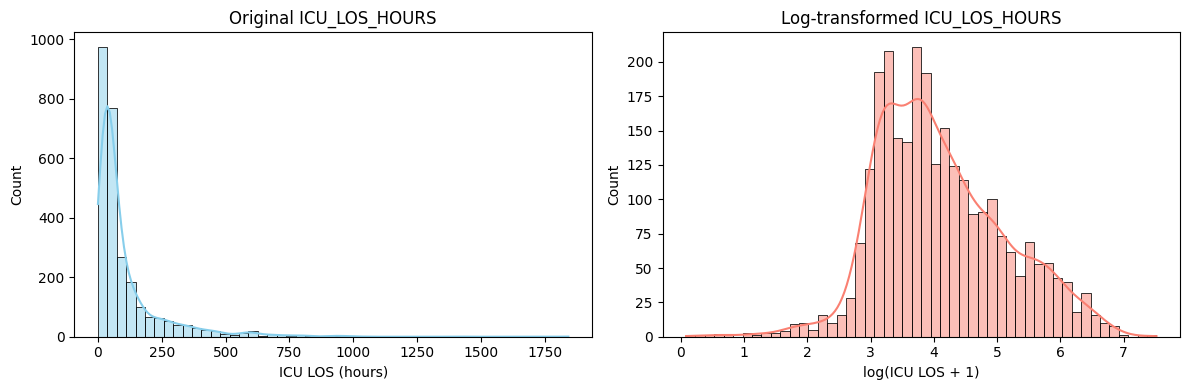

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["ICU_LOS_HOURS"], bins=50, kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Original ICU_LOS_HOURS")
axes[0].set_xlabel("ICU LOS (hours)")

sns.histplot(df["log_ICU_LOS"], bins=50, kde=True, ax=axes[1], color="salmon")
axes[1].set_title("Log-transformed ICU_LOS_HOURS")
axes[1].set_xlabel("log(ICU LOS + 1)")

plt.tight_layout()
plt.savefig(
    "figures/icu_los_original_vs_log.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [48]:
# Mild winsorization at 1st and 99th percentiles
lower, upper = df["MEAN_MAP"].quantile([0.01, 0.99])
df["MEAN_MAP_w"] = df["MEAN_MAP"].clip(lower=lower, upper=upper)

print("MEAN_MAP mild winsorization: ")
print(f"- Skew: {skew(df['MEAN_MAP']):.2f} to {skew(df['MEAN_MAP_w']):.2f}")
print(f"- Kurtosis: {kurtosis(df['MEAN_MAP']):.2f} to {kurtosis(df['MEAN_MAP_w']):.2f}")

MEAN_MAP mild winsorization: 
- Skew: 0.93 to 0.14
- Kurtosis: 11.41 to 1.07


With the mild winsorization, ``MEAN_MAP``'s skewness is corrected, leaving a nearly symmetric distribution. Heavy tails were reduced to slightly heavier than normal, meaning that extreme outliers no longer influence the distribution. Consequently, model coefficients will not be distorted by rare high or lows MAP values.

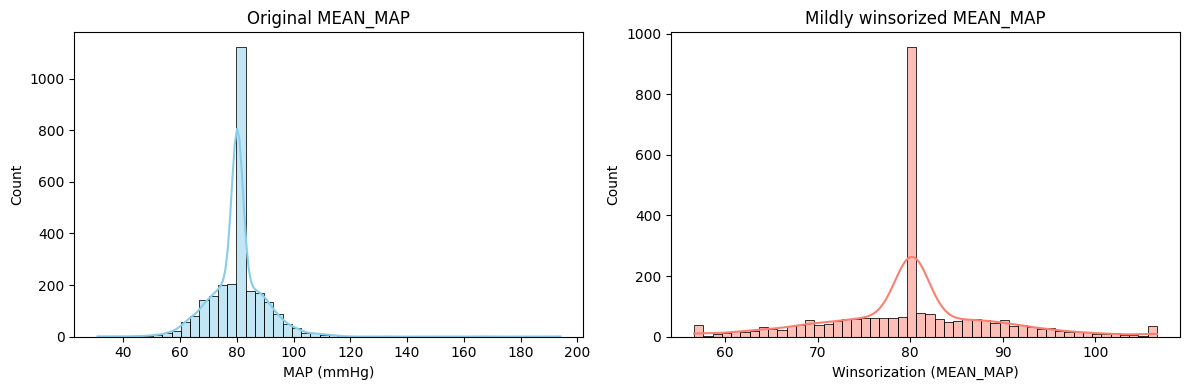

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["MEAN_MAP"], bins=50, kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Original MEAN_MAP")
axes[0].set_xlabel("MAP (mmHg)")

sns.histplot(df["MEAN_MAP_w"], bins=50, kde=True, ax=axes[1], color="salmon")
axes[1].set_title(f"Mildly winsorized MEAN_MAP")
axes[1].set_xlabel("Winsorization (MEAN_MAP)")

plt.tight_layout()
plt.savefig(
    "figures/mean_map_original_vs_winsorized.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

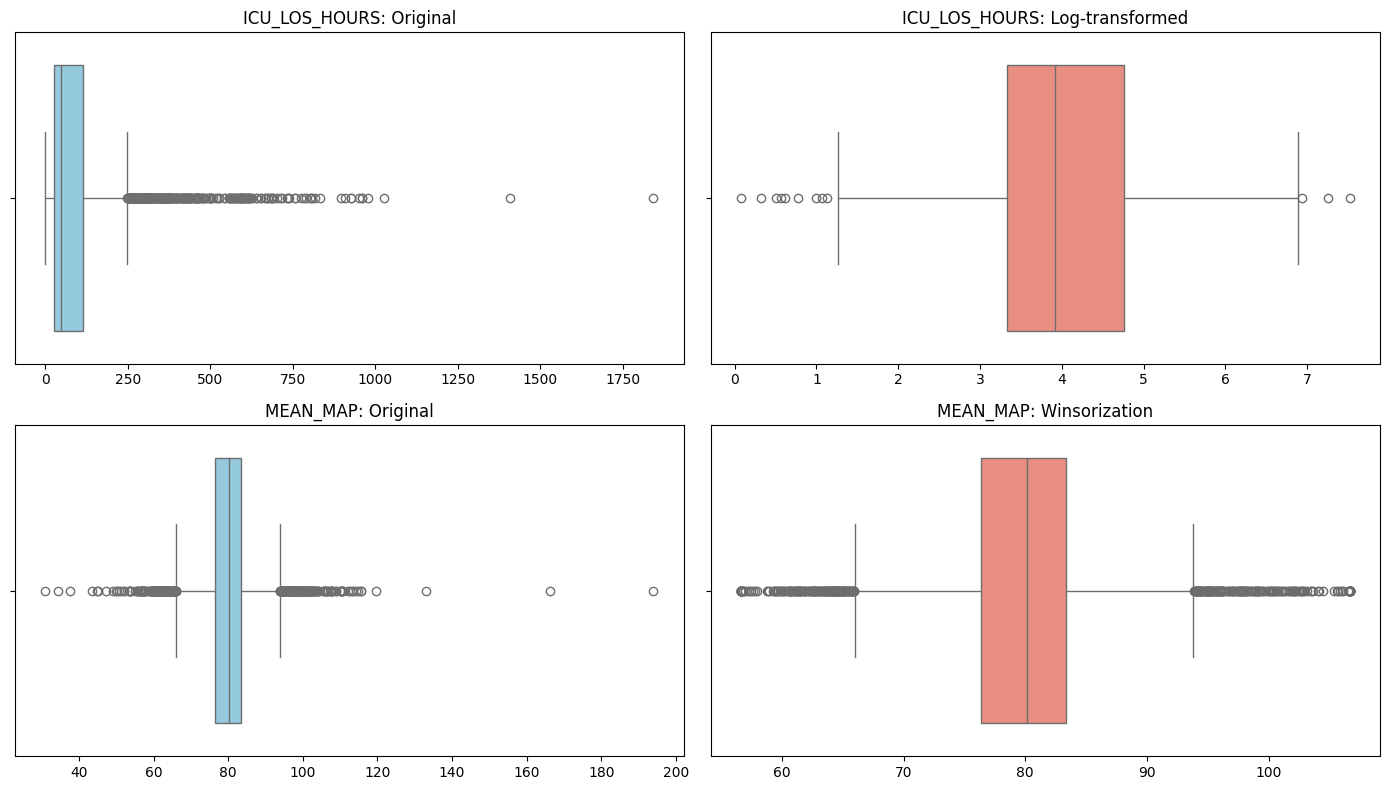

In [50]:
# 4 variables × 2 columns (original vs transformed)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Row 1: ICU_LOS_HOURS
sns.boxplot(x=df["ICU_LOS_HOURS"], ax=axes[0, 0], color="skyblue")
axes[0, 0].set_title("ICU_LOS_HOURS: Original")
axes[0, 0].set_xlabel("")
sns.boxplot(x=df["log_ICU_LOS"], ax=axes[0, 1], color="salmon")
axes[0, 1].set_title("ICU_LOS_HOURS: Log-transformed")
axes[0, 1].set_xlabel("")

# Row 2: MEAN_MAP
sns.boxplot(x=df["MEAN_MAP"], ax=axes[1, 0], color="skyblue")
axes[1, 0].set_title("MEAN_MAP: Original")
axes[1, 0].set_xlabel("")
sns.boxplot(x=df["MEAN_MAP_w"], ax=axes[1, 1], color="salmon")
axes[1, 1].set_title("MEAN_MAP: Winsorization")
axes[1, 1].set_xlabel("")

plt.tight_layout()
plt.savefig(
    "figures/icu_los_map_original_vs_transformed_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [51]:
# Suppress the specific UserWarning from numpy
warnings.filterwarnings("ignore", message=".*partition.*MaskedArray.*")

# List of transformed variables
transformed_vars = ["log_ICU_LOS", "MEAN_MAP_w"]

for var in transformed_vars:
    series = df[var]
    lower, upper = iqr_limits(series)
    outliers = series[(series < lower) | (series > upper)]
    print(f"{var}: {len(outliers)} outliers (IQR method)")

log_ICU_LOS: 12 outliers (IQR method)
MEAN_MAP_w: 362 outliers (IQR method)


**Decision on outliers:**  

| Variable       | Outliers Before | Outliers (IQR method) | Comment                                                                                                                                     |
| -------------- | --------------- | --------------------- | ------------------------------------------------------------------------------------------------------------------------------------------- |
| ICU_LOS    | 307             | 12                    | Log transform reduced extreme values dramatically (lower skewness), stabilize variance, meaning they will have less influence on the final weighted ridge logistic regression.                                             |
| MEAN_MAP    | 362             | 362                  | Many values are outside the typical clinical ranges, but not extreme enough to be clipped by mild winsorization. Further winsorization is unnecessary since Ridge regression will mitigate outliers leverage. |

``ICU_LOS`` is safe to include after log transform because outlier influence minimized. As for ``MEAN_MAP``, it is recommended to be keep as the original since ridge regression will handle remaining heavy tails (outliers) due to L2 penalty.

In [52]:
df = df.drop(columns=["MEAN_MAP_w"])

**ICD9 Distribution**

The distribution of ICD-9 codes within the dataset was analyzed to identify the most common types of traumatic brain injuries represented. This analysis helps to understand the prevalence of different injury types.

In [53]:
df["ICD9_3DIGIT"] = (
    df["ICD9_CODES"]
    .astype(str)
    .apply(lambda x: ";".join(sorted(set(code[:3] for code in x.split(";")))))
)

icd9_map = {
    "800": "Fracture of vault of skull",
    "801": "Fracture of base of skull",
    "802": "Fracture of face bones",
    "803": "Other and unqualified skull fractures",
    "804": "Multiple fractures involving skull or face",
    "850": "Concussion",
    "851": "Cerebral laceration and contusion",
    "852": "Subarachnoid, subdural, and extradural hemorrhage",
    "853": "Other and unspecified intracranial hemorrhage",
    "854": "Intracranial injury of other and unspecified nature",
}

df["ICD9_DESCRIPTION"] = df["ICD9_3DIGIT"].apply(
    lambda x: ";".join(
        dict.fromkeys(  # removes duplicates, preserves order
            icd9_map.get(code, "Unknown ICD9 code") for code in x.split(";")
        )
    )
)

icd9_counts = (
    df["ICD9_DESCRIPTION"]
    .str.split(";")
    .explode()  # one description per row
    .value_counts()
    .reset_index()
)

icd9_counts.columns = ["ICD9_DESCRIPTION", "COUNT"]
display(icd9_counts)

,ICD9_DESCRIPTION,COUNT
0,"Subarachnoid, subdural, and extradural hemorrhage",1164
1,Fracture of base of skull,629
2,Fracture of face bones,609
3,Cerebral laceration and contusion,321
4,Other and unspecified intracranial hemorrhage,205
5,Fracture of vault of skull,153
6,Concussion,94
7,Other and unqualified skull fractures,85
8,Multiple fractures involving skull or face,47
9,Intracranial injury of other and unspecified n...,40


In [54]:
df["ICD9_3DIGIT"] = (
    df["ICD9_CODES"]
    .astype(str)
    .apply(lambda x: ";".join(sorted(set(code[:3] for code in x.split(";")))))
)

df["ICD9_DESCRIPTION"] = df["ICD9_3DIGIT"].apply(
    lambda x: ";".join(
        dict.fromkeys(icd9_map.get(code, "Unknown ICD9 code") for code in x.split(";"))
    )
)

icd9_counts = (
    df[["ICD9_DESCRIPTION", "IN_HOSPITAL_MORTALITY"]]
    .assign(ICD9_DESCRIPTION=lambda x: x["ICD9_DESCRIPTION"].str.split(";"))
    .explode("ICD9_DESCRIPTION")
    .groupby("ICD9_DESCRIPTION", as_index=False)
    .agg(
        COUNT=("ICD9_DESCRIPTION", "size"),
        MORTALITY_RATE=("IN_HOSPITAL_MORTALITY", "mean"),
    )
)

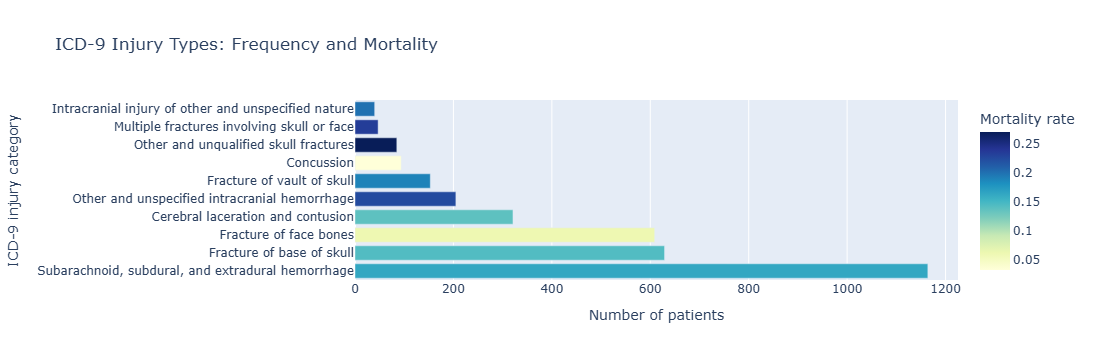

In [55]:
fig = px.bar(
    icd9_counts.sort_values("COUNT", ascending=False),
    x="COUNT",
    y="ICD9_DESCRIPTION",
    orientation="h",
    color="MORTALITY_RATE",
    color_continuous_scale="YlGnBu",
    title="ICD-9 Injury Types: Frequency and Mortality",
)

fig.update_layout(
    xaxis_title="Number of patients",
    yaxis_title="ICD-9 injury category",
    coloraxis_colorbar_title="Mortality rate",
)

fig.show()
fig.write_html("figures/icd9_injury_types.html")

Verifying correct data cleaning:

In [56]:
cleaned_df = df.copy()

In [57]:
print(cleaned_df.shape)

(2716, 22)


In [58]:
print(cleaned_df.isna().sum())

SUBJECT_ID               0
HADM_ID                  0
ICUSTAY_ID               0
ICD9_CODES               0
GENDER                   0
AGE                      0
ICU_INTIME               0
ICU_OUTTIME              0
ICU_LOS_HOURS            0
IN_HOSPITAL_MORTALITY    0
GCS_EYE                  0
GCS_MOTOR                0
MEAN_MAP                 0
MEAN_SPO2                0
MECH_VENT                0
SODIUM                   0
HEMOGLOBIN               0
MIN_GCS                  0
AGE_GROUP                0
log_ICU_LOS              0
ICD9_3DIGIT              0
ICD9_DESCRIPTION         0
dtype: int64


In [59]:
print(cleaned_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 2716 entries, 0 to 2716
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   SUBJECT_ID             2716 non-null   int64         
 1   HADM_ID                2716 non-null   int64         
 2   ICUSTAY_ID             2716 non-null   int64         
 3   ICD9_CODES             2716 non-null   object        
 4   GENDER                 2716 non-null   category      
 5   AGE                    2716 non-null   float64       
 6   ICU_INTIME             2716 non-null   datetime64[ns]
 7   ICU_OUTTIME            2716 non-null   datetime64[ns]
 8   ICU_LOS_HOURS          2716 non-null   float64       
 9   IN_HOSPITAL_MORTALITY  2716 non-null   Int64         
 10  GCS_EYE                2716 non-null   Int64         
 11  GCS_MOTOR              2716 non-null   Int64         
 12  MEAN_MAP               2716 non-null   float64       
 13  MEAN_SPO

- Saving the cleaned dataset as a new csv file for further analysis:

In [60]:
cleaned_df.to_csv("data/cleaned_df.csv", index=False)

---
<a id='section3'></a>
# **3. Data visualization and exploratory analysis**

In [61]:
df = pd.read_csv("data/cleaned_df.csv", sep=",", na_values=["?", " ", ""])
display(df.head(2))

,SUBJECT_ID,HADM_ID,ICUSTAY_ID,ICD9_CODES,GENDER,AGE,ICU_INTIME,ICU_OUTTIME,ICU_LOS_HOURS,IN_HOSPITAL_MORTALITY,...,MEAN_MAP,MEAN_SPO2,MECH_VENT,SODIUM,HEMOGLOBIN,MIN_GCS,AGE_GROUP,log_ICU_LOS,ICD9_3DIGIT,ICD9_DESCRIPTION
0,65,143430,244776,80012,M,26.0,2132-08-10 07:13:00,2132-08-13 15:03:00,79.8236,0,...,88.641043,98.846154,0,133.0,14.6,2,<30,4.392269,800,Fracture of vault of skull
1,80,115385,256068,80416,M,43.0,2148-11-11 12:13:00,2148-11-12 16:46:00,28.5631,0,...,83.916667,97.875000,0,140.0,14.4,3,40-49,3.386527,804,Multiple fractures involving skull or face


In [62]:
print(df.columns)

Index(['SUBJECT_ID', 'HADM_ID', 'ICUSTAY_ID', 'ICD9_CODES', 'GENDER', 'AGE',
       'ICU_INTIME', 'ICU_OUTTIME', 'ICU_LOS_HOURS', 'IN_HOSPITAL_MORTALITY',
       'GCS_EYE', 'GCS_MOTOR', 'MEAN_MAP', 'MEAN_SPO2', 'MECH_VENT', 'SODIUM',
       'HEMOGLOBIN', 'MIN_GCS', 'AGE_GROUP', 'log_ICU_LOS', 'ICD9_3DIGIT',
       'ICD9_DESCRIPTION'],
      dtype='object')


In [63]:
display(df.dtypes)

SUBJECT_ID                 int64
HADM_ID                    int64
ICUSTAY_ID                 int64
ICD9_CODES                object
GENDER                    object
AGE                      float64
ICU_INTIME                object
ICU_OUTTIME               object
ICU_LOS_HOURS            float64
IN_HOSPITAL_MORTALITY      int64
GCS_EYE                    int64
GCS_MOTOR                  int64
MEAN_MAP                 float64
MEAN_SPO2                float64
MECH_VENT                  int64
SODIUM                   float64
HEMOGLOBIN               float64
MIN_GCS                    int64
AGE_GROUP                 object
log_ICU_LOS              float64
ICD9_3DIGIT               object
ICD9_DESCRIPTION          object
dtype: object

In [64]:
df["ICD9_CODES"].value_counts().head(10).values

array([297, 183,  84,  57,  56,  56,  55,  53,  49,  49])

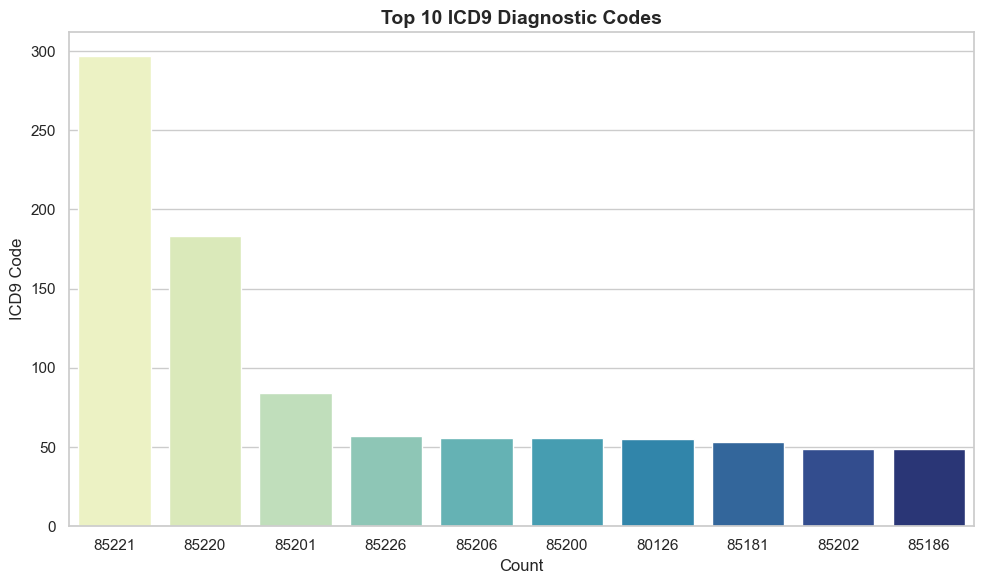

In [65]:
sns.set(style="whitegrid")

# Top 10 ICD9 codes
top_n = 10
top_icd9 = df["ICD9_CODES"].value_counts().head(top_n)

palette = sns.color_palette("YlGnBu", n_colors=10)

plt.figure(figsize=(10, 6))
sns.barplot(
    y=top_icd9.values,
    x=top_icd9.index,
    hue=top_icd9.index,
    palette=palette,
    legend=False,
)
plt.title(f"Top {top_n} ICD9 Diagnostic Codes", fontsize=14, fontweight="bold")
plt.xlabel("Count")
plt.ylabel("ICD9 Code")
plt.tight_layout()
plt.savefig(
    "figures/top_10_icd9_codes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [66]:
df["ICU_INTIME"] = pd.to_datetime(df["ICU_INTIME"])
df["ICU_OUTTIME"] = pd.to_datetime(df["ICU_OUTTIME"])

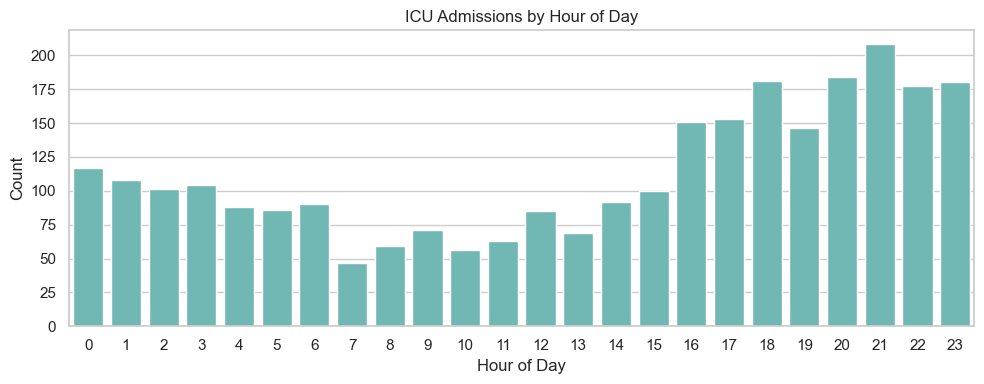

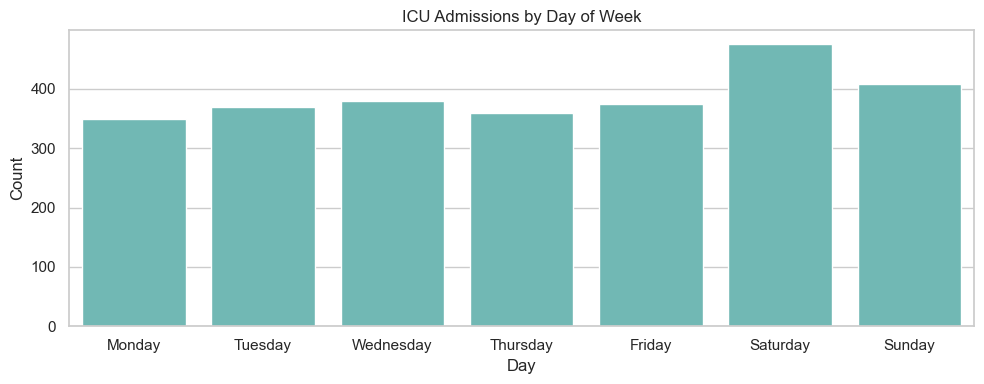

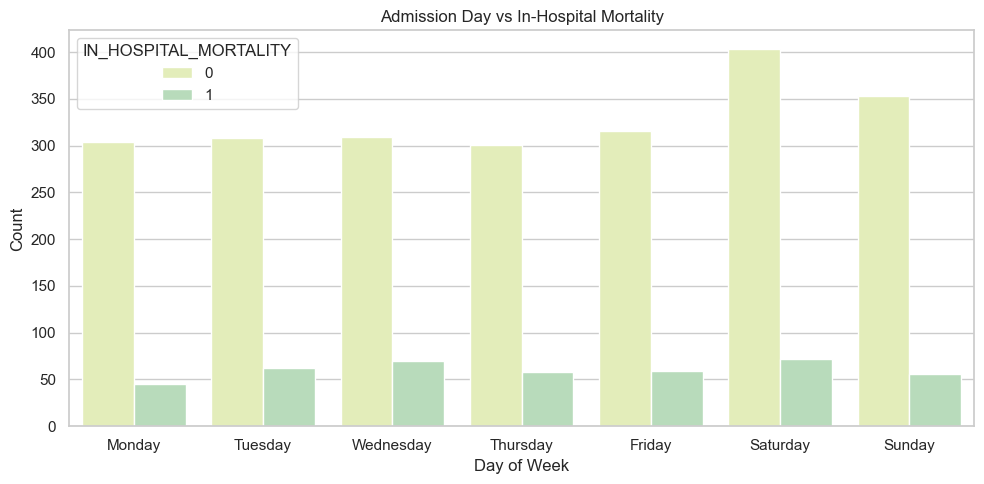

In [67]:
# Time-related features
df["admit_year"] = df["ICU_INTIME"].dt.year
df["admit_month"] = df["ICU_INTIME"].dt.month
df["admit_hour"] = df["ICU_INTIME"].dt.hour
df["admit_dayofweek"] = df["ICU_INTIME"].dt.day_name()

palette = sns.color_palette("YlGnBu")

# ICU admissions by hour of day
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="admit_hour", color=palette[2])
plt.title("ICU Admissions by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("figures/icu_admissions_by_hour.png", dpi=300, bbox_inches="tight")
plt.show()

# ICU admissions by day of week
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="admit_dayofweek", order=order, color=palette[2])
plt.title("ICU Admissions by Day of Week")
plt.xlabel("Day")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("figures/icu_admissions_by_day.png", dpi=300, bbox_inches="tight")
plt.show()

# Admission day vs in-hospital mortality
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="admit_dayofweek",
    hue="IN_HOSPITAL_MORTALITY",
    order=order,
    palette=palette,
)
plt.title("Admission Day vs In-Hospital Mortality")
plt.xlabel("Day of Week")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("figures/admit_day_vs_mortality.png", dpi=300, bbox_inches="tight")
plt.show()

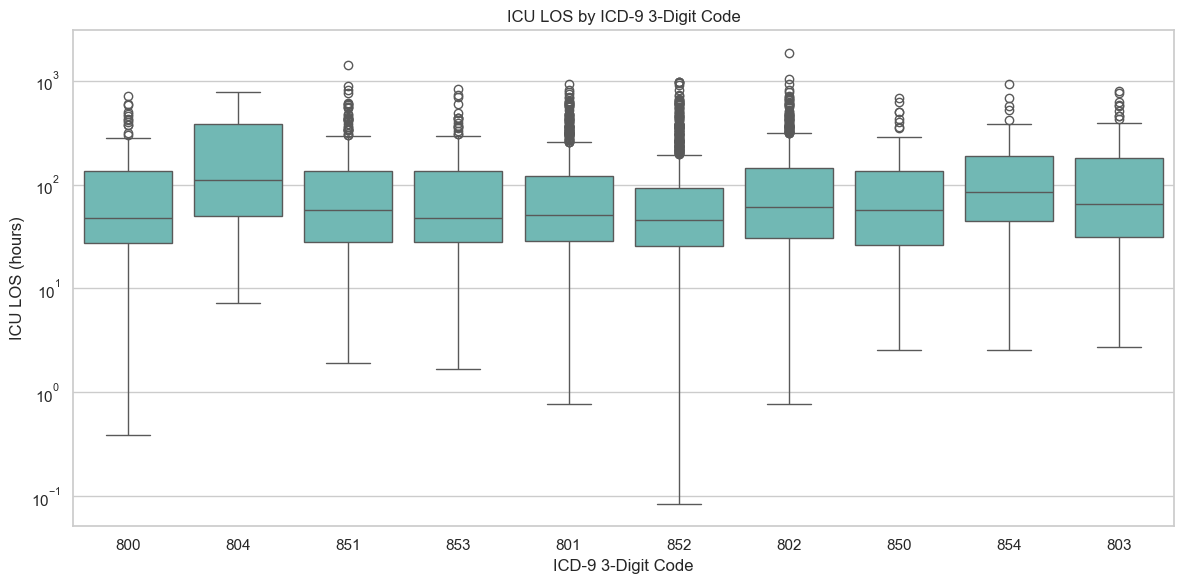

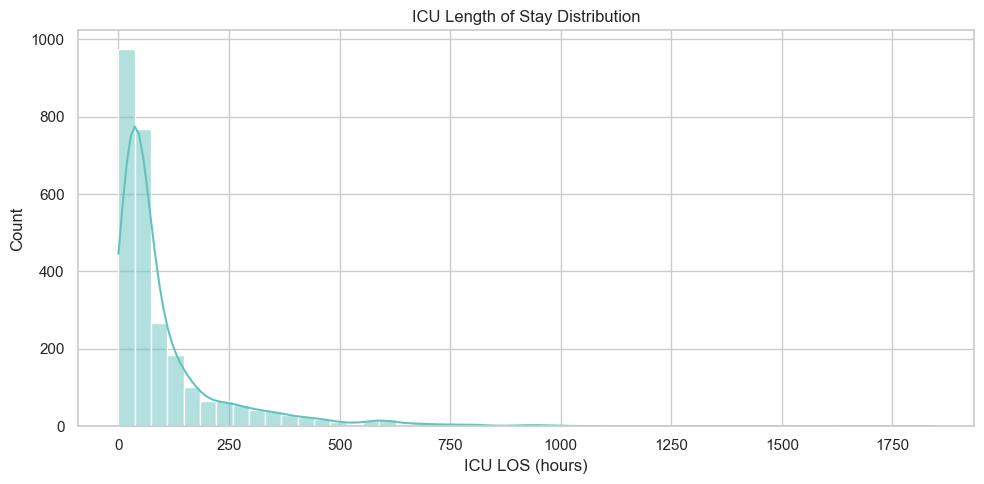

In [68]:
df_icd9_long = (
    df[["ICU_LOS_HOURS", "ICD9_3DIGIT"]]
    .assign(ICD9_3DIGIT=lambda x: x["ICD9_3DIGIT"].str.split(";"))
    .explode("ICD9_3DIGIT")
)
top_icd9_3 = df_icd9_long["ICD9_3DIGIT"].value_counts().head(10).index
df_top = df_icd9_long[df_icd9_long["ICD9_3DIGIT"].isin(top_icd9_3)]
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x="ICD9_3DIGIT", y="ICU_LOS_HOURS", color=palette[2])
plt.yscale("log")
plt.title("ICU LOS by ICD-9 3-Digit Code")
plt.xlabel("ICD-9 3-Digit Code")
plt.ylabel("ICU LOS (hours)")
plt.tight_layout()
plt.savefig("figures/icu_los_by_icd9_3digit_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

# ICU LOS distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["ICU_LOS_HOURS"], bins=50, kde=True, color=palette[2])
plt.title("ICU Length of Stay Distribution")
plt.xlabel("ICU LOS (hours)")
plt.tight_layout()
plt.savefig("figures/icu_los_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

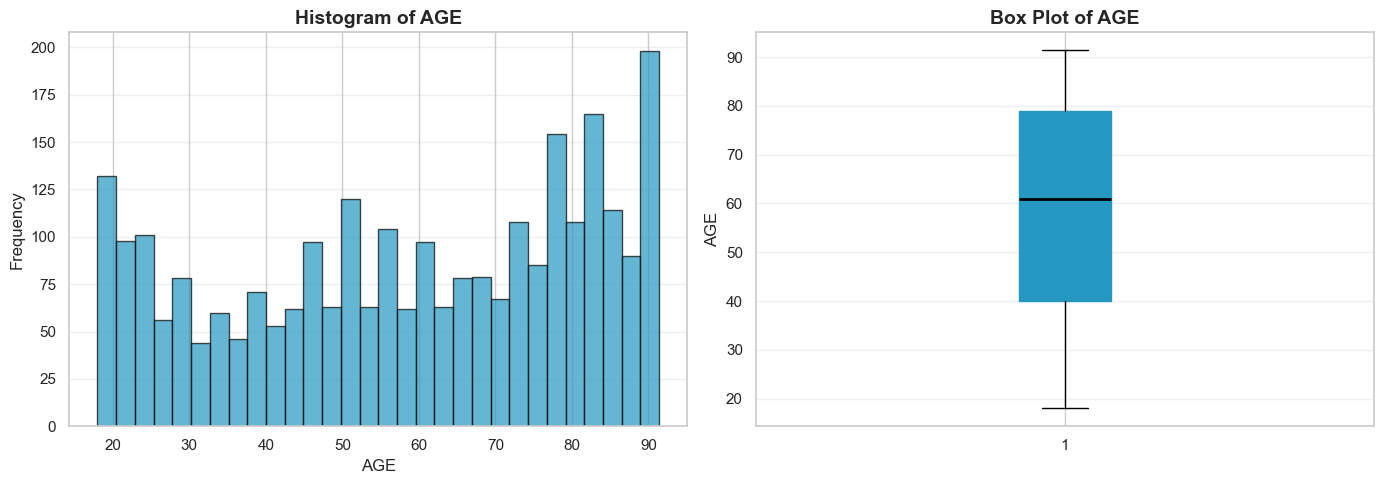

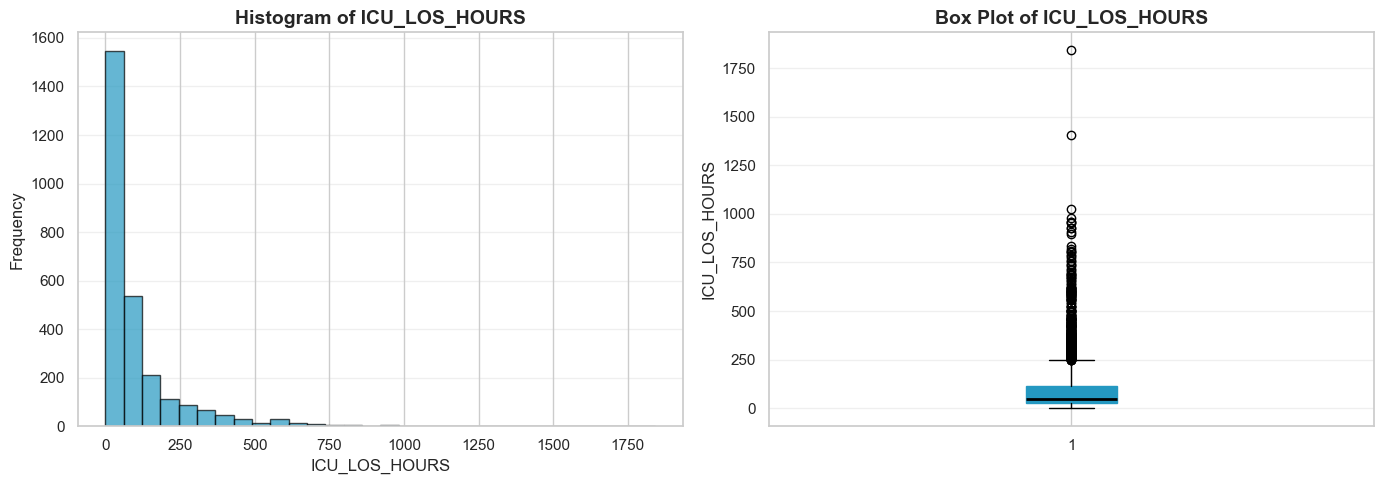

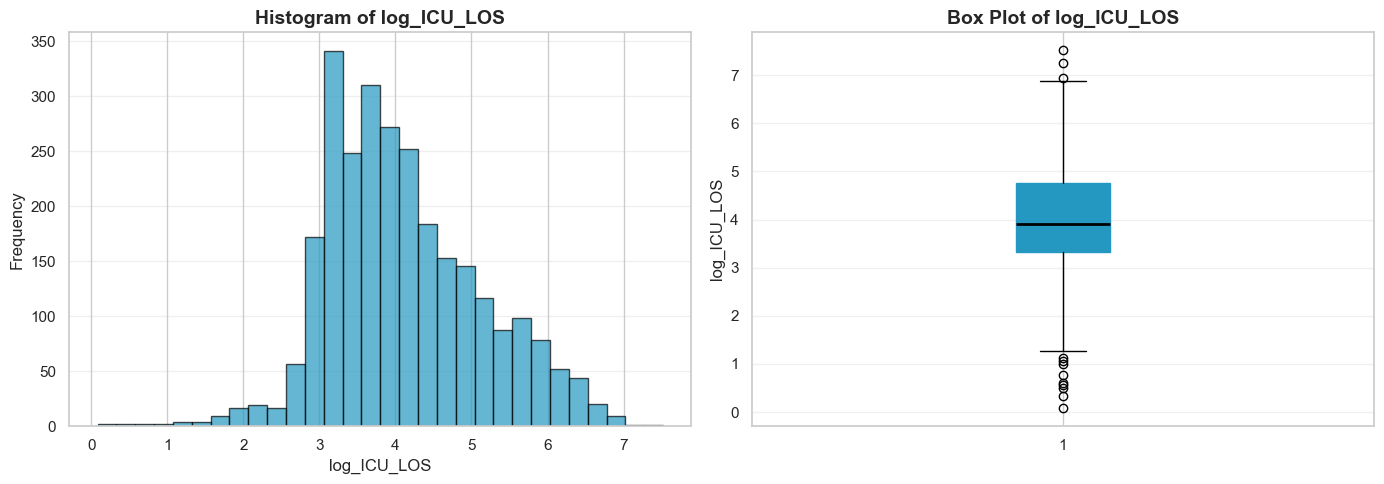

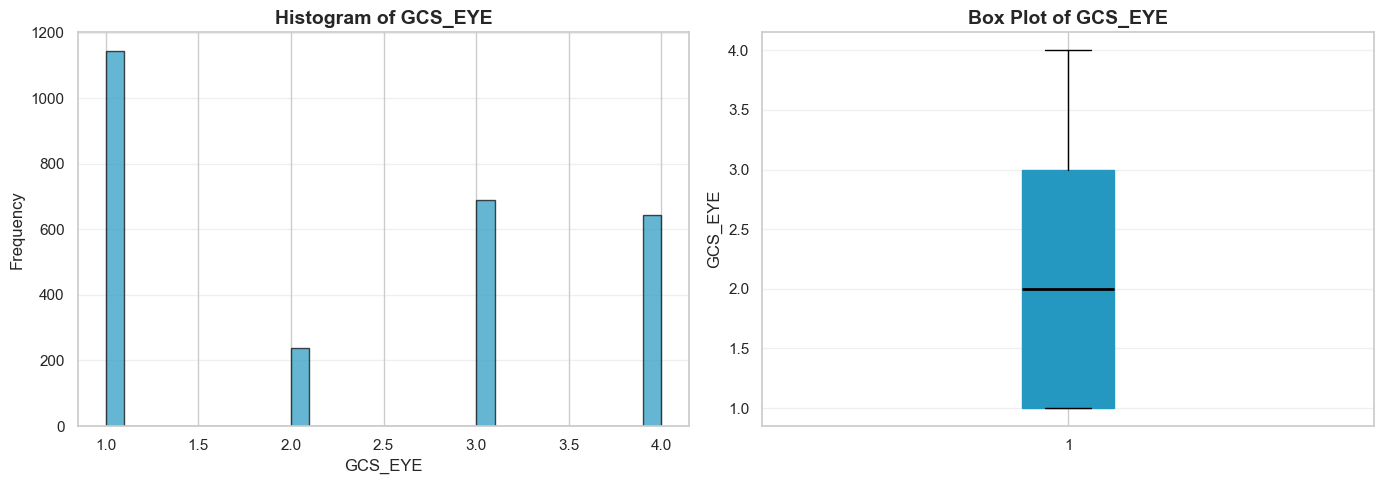

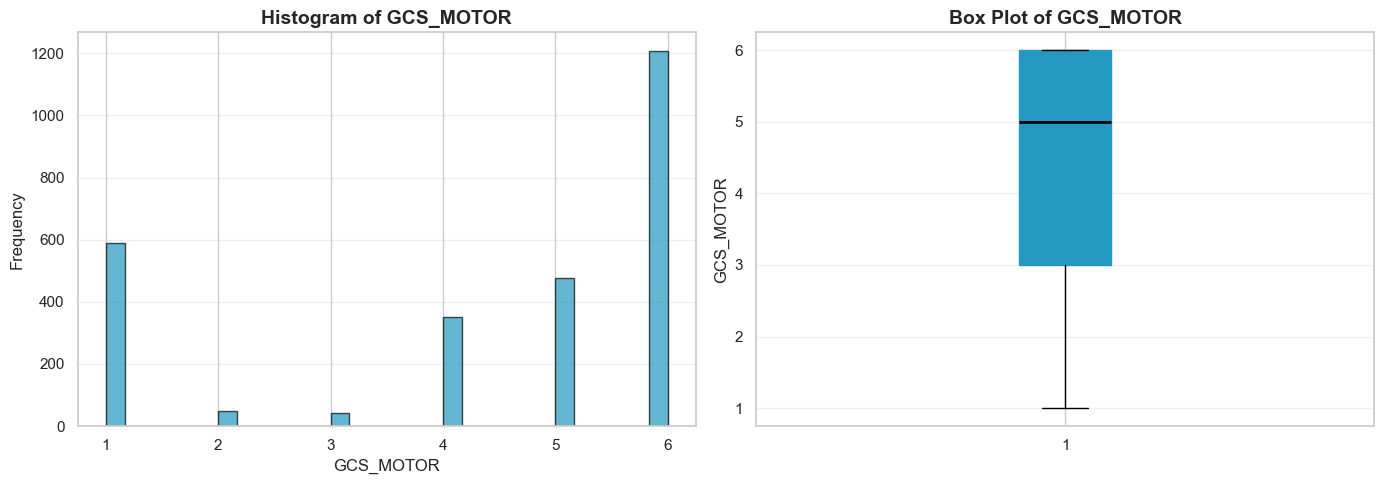

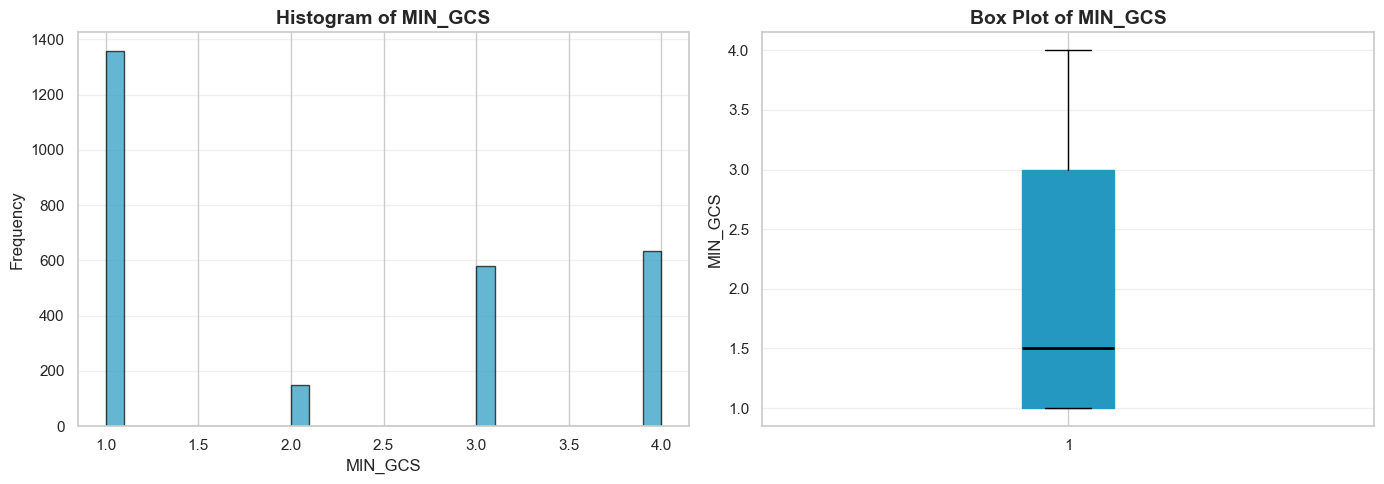

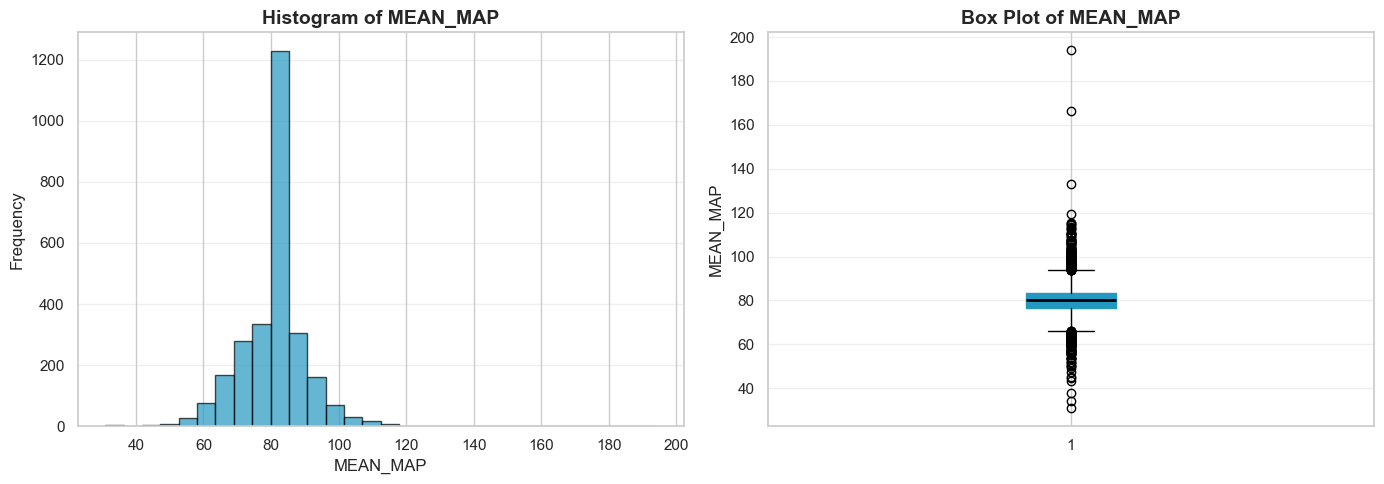

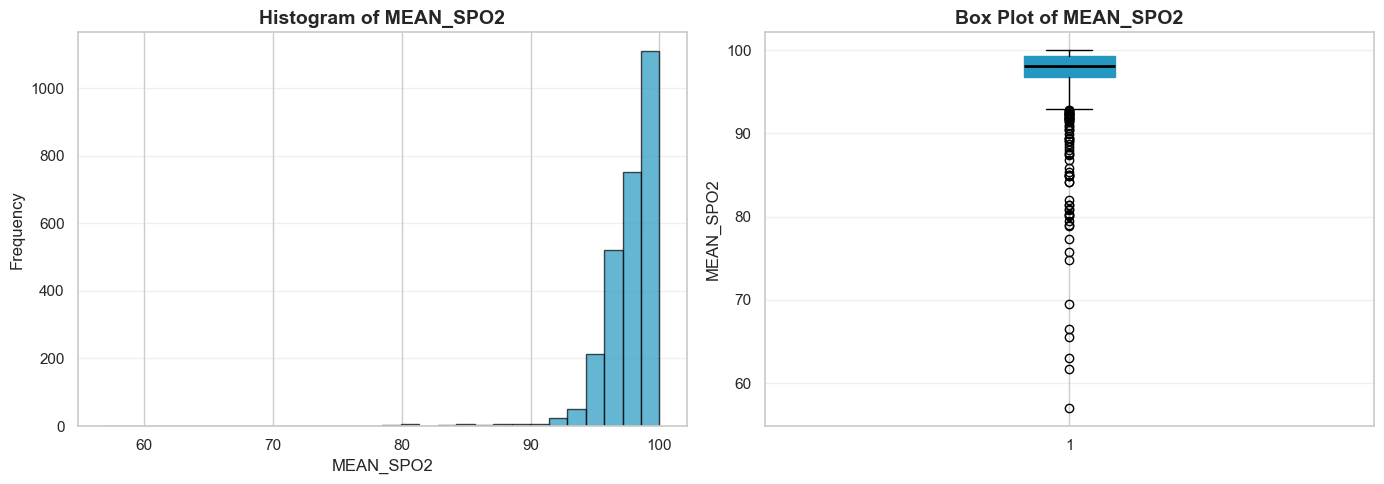

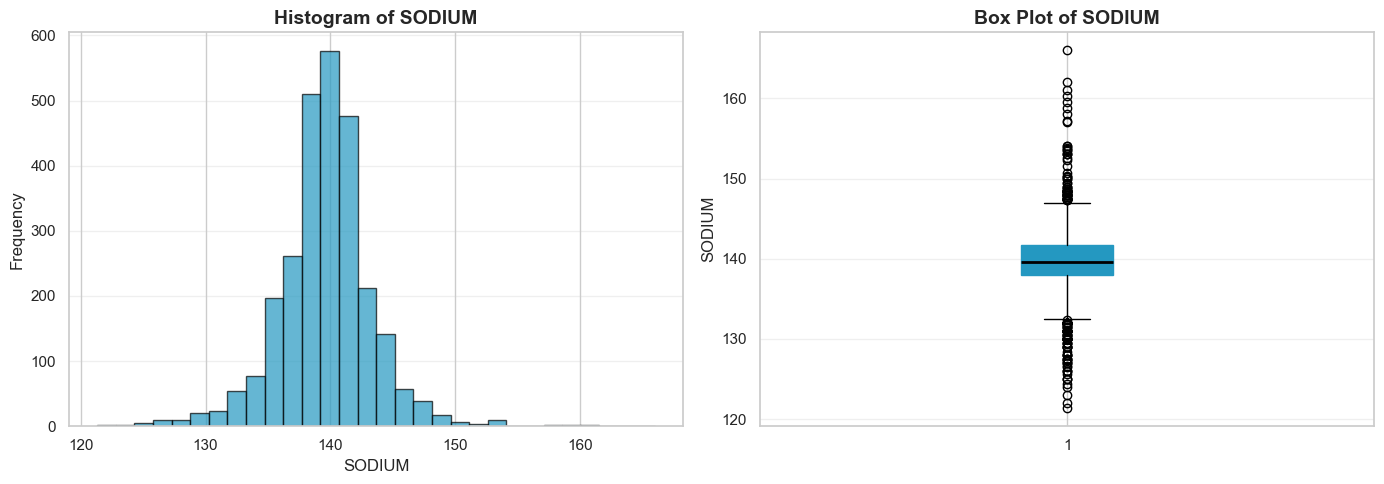

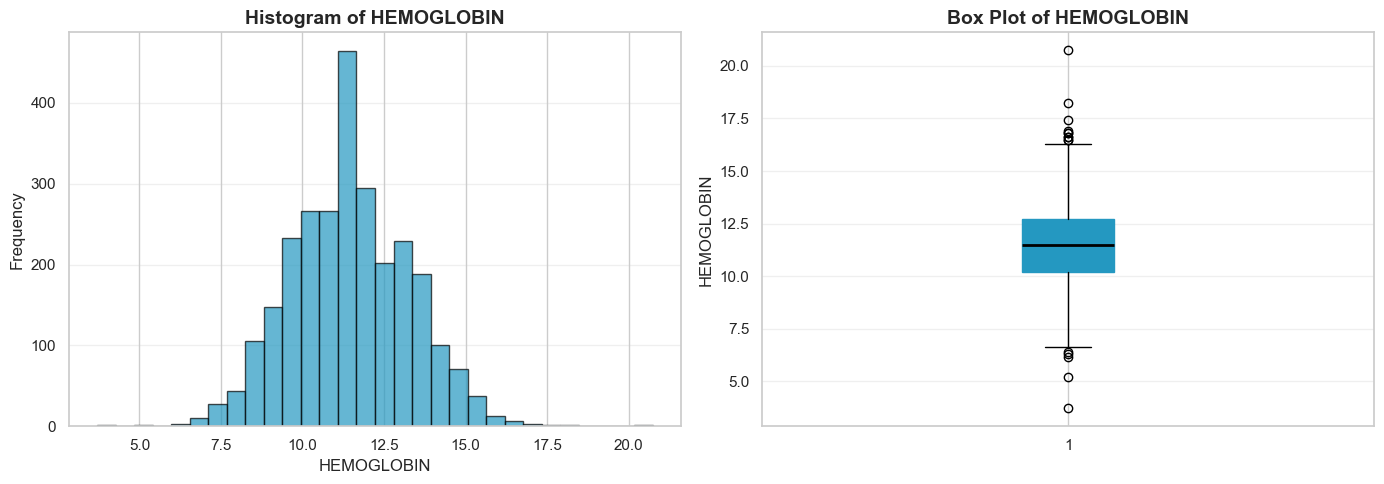

In [69]:
# From the data cleaning, we can infer which of the variables are categorical and which are numerical
continuous_cols = [
    "AGE",
    "ICU_LOS_HOURS",
    "log_ICU_LOS",
    "GCS_EYE",
    "GCS_MOTOR",
    "MIN_GCS",
    "MEAN_MAP",
    "MEAN_SPO2",
    "SODIUM",
    "HEMOGLOBIN",
]

categorical_cols = [
    "GENDER",
    "AGE_GROUP",
    "IN_HOSPITAL_MORTALITY",
    "MECH_VENT",
]

sns.set_style("whitegrid")

palette = sns.color_palette("YlGnBu", n_colors=4)
fixed_color = palette[2]

# Plotting continuous variables
for col in continuous_cols:
    if col in df.columns:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        # Histogram
        axes[0].hist(
            df[col].dropna(), bins=30, color=fixed_color, edgecolor="black", alpha=0.7
        )
        axes[0].set_xlabel(col, fontsize=12)
        axes[0].set_ylabel("Frequency", fontsize=12)
        axes[0].set_title(f"Histogram of {col}", fontsize=14, fontweight="bold")
        axes[0].grid(axis="y", alpha=0.3)

        # Boxplot
        axes[1].boxplot(
            df[col].dropna(),
            vert=True,
            patch_artist=True,
            boxprops=dict(facecolor=fixed_color, color=fixed_color),
            medianprops=dict(color="black", linewidth=2),
        )
        axes[1].set_ylabel(col, fontsize=12)
        axes[1].set_title(f"Box Plot of {col}", fontsize=14, fontweight="bold")
        axes[1].grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.savefig(
            f"figures/{col}_hist_boxplot_grid.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()

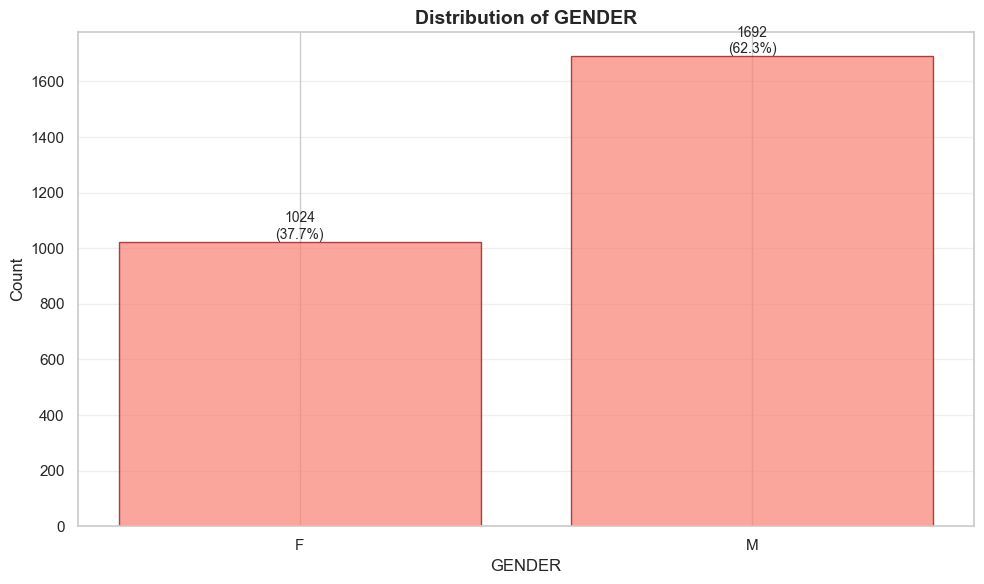

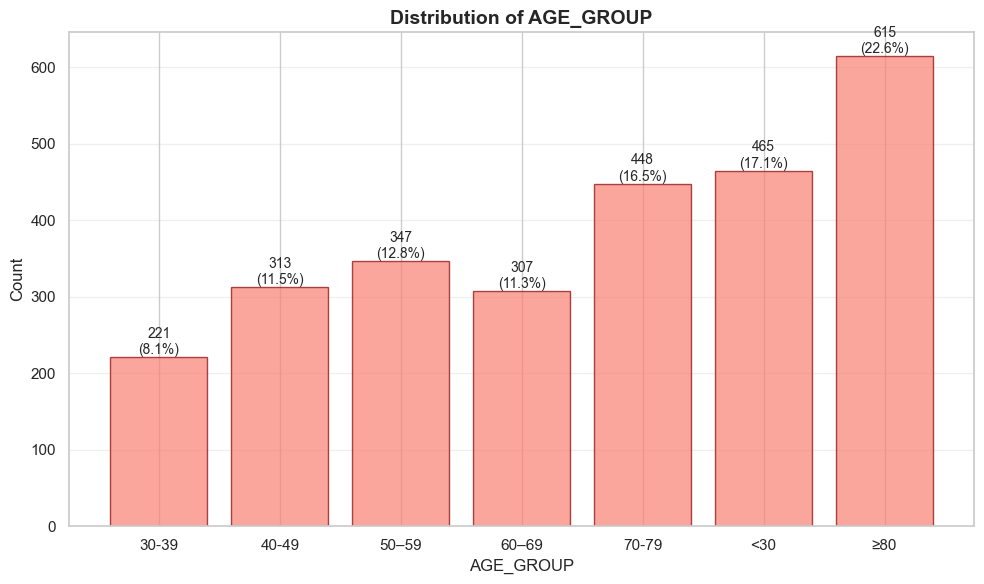

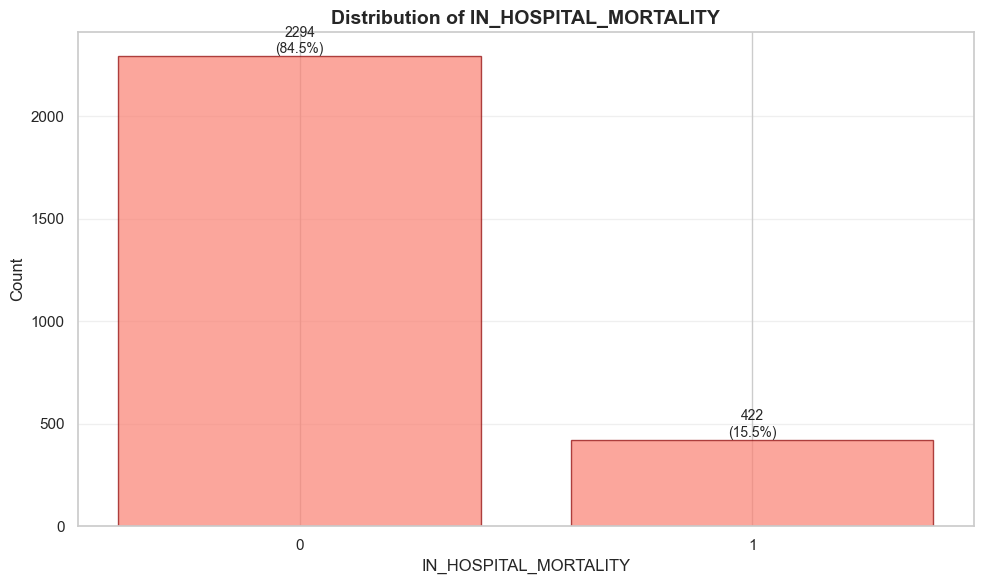

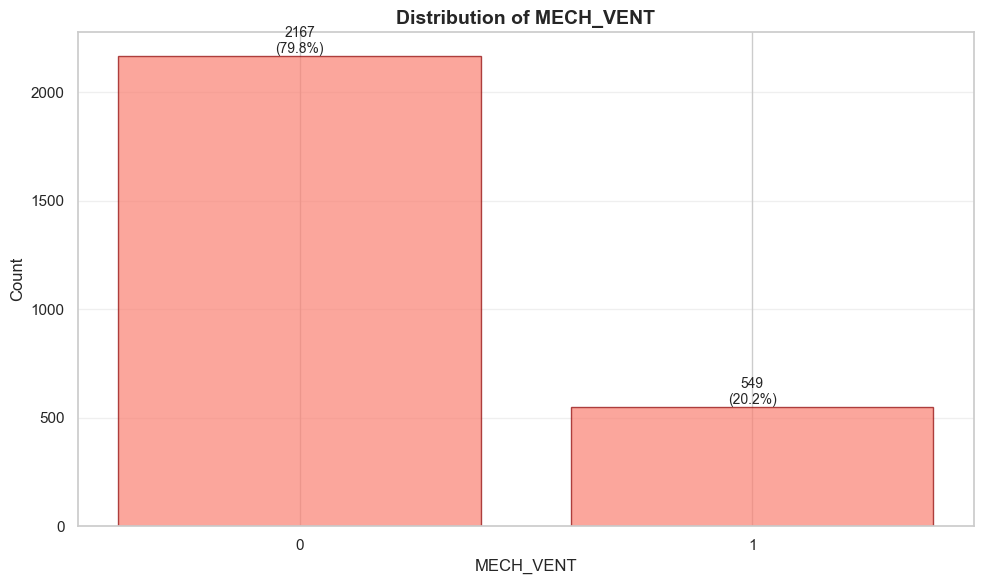

In [70]:
# Categorical variables representation (with barplots)
for col in categorical_cols:
    if col in df.columns:
        value_counts = df[col].value_counts().sort_index()

        plt.figure(figsize=(10, 6))

        bars = plt.bar(
            value_counts.index.astype(str),
            value_counts.values,
            color="salmon",
            edgecolor="darkred",
            alpha=0.7,
        )

        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width() / 2.0,
                height,  # Reminder that Females are mapped as 0 and Males are mapped as 1
                f"{int(height)}\n({height / len(df) * 100:.1f}%)",
                ha="center",
                va="bottom",
                fontsize=10,
            )

        plt.xlabel(col, fontsize=12)
        plt.ylabel("Count", fontsize=12)
        plt.title(f"Distribution of {col}", fontsize=14, fontweight="bold")
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.savefig(
            f"figures/{col}_distributions.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()

In [71]:
# Summary table for continuous variables
stats_continuous = pd.DataFrame(
    {
        "Variable": continuous_cols,
        "Count": [df[col].count() for col in continuous_cols],
        "Missing": [df[col].isna().sum() for col in continuous_cols],
        "Missing %": [df[col].isna().sum() / len(df) * 100 for col in continuous_cols],
        "Min": [df[col].min() for col in continuous_cols],
        "25%": [df[col].quantile(0.25) for col in continuous_cols],
        "Median": [df[col].median() for col in continuous_cols],
        "Mean": [df[col].mean() for col in continuous_cols],
        "75%": [df[col].quantile(0.75) for col in continuous_cols],
        "Max": [df[col].max() for col in continuous_cols],
        "Std": [df[col].std() for col in continuous_cols],
    }
)

display(stats_continuous)

,Variable,Count,Missing,Missing %,Min,25%,Median,Mean,75%,Max,Std
0,AGE,2716,0,0.0,18.000000,40.000000,61.000000,58.743078,79.000000,91.400000,22.849820
1,ICU_LOS_HOURS,2716,0,0.0,0.085300,27.109200,49.176350,105.267623,115.550250,1842.266700,144.100765
2,log_ICU_LOS,2716,0,0.0,0.081856,3.336097,3.915544,4.100569,4.758322,7.519295,1.017663
3,GCS_EYE,2716,0,0.0,1.000000,1.000000,2.000000,2.306701,3.000000,4.000000,1.236570
4,GCS_MOTOR,2716,0,0.0,1.000000,3.000000,5.000000,4.361561,6.000000,6.000000,1.966473
5,MIN_GCS,2716,0,0.0,1.000000,1.000000,1.500000,2.178940,3.000000,4.000000,1.270292
6,MEAN_MAP,2716,0,0.0,30.933333,76.390143,80.166667,80.205028,83.365088,194.000000,9.578539
7,MEAN_SPO2,2716,0,0.0,57.000000,96.732927,98.062500,97.621463,99.307692,100.000000,2.840681
8,SODIUM,2716,0,0.0,121.333333,138.000000,139.619127,139.623401,141.666667,166.000000,3.820238
9,HEMOGLOBIN,2716,0,0.0,3.700000,10.200000,11.455274,11.450010,12.700000,20.750000,1.794109


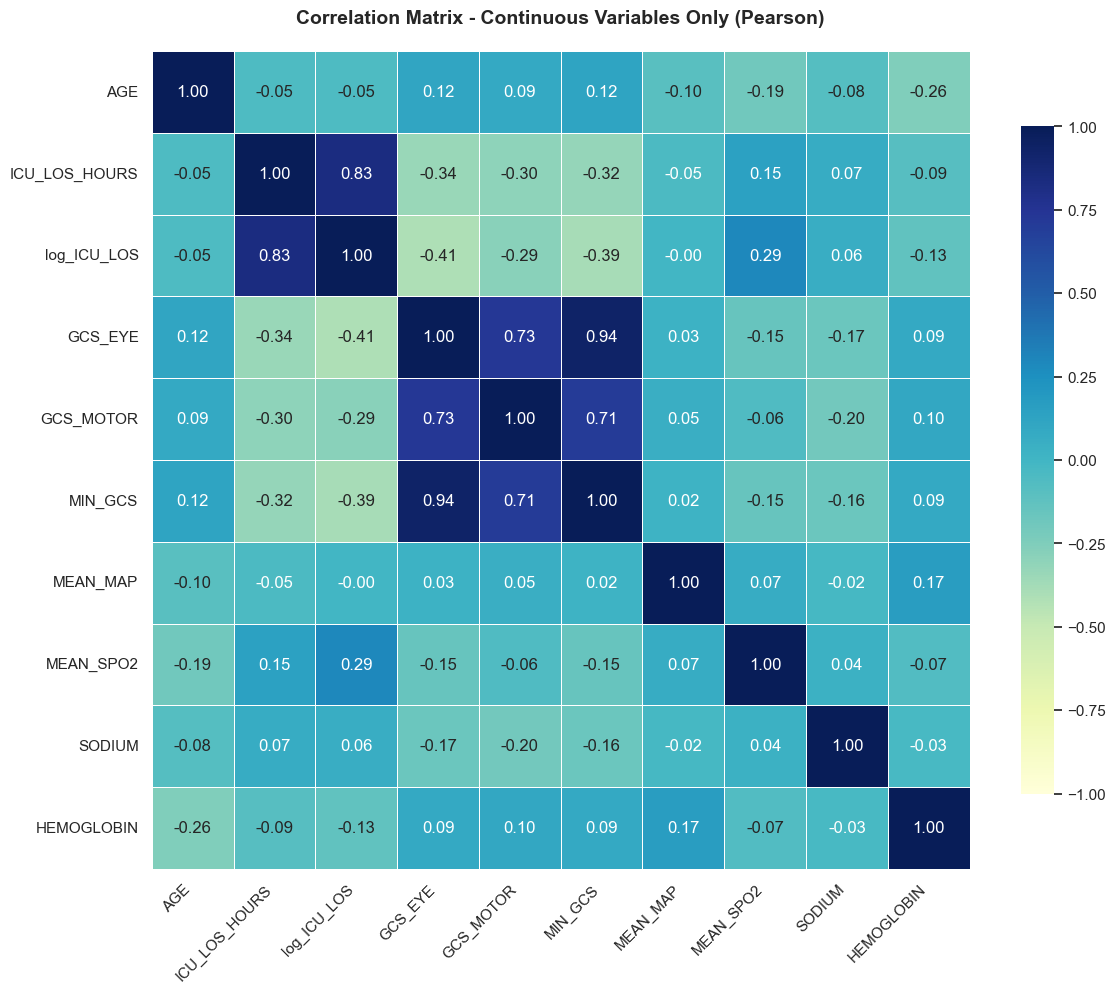

The most correlated continuous variables are:
   Variable 1  Variable 2  Correlation  Abs_Correlation
      GCS_EYE     MIN_GCS     0.936270         0.936270
ICU_LOS_HOURS log_ICU_LOS     0.830085         0.830085
      GCS_EYE   GCS_MOTOR     0.729296         0.729296
    GCS_MOTOR     MIN_GCS     0.708529         0.708529
  log_ICU_LOS   MEAN_SPO2     0.291684         0.291684
     MEAN_MAP  HEMOGLOBIN     0.168818         0.168818
ICU_LOS_HOURS   MEAN_SPO2     0.145203         0.145203
          AGE     MIN_GCS     0.124995         0.124995
          AGE     GCS_EYE     0.116165         0.116165
    GCS_MOTOR  HEMOGLOBIN     0.095103         0.095103
      MIN_GCS  HEMOGLOBIN     0.093534         0.093534
      GCS_EYE  HEMOGLOBIN     0.089932         0.089932
          AGE   GCS_MOTOR     0.086806         0.086806
ICU_LOS_HOURS      SODIUM     0.069266         0.069266
     MEAN_MAP   MEAN_SPO2     0.067957         0.067957
  log_ICU_LOS      SODIUM     0.058458         0.058458
  

In [72]:
# Correlation between numerical variables
correlation_continuous = df[continuous_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation_continuous,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    vmin=-1,
    vmax=1,
)

plt.title(
    "Correlation Matrix - Continuous Variables Only (Pearson)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "figures/correlation_matrix_continuous.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("The most correlated continuous variables are:")

# Extract correlation pairs
correlations_list = []
for i in range(len(correlation_continuous.columns)):
    for j in range(i + 1, len(correlation_continuous.columns)):
        correlations_list.append(
            {
                "Variable 1": correlation_continuous.columns[i],
                "Variable 2": correlation_continuous.columns[j],
                "Correlation": correlation_continuous.iloc[i, j],
            }
        )

# Ordering the most correlated variables into a new dataframe
correlations_df = pd.DataFrame(correlations_list)
correlations_df["Abs_Correlation"] = correlations_df["Correlation"].abs()
correlations_df_sorted = correlations_df.sort_values("Correlation", ascending=False)

print(correlations_df_sorted.head(20).to_string(index=False))

**Guide for analizing if a variable is highly correlated or not**

Correlation Values (r):  
  • |r| = 0.00 - 0.19  →  Very Weak Correlation  
  • |r| = 0.20 - 0.39  →  Weak Correlation  
  • |r| = 0.40 - 0.59  →  Moderated Correlation  
  • |r| = 0.60 - 0.79  →  Strong Correlation  
  • |r| = 0.80 - 1.00  →  Very Strong Correlation  

Correlation Sign:  
  • Positive (+): If the variable increases the target increases  
  • Negative (-): If the variable increases the target decreases  

  The top 4 pairs of most correlated variables (|r|> 0.3) are logical since they associate an original variable with their transformation (``log_ICU_STAY``), and the minimum Glasgow Coma Scale (GCS) with the GCS for Eye and Motor responses.

In [73]:
display(df[categorical_cols])

,GENDER,AGE_GROUP,IN_HOSPITAL_MORTALITY,MECH_VENT
0,M,<30,0,0
1,M,40-49,0,0
2,M,30-39,0,0
3,M,30-39,0,0
4,M,70-79,1,0
...,...,...,...,...
2711,M,≥80,0,0
2712,F,30-39,0,0
2713,F,70-79,0,1
2714,M,50–59,0,0


For categorical values, we use Cramer's approach because it generalizes Phi coefficient and is encoding-independent. It is valid for binary and multiclass and is based on Chi-square association. It ranges the strength of association from 0 to 1.

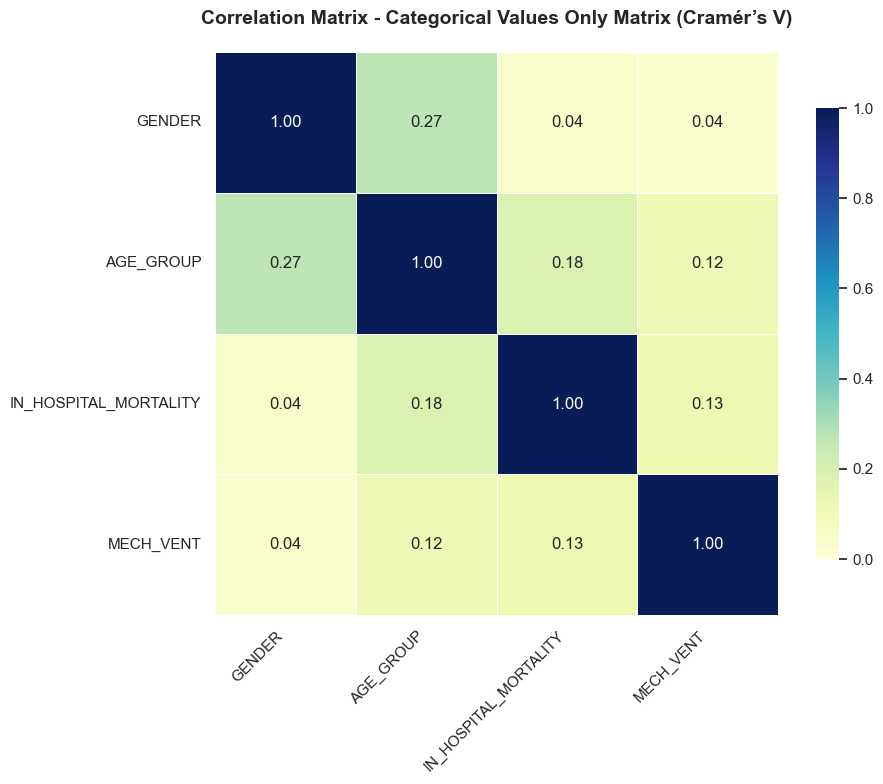

The most correlated categorical variables are:
           Variable 1            Variable 2  Correlation  Abs_Correlation
               GENDER             AGE_GROUP     0.266462         0.266462
            AGE_GROUP IN_HOSPITAL_MORTALITY     0.184638         0.184638
IN_HOSPITAL_MORTALITY             MECH_VENT     0.127044         0.127044
            AGE_GROUP             MECH_VENT     0.116394         0.116394
               GENDER IN_HOSPITAL_MORTALITY     0.040675         0.040675
               GENDER             MECH_VENT     0.036864         0.036864


In [74]:
def cramers_v(x, y):
    contingency = pd.crosstab(x, y)
    chi2 = chi2_contingency(contingency)[0]
    n = contingency.sum().sum()
    r, k = contingency.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


correlation_categorical = pd.DataFrame(
    index=categorical_cols, columns=categorical_cols, dtype=float
)

for col1 in categorical_cols:
    for col2 in categorical_cols:
        correlation_categorical.loc[col1, col2] = cramers_v(df[col1], df[col2])

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_categorical,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    vmin=0,
    vmax=1,
)

plt.title(
    "Correlation Matrix - Categorical Values Only Matrix (Cramér’s V)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "figures/correlation_matrix_categorical.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("The most correlated categorical variables are:")

# Extract correlation pairs
correlations_list = []
for i in range(len(correlation_categorical.columns)):
    for j in range(i + 1, len(correlation_categorical.columns)):
        correlations_list.append(
            {
                "Variable 1": correlation_categorical.columns[i],
                "Variable 2": correlation_categorical.columns[j],
                "Correlation": correlation_categorical.iloc[i, j],
            }
        )

# Ordering the most correlated variables into a new dataframe
correlations_df = pd.DataFrame(correlations_list)
correlations_df["Abs_Correlation"] = correlations_df["Correlation"].abs()
correlations_df_sorted = correlations_df.sort_values("Correlation", ascending=False)

print(correlations_df_sorted.head(20).to_string(index=False))

We can observed from the table that the correlations reach a maximum |r| value of 0.26, which represents a weak correlation. It should be noted that ``IN_HOSPITAL_MORTALITY`` is very weakly correlated with ``AGE_GROUP`` (being its highest correlated pair, suggesting a relationship between risk of death and age group) and ``GENDER``.

To represent the correlation between all the variables, Phik correlation was used because it handles the combination of categorical, binary and numeric data. It also captures non-linear relationships.

In [75]:
df[continuous_cols] = df[continuous_cols].astype(float)
print(df[continuous_cols].dtypes)

for col in categorical_cols:
    df[col] = df[col].astype(str)  # convert to string for Phik matrix
print(df[categorical_cols].dtypes)

AGE              float64
ICU_LOS_HOURS    float64
log_ICU_LOS      float64
GCS_EYE          float64
GCS_MOTOR        float64
MIN_GCS          float64
MEAN_MAP         float64
MEAN_SPO2        float64
SODIUM           float64
HEMOGLOBIN       float64
dtype: object
GENDER                   object
AGE_GROUP                object
IN_HOSPITAL_MORTALITY    object
MECH_VENT                object
dtype: object


In [76]:
df_to_corr = df[continuous_cols + categorical_cols].copy()
print(df_to_corr.dtypes)
print(df_to_corr["IN_HOSPITAL_MORTALITY"].unique())

df_to_corr.loc[:, "IN_HOSPITAL_MORTALITY"] = df_to_corr["IN_HOSPITAL_MORTALITY"].astype(
    int
)
print(df_to_corr.dtypes)
print(df_to_corr["IN_HOSPITAL_MORTALITY"].dtype)
print(df_to_corr["IN_HOSPITAL_MORTALITY"].unique())

AGE                      float64
ICU_LOS_HOURS            float64
log_ICU_LOS              float64
GCS_EYE                  float64
GCS_MOTOR                float64
MIN_GCS                  float64
MEAN_MAP                 float64
MEAN_SPO2                float64
SODIUM                   float64
HEMOGLOBIN               float64
GENDER                    object
AGE_GROUP                 object
IN_HOSPITAL_MORTALITY     object
MECH_VENT                 object
dtype: object
['0' '1']
AGE                      float64
ICU_LOS_HOURS            float64
log_ICU_LOS              float64
GCS_EYE                  float64
GCS_MOTOR                float64
MIN_GCS                  float64
MEAN_MAP                 float64
MEAN_SPO2                float64
SODIUM                   float64
HEMOGLOBIN               float64
GENDER                    object
AGE_GROUP                 object
IN_HOSPITAL_MORTALITY     object
MECH_VENT                 object
dtype: object
object
[0 1]


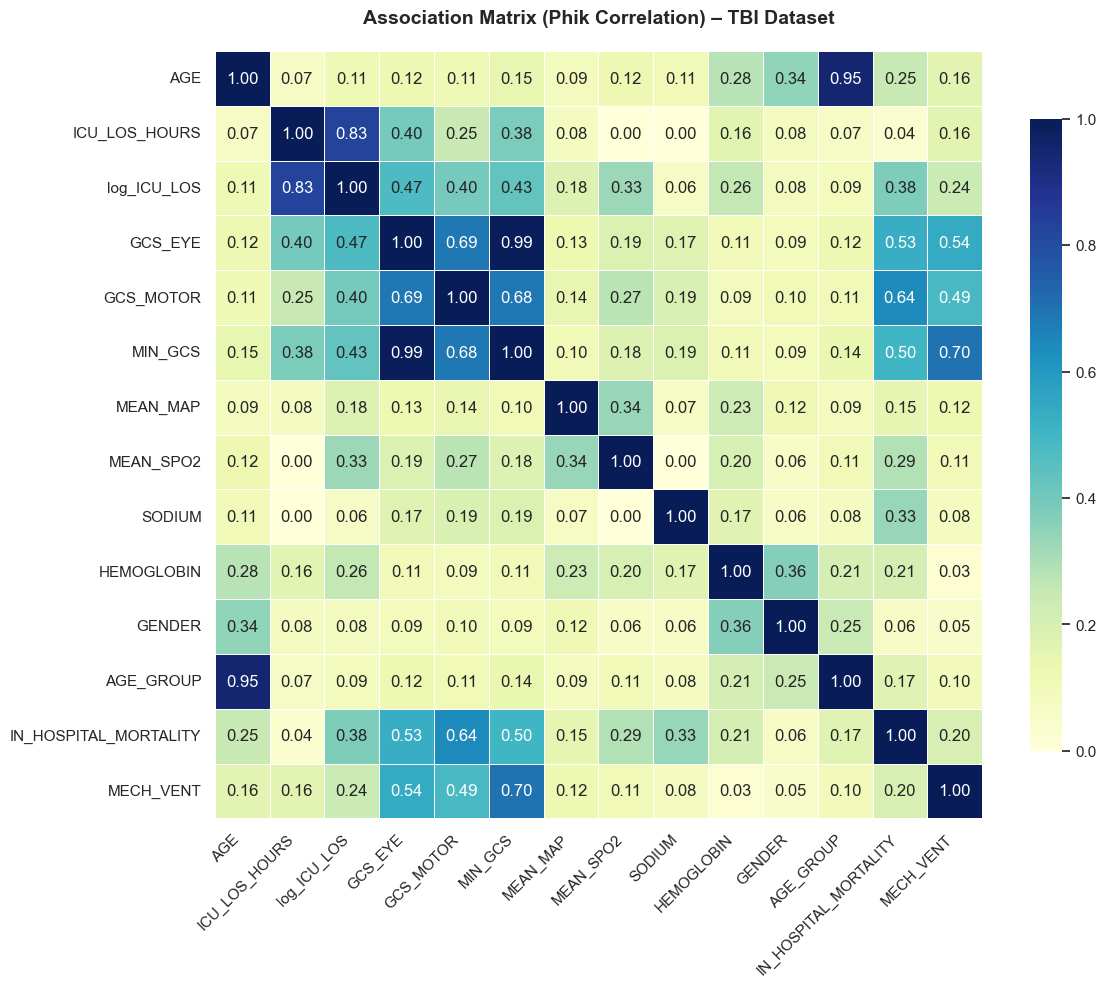

In [77]:
phik_corr = df_to_corr.phik_matrix(interval_cols=continuous_cols)

plt.figure(figsize=(12, 10))
sns.heatmap(
    phik_corr,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    vmin=0,
    vmax=1,
)

plt.title(
    "Association Matrix (Phik Correlation) – TBI Dataset",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "figures/correlation_matrix_all_variables.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [78]:
print("The most correlated variables (considering all) are:")

# Extract correlation pairs
correlations_list = []
for i in range(len(phik_corr.columns)):
    for j in range(i + 1, len(phik_corr.columns)):
        correlations_list.append(
            {
                "Variable 1": phik_corr.columns[i],
                "Variable 2": phik_corr.columns[j],
                "Correlation": phik_corr.iloc[i, j],
            }
        )

# Ordering the most correlated variables into a new dataframe
correlations_df = pd.DataFrame(correlations_list)
correlations_df["Abs_Correlation"] = correlations_df["Correlation"].abs()
correlations_df_sorted = correlations_df.sort_values("Abs_Correlation", ascending=False)

print(correlations_df_sorted.head(20).to_string(index=False))

The most correlated variables (considering all) are:
   Variable 1            Variable 2  Correlation  Abs_Correlation
      GCS_EYE               MIN_GCS     0.988822         0.988822
          AGE             AGE_GROUP     0.950940         0.950940
ICU_LOS_HOURS           log_ICU_LOS     0.828278         0.828278
      MIN_GCS             MECH_VENT     0.700250         0.700250
      GCS_EYE             GCS_MOTOR     0.685409         0.685409
    GCS_MOTOR               MIN_GCS     0.684545         0.684545
    GCS_MOTOR IN_HOSPITAL_MORTALITY     0.639030         0.639030
      GCS_EYE             MECH_VENT     0.542589         0.542589
      GCS_EYE IN_HOSPITAL_MORTALITY     0.528786         0.528786
      MIN_GCS IN_HOSPITAL_MORTALITY     0.502262         0.502262
    GCS_MOTOR             MECH_VENT     0.485735         0.485735
  log_ICU_LOS               GCS_EYE     0.473995         0.473995
  log_ICU_LOS               MIN_GCS     0.433577         0.433577
  log_ICU_LOS          

PhiK correlation analysis showed strong associations between derived or clinically related variables, including age measures, ICU length-of-stay transformations, and Glasgow Coma Scale components. 
High correlations between derived and original variables were expected.
Moderate correlations between GCS components, mechanical ventilation, and in-hospital mortality were observed, consistent with known clinical relationships. 
Overall, most predictors exhibited low to moderate correlations, supporting the use of ridge regression to manage multicollinearity while preserving clinically meaningful variables.

     Variable  Correlation
    GCS_MOTOR     0.639030
      GCS_EYE     0.528786
      MIN_GCS     0.502262
  log_ICU_LOS     0.375579
       SODIUM     0.332475
    MEAN_SPO2     0.287869
          AGE     0.248617
   HEMOGLOBIN     0.210117
    MECH_VENT     0.196026
    AGE_GROUP     0.167036
     MEAN_MAP     0.149130
       GENDER     0.056333
ICU_LOS_HOURS     0.038400


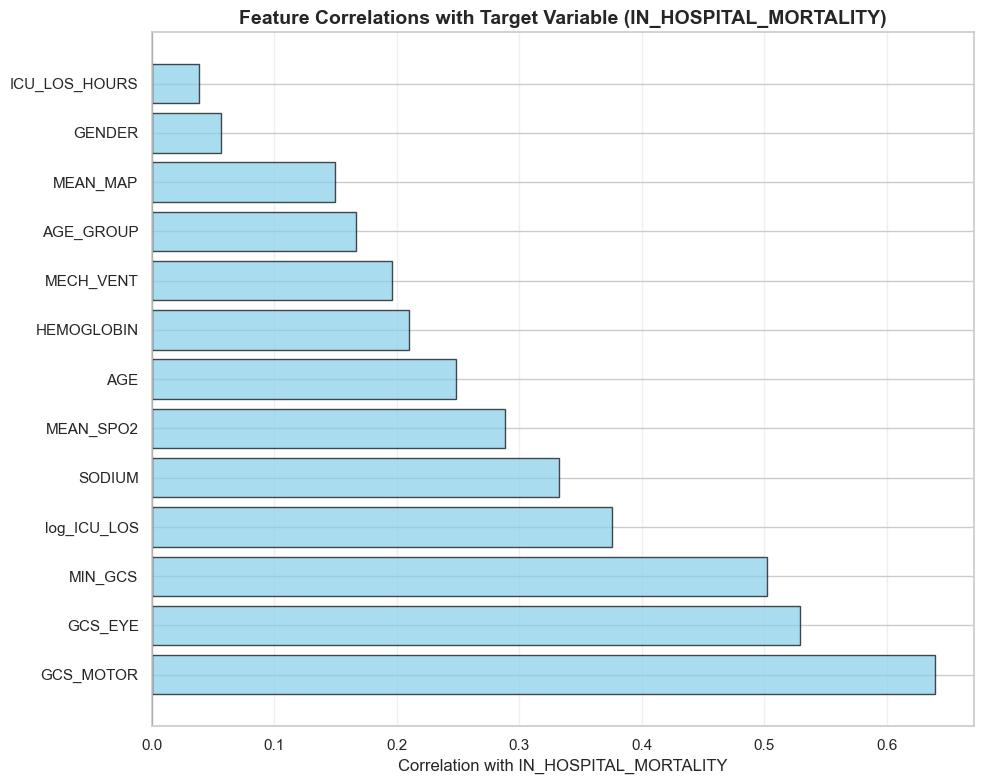

In [79]:
# Observing the correlation between the rest of the variables and the target variable (risk to decease in ICU stay)
if "IN_HOSPITAL_MORTALITY" in df.columns:
    target_correlations = (
        phik_corr["IN_HOSPITAL_MORTALITY"]
        .drop("IN_HOSPITAL_MORTALITY")
        .sort_values(ascending=False)
    )
    target_corr_df = pd.DataFrame(
        {
            "Variable": target_correlations.index,
            "Correlation": target_correlations.values,
        }
    )
    print(target_corr_df.to_string(index=False))

    plt.figure(figsize=(10, 8))
    colors = ["skyblue" if x > 0 else "salmon" for x in target_correlations.values]
    plt.barh(
        target_correlations.index,
        target_correlations.values,
        color=colors,
        alpha=0.7,
        edgecolor="black",
    )
    plt.xlabel("Correlation with IN_HOSPITAL_MORTALITY", fontsize=12)
    plt.title(
        "Feature Correlations with Target Variable (IN_HOSPITAL_MORTALITY)",
        fontsize=14,
        fontweight="bold",
    )
    plt.axvline(x=0, color="black", linestyle="-", linewidth=0.8)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        "figures/feature_correlations_with_target.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

- Neurological variables show the strongest associations with in-hospital mortality, particularly GCS_MO``TOR (correlation ≈ 0.63), followed by ``GCS_EYE`` (≈ 0.53) and ``MIN_GCS`` (≈ 0.50), underscoring the prognostic importance of neurological status.
- The log-transformed ICU length of stay (``log_ICU_LOS``, ≈ 0.36) exhibits a stronger association with mortality than raw ``ICU_LOS_HOURS``, indicating that prolonged ICU stays are linked to increased mortality risk and that the log transformation captures this relationship more effectively.
- ``SODIUM`` levels and ``MEAN_SPO2`` show moderate correlations with mortality (≈ 0.32 and ≈ 0.28, respectively), suggesting a potential contribution of electrolyte imbalance and oxygenation status to patient outcomes.
- ``AGE``, ``AGE_GROUP``, ``MECH_VENT``, and ``HEMOGLOBIN`` display weaker but still clinically meaningful correlations, consistent with their known relevance while indicating a less direct association compared to neurological measures.
- Gender and raw ICU length of stay show very weak correlations with in-hospital mortality, suggesting limited standalone predictive value.

Overall, these findings highlight the dominant predictive role of neurological status and ICU length of stay (particularly in log-transformed form) in mortality risk stratification within this cohort.


 Analyzing: AGE


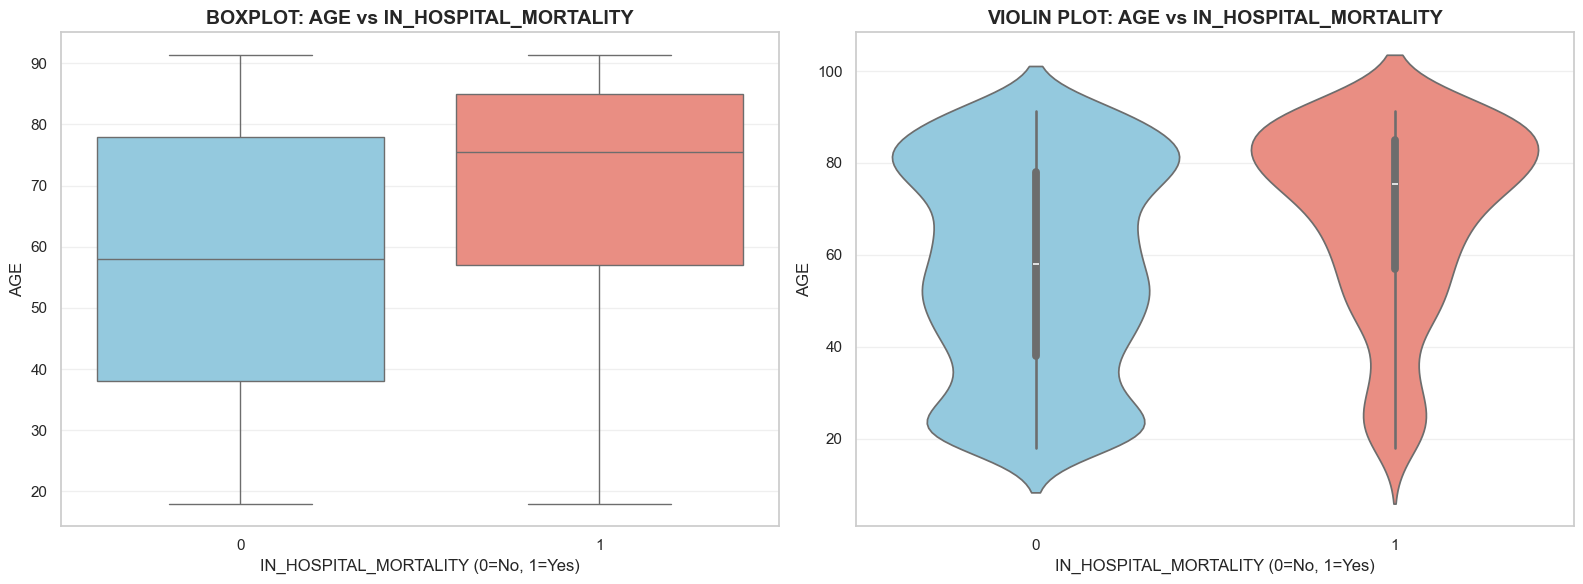


  Comparative Statistics:
  Metric               IHM=0           IHM=1           Diference      
  -----------------------------------------------------------------
  Median               58.00           75.50           17.50           (+30.2%)
  Mean                 56.90           68.74           11.83          
  Std                  22.81           20.36           -2.46          

 Analyzing: ICU_LOS_HOURS


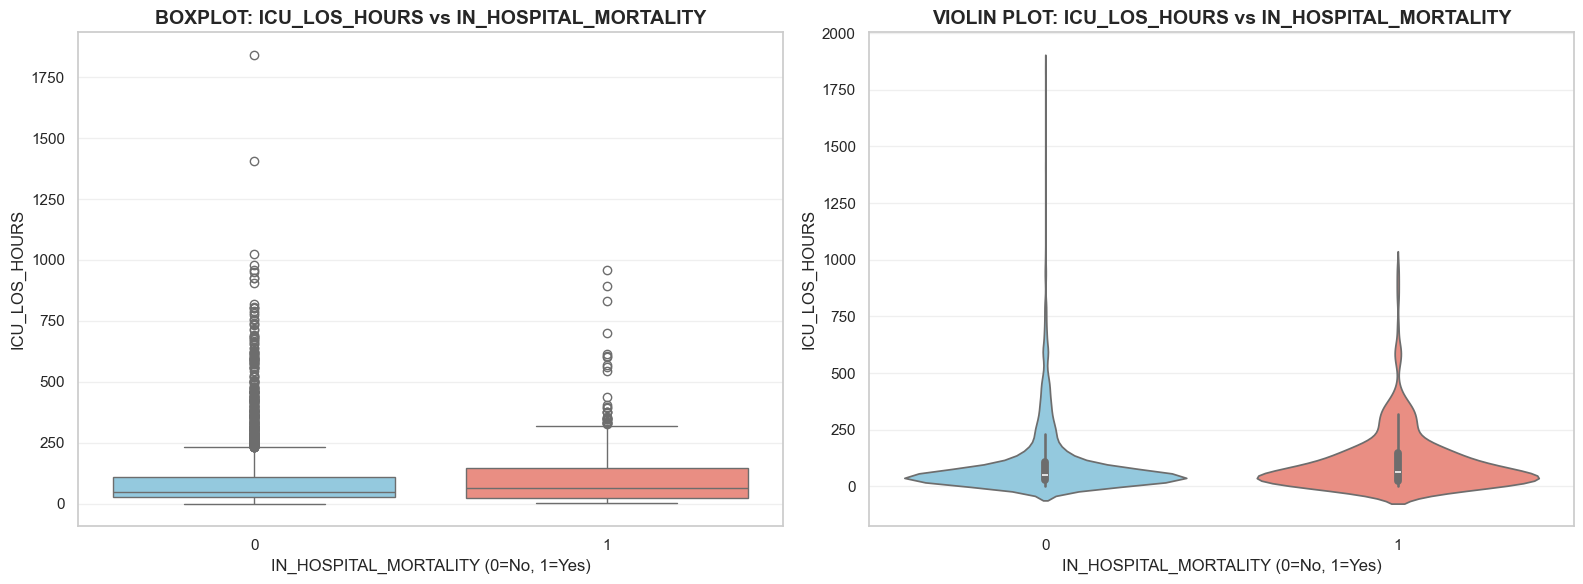


  Comparative Statistics:
  Metric               IHM=0           IHM=1           Diference      
  -----------------------------------------------------------------
  Median               47.74           65.15           17.41           (+36.5%)
  Mean                 104.40          110.00          5.60           
  Std                  146.21          132.10          -14.11         

 Analyzing: log_ICU_LOS


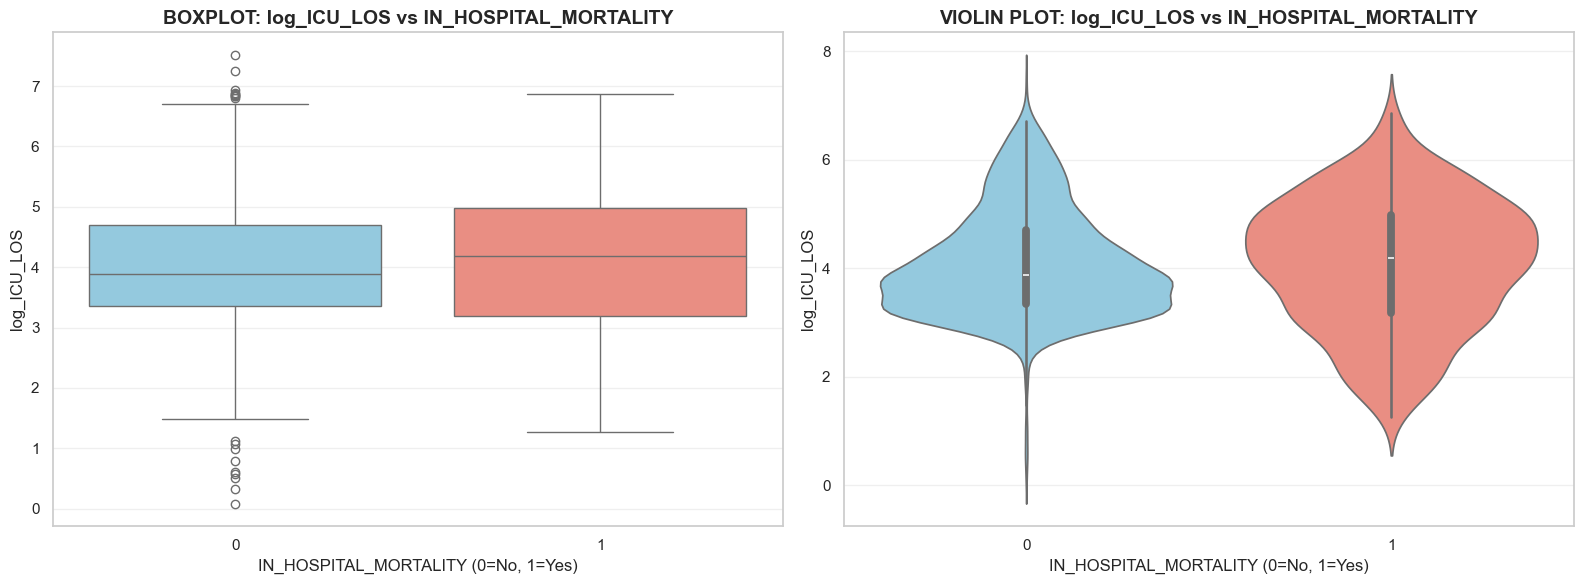


  Comparative Statistics:
  Metric               IHM=0           IHM=1           Diference      
  -----------------------------------------------------------------
  Median               3.89            4.19            0.31            (+7.9%)
  Mean                 4.10            4.09            -0.01          
  Std                  0.98            1.19            0.21           

 Analyzing: GCS_EYE


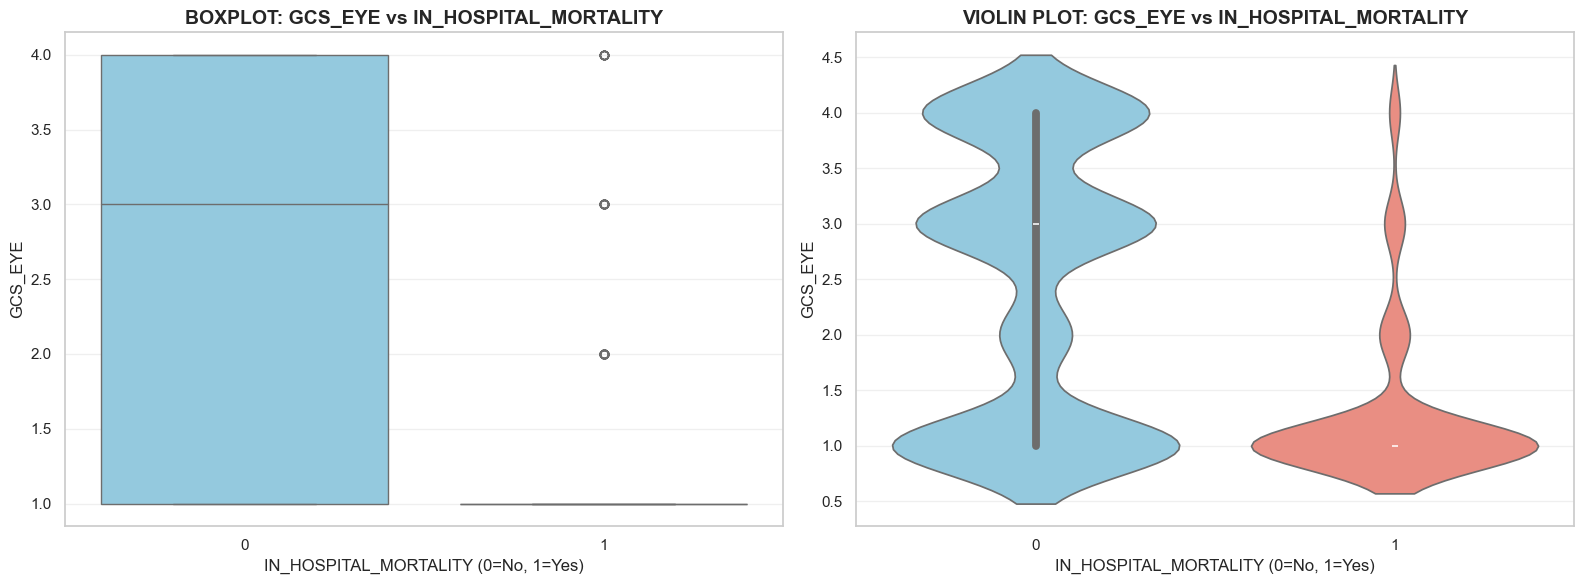


  Comparative Statistics:
  Metric               IHM=0           IHM=1           Diference      
  -----------------------------------------------------------------
  Median               3.00            1.00            -2.00           (-66.7%)
  Mean                 2.49            1.30            -1.19          
  Std                  1.22            0.72            -0.51          

 Analyzing: GCS_MOTOR


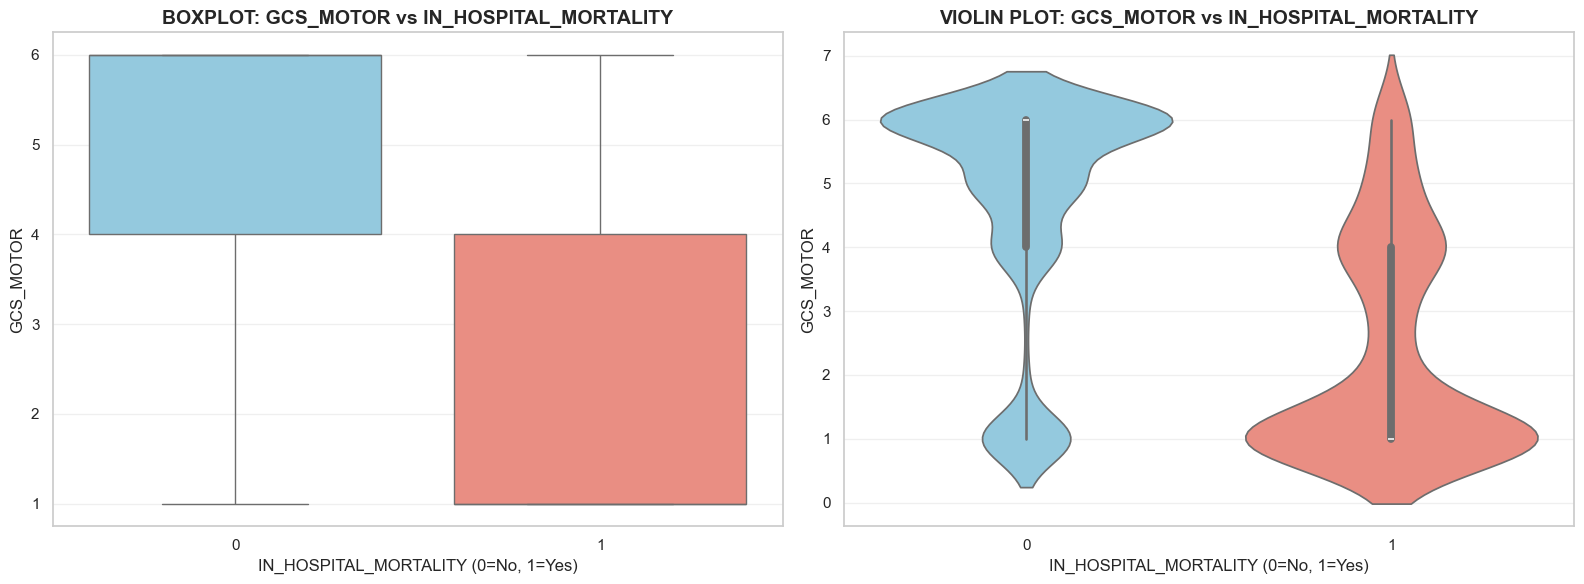


  Comparative Statistics:
  Metric               IHM=0           IHM=1           Diference      
  -----------------------------------------------------------------
  Median               6.00            1.00            -5.00           (-83.3%)
  Mean                 4.73            2.37            -2.36          
  Std                  1.78            1.70            -0.08          

 Analyzing: MIN_GCS


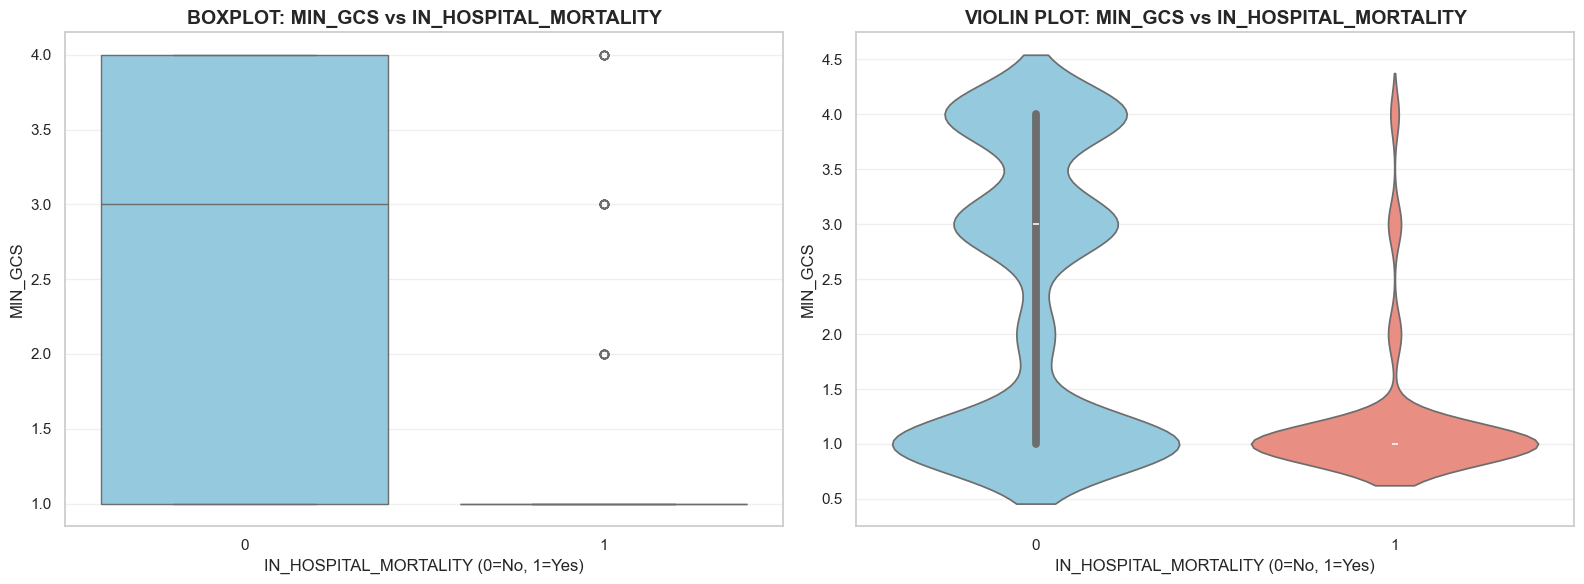


  Comparative Statistics:
  Metric               IHM=0           IHM=1           Diference      
  -----------------------------------------------------------------
  Median               3.00            1.00            -2.00           (-66.7%)
  Mean                 2.36            1.20            -1.16          
  Std                  1.28            0.63            -0.65          

 Analyzing: MEAN_MAP


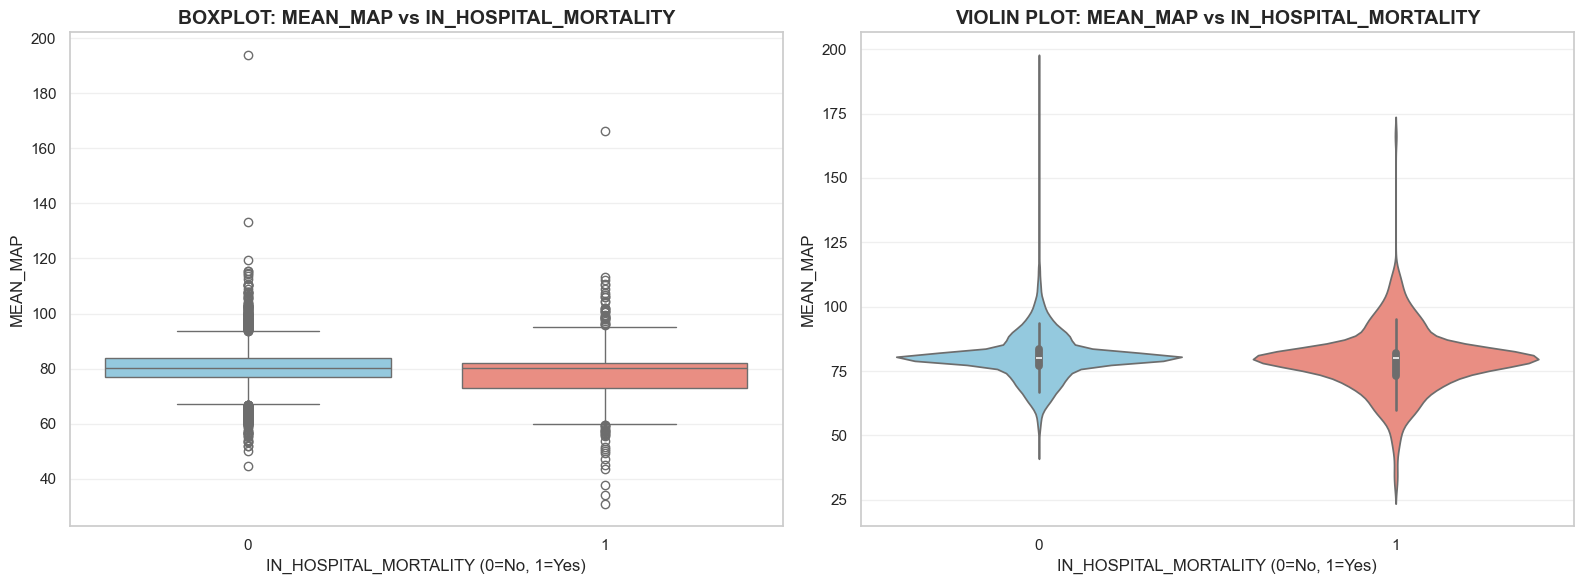


  Comparative Statistics:
  Metric               IHM=0           IHM=1           Diference      
  -----------------------------------------------------------------
  Median               80.17           80.17           0.00            (+0.0%)
  Mean                 80.44           78.95           -1.49          
  Std                  8.95            12.38           3.43           

 Analyzing: MEAN_SPO2


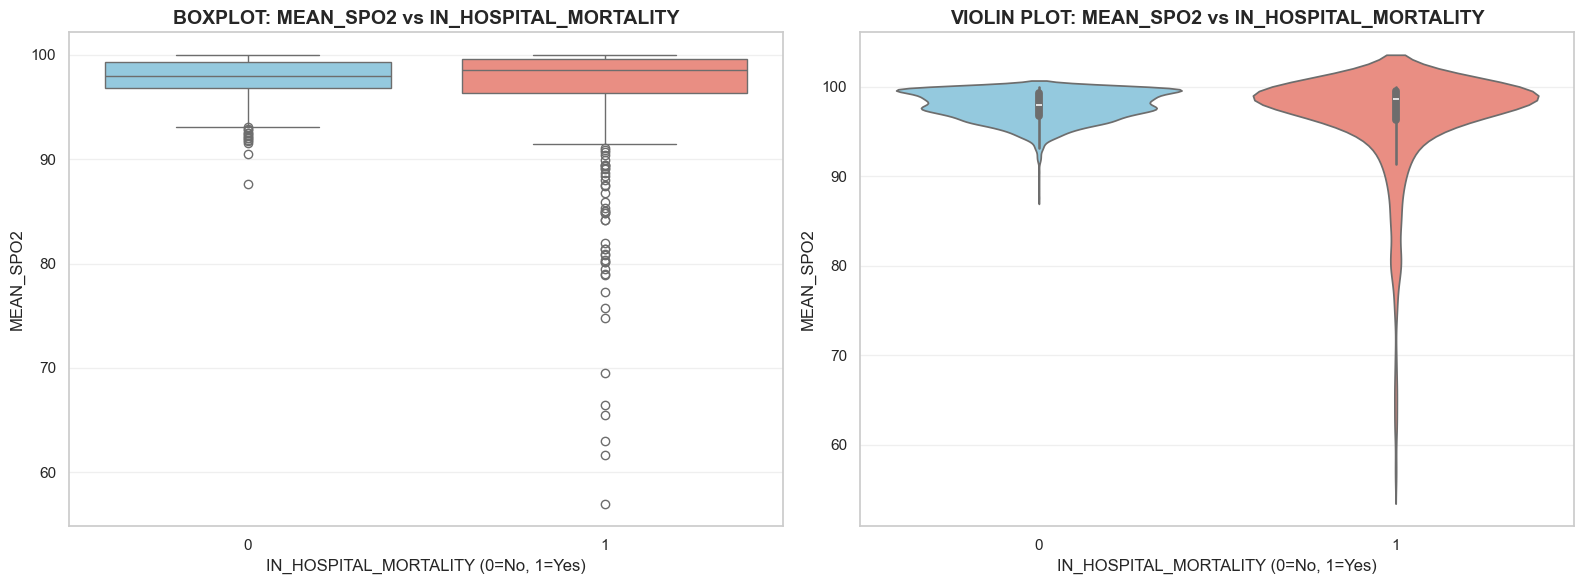


  Comparative Statistics:
  Metric               IHM=0           IHM=1           Diference      
  -----------------------------------------------------------------
  Median               98.00           98.58           0.58            (+0.6%)
  Mean                 97.84           96.42           -1.43          
  Std                  1.63            5.99            4.35           

 Analyzing: SODIUM


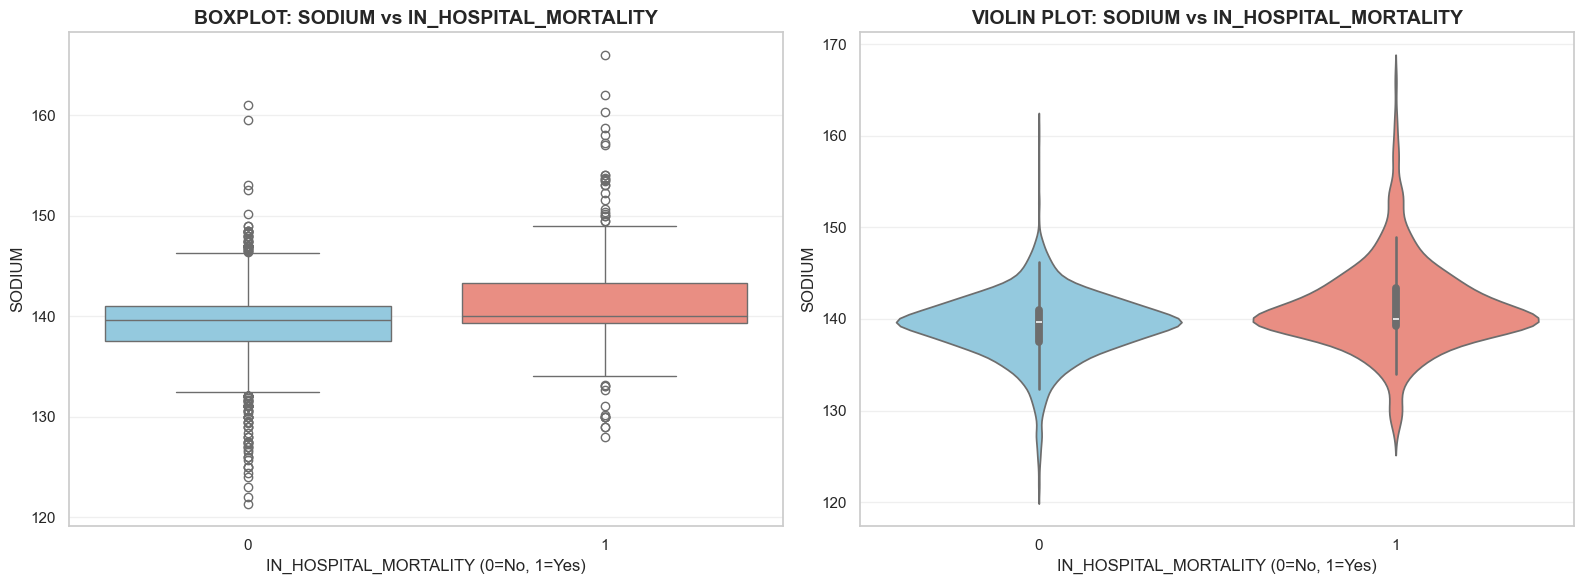


  Comparative Statistics:
  Metric               IHM=0           IHM=1           Diference      
  -----------------------------------------------------------------
  Median               139.62          140.00          0.38            (+0.3%)
  Mean                 139.31          141.32          2.01           
  Std                  3.53            4.79            1.26           

 Analyzing: HEMOGLOBIN


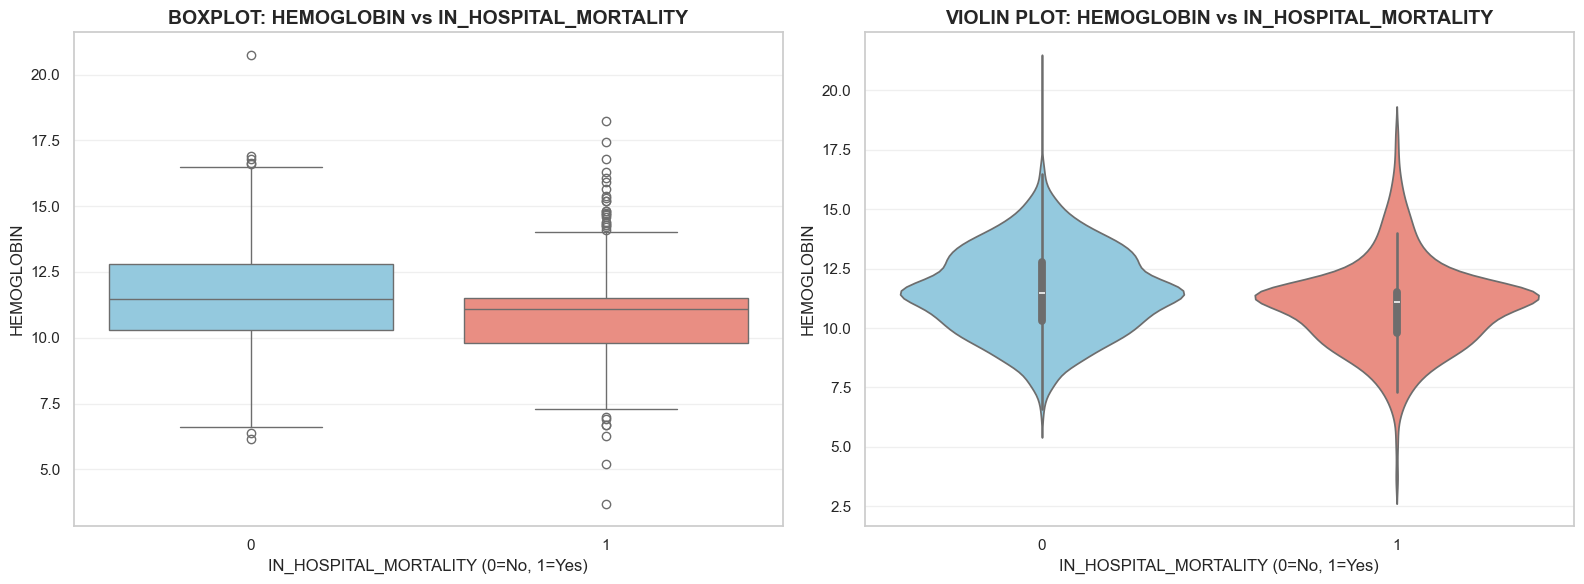


  Comparative Statistics:
  Metric               IHM=0           IHM=1           Diference      
  -----------------------------------------------------------------
  Median               11.46           11.10           -0.36           (-3.1%)
  Mean                 11.55           10.91           -0.64          
  Std                  1.77            1.83            0.05           


In [80]:
# Style
target = "IN_HOSPITAL_MORTALITY"
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

# Boxplot and Violin Plot for analyzing continuous variables vs Target Variable

for col in continuous_cols:
    if col in df_to_corr.columns and target in df_to_corr.columns:
        print(f"\n Analyzing: {col}")

        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        # BOXPLOT
        sns.boxplot(
            data=df_to_corr,
            x=target,
            y=col,
            hue=target,
            ax=axes[0],
            palette=["skyblue", "salmon"],
            legend=False,
        )
        axes[0].set_title(f"BOXPLOT: {col} vs {target}", fontsize=14, fontweight="bold")
        axes[0].set_xlabel("IN_HOSPITAL_MORTALITY (0=No, 1=Yes)", fontsize=12)
        axes[0].set_ylabel(col, fontsize=12)
        axes[0].grid(axis="y", alpha=0.3)

        # VIOLIN PLOT
        sns.violinplot(
            data=df_to_corr,
            x=target,
            y=col,
            hue=target,
            ax=axes[1],
            palette=["skyblue", "salmon"],
            inner="box",
            legend=False,
        )
        axes[1].set_title(
            f"VIOLIN PLOT: {col} vs {target}", fontsize=14, fontweight="bold"
        )
        axes[1].set_xlabel("IN_HOSPITAL_MORTALITY (0=No, 1=Yes)", fontsize=12)
        axes[1].set_ylabel(col, fontsize=12)
        axes[1].grid(axis="y", alpha=0.3)

        plt.tight_layout()
        filename = f"figures/{col}_box_violin_vs_IHM.png"
        plt.savefig(filename, dpi=300, bbox_inches="tight")
        plt.show()

        # Calculation of statistics
        group_0 = df_to_corr[df_to_corr[target] == 0][col].dropna()
        group_1 = df_to_corr[df_to_corr[target] == 1][col].dropna()

        median_0 = group_0.median()
        median_1 = group_1.median()
        mean_0 = group_0.mean()
        mean_1 = group_1.mean()
        std_0 = group_0.std()
        std_1 = group_1.std()

        diff_median = median_1 - median_0
        diff_mean = mean_1 - mean_0
        pct_diff = (diff_median / median_0 * 100) if median_0 != 0 else 0

        print(f"\n  Comparative Statistics:")
        print(f"  {'Metric':<20} {'IHM=0':<15} {'IHM=1':<15} {'Diference':<15}")
        print(f"  {'-' * 65}")
        print(
            f"  {'Median':<20} {median_0:<15.2f} {median_1:<15.2f} {diff_median:<15.2f} ({pct_diff:+.1f}%)"
        )
        print(f"  {'Mean':<20} {mean_0:<15.2f} {mean_1:<15.2f} {diff_mean:<15.2f}")
        print(f"  {'Std':<20} {std_0:<15.2f} {std_1:<15.2f} {std_1 - std_0:<15.2f}")

- **Age**: Patients with in-hospital mortality = 1 are older on average than those who survived. The distribution is shifted toward higher ages, indicating increasing mortality risk with advancing age.

- **ICU length of stay (ICU LOS)**: ICU LOS shows substantial overlap between mortality groups. Patients with in-hospital mortality tend to have longer median ICU stays, while survivors exhibit greater variability and more extreme values, reflecting heterogeneous ICU courses.

- **Log ICU length of stay**: Log-transformed ICU length of stay is slightly higher and more variable in patients with in-hospital mortality, suggesting that prolonged ICU courses are associated with increased mortality risk, while shorter stays among some non-survivors may reflect early death.

- **GCS Eye**: Severity score eye is markedly lower in patients who died in hospital compared with survivors. This clear separation suggests strong association between physiologic severity and in-hospital mortality.

- **GCS Motor**: Patients with in-hospital mortality = 1 have lower GCS motor scores compared with survivors. The distribution is shifted toward poorer motor responses, indicating worse neurologic status among non-survivors.

- **Minimum GCS**: Minimum GCS values are substantially lower in patients who died in hospital than in those who survived. This pronounced downward shift reflects more severe episodes of impaired consciousness in non-survivors.

- **Mean MAP**: Mean arterial pressure is slightly lower in patients with in-hospital mortality = 1 compared with survivors. Although distributions overlap, this suggests an association between lower sustained perfusion pressure and increased mortality risk.

- **Mean SpO₂**: Patients with in-hospital mortality = 1 show slightly lower mean SpO₂ values compared with survivors. Despite overlap between groups, this downward shift suggests worse overall oxygenation among non-survivors.

- **Sodium**: Serum sodium levels are modestly higher in patients who died in hospital than in those who survived. The upward shift in the mortality group indicates a tendency toward dysnatremia among non-survivors.

- **Hemoglobin**: Hemoglobin levels are lower in patients with in-hospital mortality = 1 compared with survivors. This suggests that anemia or reduced oxygen-carrying capacity is associated with increased in-hospital mortality.


 Analyzing: GENDER


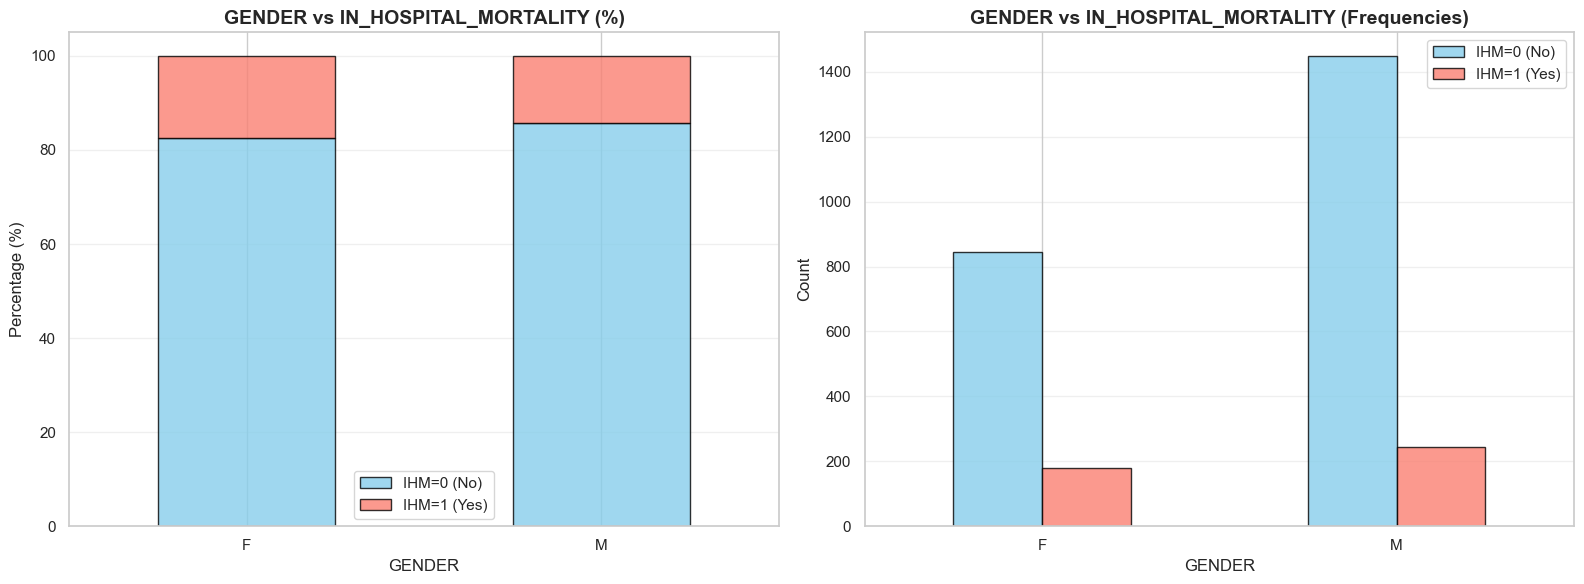

IN_HOSPITAL_MORTALITY      0      1
GENDER                             
F                      82.52  17.48
M                      85.64  14.36

  Inhospital Mortality Rate for each category:
    GENDER=M: 14.36% CHD (n=1692)
    GENDER=F: 17.48% CHD (n=1024)

  Interpretation:
     Small Difference: 3.1 statistical points
     → Limited Impact when predicting Inhospital Mortality

 Analyzing: AGE_GROUP


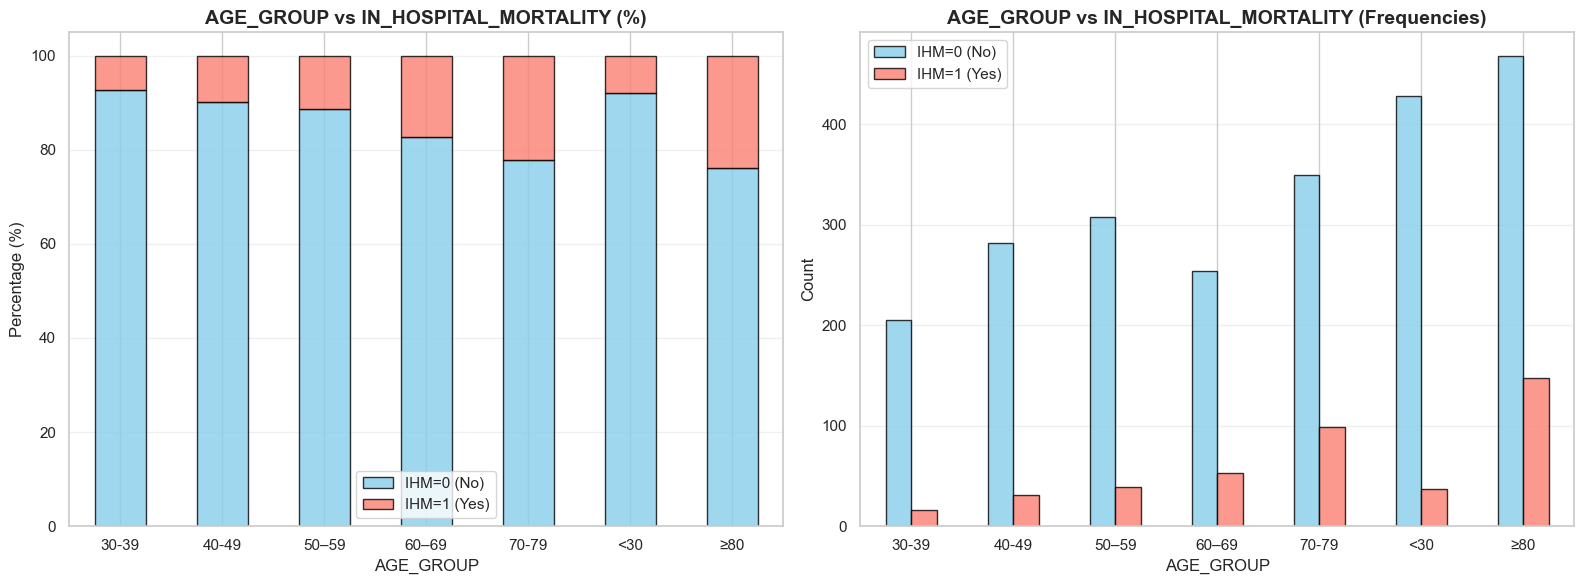

IN_HOSPITAL_MORTALITY      0      1
AGE_GROUP                          
30-39                  92.76   7.24
40-49                  90.10   9.90
50–59                  88.76  11.24
60–69                  82.74  17.26
70-79                  77.90  22.10
<30                    92.04   7.96
≥80                    76.10  23.90

  Inhospital Mortality Rate for each category:
    AGE_GROUP=<30: 7.96% CHD (n=465)
    AGE_GROUP=40-49: 9.90% CHD (n=313)
    AGE_GROUP=30-39: 7.24% CHD (n=221)
    AGE_GROUP=70-79: 22.10% CHD (n=448)
    AGE_GROUP=50–59: 11.24% CHD (n=347)
    AGE_GROUP=≥80: 23.90% CHD (n=615)
    AGE_GROUP=60–69: 17.26% CHD (n=307)

  Interpretation:
     Signicative Difference: 16.7 statistical points
     → Useful Variable for predicting Inhospital Mortality

 Analyzing: MECH_VENT


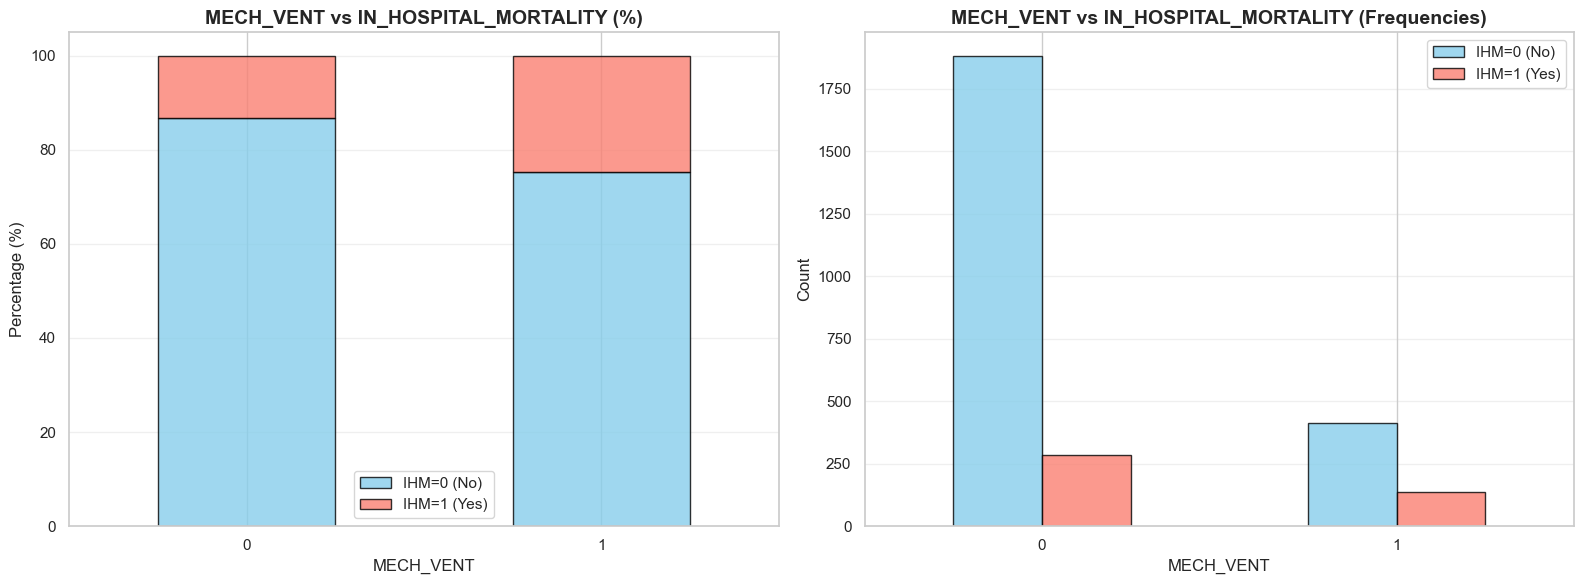

IN_HOSPITAL_MORTALITY      0      1
MECH_VENT                          
0                      86.80  13.20
1                      75.23  24.77

  Inhospital Mortality Rate for each category:
    MECH_VENT=0: 13.20% CHD (n=2167)
    MECH_VENT=1: 24.77% CHD (n=549)

  Interpretation:
     Signicative Difference: 11.6 statistical points
     → Useful Variable for predicting Inhospital Mortality


In [81]:
for col in categorical_cols:
    if col in df_to_corr.columns and target in df_to_corr.columns:
        if col != "IN_HOSPITAL_MORTALITY":
            print(f"\n Analyzing: {col}")

            # Contingency Table
            contingency = (
                pd.crosstab(df_to_corr[col], df_to_corr[target], normalize="index")
                * 100
            )
            counts = pd.crosstab(df_to_corr[col], df_to_corr[target])

            fig, axes = plt.subplots(1, 2, figsize=(16, 6))

            # Stacked Barplots
            contingency.plot(
                kind="bar",
                stacked=True,
                ax=axes[0],
                color=["skyblue", "salmon"],
                edgecolor="black",
                alpha=0.8,
            )
            axes[0].set_title(f"{col} vs {target} (%)", fontsize=14, fontweight="bold")
            axes[0].set_xlabel(col, fontsize=12)
            axes[0].set_ylabel("Percentage (%)", fontsize=12)
            axes[0].legend(["IHM=0 (No)", "IHM=1 (Yes)"], loc="best")
            axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
            axes[0].grid(axis="y", alpha=0.3)

            # Grouped Absolute Frequencies
            counts.plot(
                kind="bar",
                ax=axes[1],
                color=["skyblue", "salmon"],
                edgecolor="black",
                alpha=0.8,
            )
            axes[1].set_title(
                f"{col} vs {target} (Frequencies)", fontsize=14, fontweight="bold"
            )
            axes[1].set_xlabel(col, fontsize=12)
            axes[1].set_ylabel("Count", fontsize=12)
            axes[1].legend(["IHM=0 (No)", "IHM=1 (Yes)"], loc="best")
            axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
            axes[1].grid(axis="y", alpha=0.3)

            plt.tight_layout()
            filename = f"figures/{col}_vs_IHM_categorical.png"
            plt.savefig(filename, dpi=300, bbox_inches="tight")
            plt.show()

            print(contingency.round(2))

            # CHD Rate for each category
            print(f"\n  Inhospital Mortality Rate for each category:")
            for cat_val in df_to_corr[col].dropna().unique():
                subset = df_to_corr[df_to_corr[col] == cat_val]
                ihm_rate = (subset[target] == 1).sum() / len(subset) * 100
                n_total = len(subset)
                print(f"    {col}={cat_val}: {ihm_rate:.2f}% CHD (n={n_total})")

            # Interpretación
            ihm_rates = []
            for cat_val in df_to_corr[col].dropna().unique():
                subset = df_to_corr[df_to_corr[col] == cat_val]
                rate = (subset[target] == 1).sum() / len(subset) * 100
                ihm_rates.append(rate)

            max_rate = max(ihm_rates)
            min_rate = min(ihm_rates)
            diff_rate = max_rate - min_rate

            print(f"\n  Interpretation:")
            if diff_rate > 10:
                print(
                    f"     Signicative Difference: {diff_rate:.1f} statistical points"
                )
                print(f"     → Useful Variable for predicting Inhospital Mortality")
            else:
                print(f"     Small Difference: {diff_rate:.1f} statistical points")
                print(f"     → Limited Impact when predicting Inhospital Mortality")

- **Gender:** The charts show that in-hospital mortality is slightly higher in females (17.48%) than in males (14.36%), while survival rates remain high for both genders (over 82%). In absolute numbers, males have more total cases and deaths, but proportionally females experience a higher mortality rate. Overall, gender differences exist but are modest, with females showing a marginally higher risk of in-hospital mortality.

- **Age Group:** The graphs show a clear increase in in-hospital mortality with age, rising from about 7% in patients aged 30–39 to nearly 24% in those aged 80 and above. Older age groups (≥70 years) have both higher mortality percentages and higher death counts, despite fewer total admissions than younger groups. Overall, age demonstrates a strong and statistically significant association with in-hospital mortality, making it a useful predictor.

- **Mechanical Ventilation:** Patients who required mechanical ventilation show a substantially higher in-hospital mortality rate (24.91%) compared with those who did not (13.18%). Although fewer patients received mechanical ventilation, they account for a disproportionately higher number of deaths. This large and significant difference indicates that mechanical ventilation is a strong predictor of in-hospital mortality.

---
<a id='section4'></a>
# **4. Logistic regression model**

In [82]:
# Load cleaned df
df = pd.read_csv("data/cleaned_df.csv", sep=",", na_values=["?", " ", ""])
display(df.head(10))

,SUBJECT_ID,HADM_ID,ICUSTAY_ID,ICD9_CODES,GENDER,AGE,ICU_INTIME,ICU_OUTTIME,ICU_LOS_HOURS,IN_HOSPITAL_MORTALITY,...,MEAN_MAP,MEAN_SPO2,MECH_VENT,SODIUM,HEMOGLOBIN,MIN_GCS,AGE_GROUP,log_ICU_LOS,ICD9_3DIGIT,ICD9_DESCRIPTION
0,65,143430,244776,80012,M,26.0,2132-08-10 07:13:00,2132-08-13 15:03:00,79.8236,0,...,88.641043,98.846154,0,133.000000,14.60,2,<30,4.392269,800,Fracture of vault of skull
1,80,115385,256068,80416,M,43.0,2148-11-11 12:13:00,2148-11-12 16:46:00,28.5631,0,...,83.916667,97.875000,0,140.000000,14.40,3,40-49,3.386527,804,Multiple fractures involving skull or face
2,96,170324,211943,85181,M,38.0,2156-03-31 16:11:00,2156-04-20 16:53:00,480.6931,0,...,80.166667,99.777778,0,140.500000,12.55,1,30-39,6.177307,851,Cerebral laceration and contusion
3,129,164174,238431,85300,M,36.0,2157-03-27 08:46:00,2157-03-28 17:53:00,33.1103,0,...,80.571429,98.896552,0,144.000000,13.70,1,30-39,3.529599,853,Other and unspecified intracranial hemorrhage
4,141,168006,234668,80120,M,80.0,2140-11-06 11:09:00,2140-11-09 22:35:00,83.4361,1,...,75.809528,86.760000,0,139.800000,6.28,1,70-79,4.435995,801,Fracture of base of skull
5,144,137432,269520,85221,M,54.0,2197-07-14 21:24:00,2197-07-20 17:38:00,140.2300,0,...,80.166667,98.437500,0,139.000000,13.35,2,50–59,4.950390,852,"Subarachnoid, subdural, and extradural hemorrhage"
6,147,103631,252947,80111;8021;80229;8024;8026,M,24.0,2158-06-24 18:50:00,2158-07-01 17:22:00,166.5247,0,...,95.944482,99.967742,0,139.500000,12.60,1,<30,5.121131,801;802,Fracture of base of skull;Fracture of face bones
7,155,147148,295168,8028,M,32.0,2125-09-08 12:41:00,2125-09-09 18:14:00,29.5467,0,...,82.246383,98.625000,0,139.333333,12.60,4,30-39,3.419257,802,Fracture of face bones
8,157,110545,235058,85222,M,80.0,2106-05-17 11:00:00,2106-05-19 12:29:00,49.4914,0,...,83.357150,97.296296,0,141.000000,11.70,3,70-79,3.921803,852,"Subarachnoid, subdural, and extradural hemorrhage"
9,183,113341,252525,85300,M,51.0,2188-07-03 16:43:00,2188-07-04 19:44:00,27.0247,0,...,88.333298,98.695652,0,147.000000,10.30,3,50–59,3.333086,853,Other and unspecified intracranial hemorrhage


In [83]:
# Select features and target
columns_to_keep = [
    "AGE",
    "GENDER",
    "GCS_EYE",
    "GCS_MOTOR",
    "MEAN_MAP",
    "MEAN_SPO2",
    "SODIUM",
    "HEMOGLOBIN",
    "MECH_VENT",
    "IN_HOSPITAL_MORTALITY",
]

df = df[columns_to_keep].copy()

In [84]:
# Check missing values
df.isna().sum()

AGE                      0
GENDER                   0
GCS_EYE                  0
GCS_MOTOR                0
MEAN_MAP                 0
MEAN_SPO2                0
SODIUM                   0
HEMOGLOBIN               0
MECH_VENT                0
IN_HOSPITAL_MORTALITY    0
dtype: int64

In [85]:
# Check for duplicates
df.duplicated().sum()

np.int64(1)

In [86]:
duplicate_rows_all = df[df.duplicated(keep=False)]
print(duplicate_rows_all)

       AGE GENDER  GCS_EYE  GCS_MOTOR   MEAN_MAP  MEAN_SPO2      SODIUM  \
2178  65.0      F        2          1  80.166667  97.621463  139.619127   
2668  65.0      F        2          1  80.166667  97.621463  139.619127   

      HEMOGLOBIN  MECH_VENT  IN_HOSPITAL_MORTALITY  
2178   11.455274          0                      0  
2668   11.455274          0                      0  


In [87]:
df = df.drop_duplicates()

In [88]:
# Summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
AGE,2715.0,58.740773,22.853713,18.000000,40.000000,61.000000,79.000000,91.40
GCS_EYE,2715.0,2.306814,1.236783,1.000000,1.000000,2.000000,3.000000,4.00
GCS_MOTOR,2715.0,4.362799,1.965776,1.000000,3.000000,5.000000,6.000000,6.00
MEAN_MAP,2715.0,80.205042,9.580303,30.933333,76.371194,80.166667,83.373026,194.00
MEAN_SPO2,2715.0,97.621463,2.841204,57.000000,96.732520,98.062500,99.307692,100.00
SODIUM,2715.0,139.623402,3.820941,121.333333,138.000000,139.619127,141.666667,166.00
HEMOGLOBIN,2715.0,11.450008,1.794439,3.700000,10.200000,11.455274,12.700000,20.75
MECH_VENT,2715.0,0.202210,0.401722,0.000000,0.000000,0.000000,0.000000,1.00
IN_HOSPITAL_MORTALITY,2715.0,0.155433,0.362383,0.000000,0.000000,0.000000,0.000000,1.00


In [89]:
# Check data types
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2715 entries, 0 to 2715
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   AGE                    2715 non-null   float64
 1   GENDER                 2715 non-null   object 
 2   GCS_EYE                2715 non-null   int64  
 3   GCS_MOTOR              2715 non-null   int64  
 4   MEAN_MAP               2715 non-null   float64
 5   MEAN_SPO2              2715 non-null   float64
 6   SODIUM                 2715 non-null   float64
 7   HEMOGLOBIN             2715 non-null   float64
 8   MECH_VENT              2715 non-null   int64  
 9   IN_HOSPITAL_MORTALITY  2715 non-null   int64  
dtypes: float64(5), int64(4), object(1)
memory usage: 233.3+ KB


In [90]:
# Convert age to int
df["AGE"] = df["AGE"].astype(int)

In [91]:
# Map gender
df["GENDER"] = df["GENDER"].map({"M": 1, "F": 0})

In [92]:
target = "IN_HOSPITAL_MORTALITY"
continuous_vars = [
    "AGE",
    "GCS_EYE",
    "GCS_MOTOR",
    "MEAN_MAP",
    "MEAN_SPO2",
    "SODIUM",
    "HEMOGLOBIN",
]
binary_vars = ["GENDER", "MECH_VENT"]

In [93]:
X = df[continuous_vars + binary_vars]
y = df[target]

In [94]:
# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Train shape: {X_train.shape}")
print(y_train.value_counts(normalize=True))

print(f"\nTest shape: {X_test.shape}")
print(y_test.value_counts(normalize=True))

Train shape: (1900, 9)
IN_HOSPITAL_MORTALITY
0    0.844737
1    0.155263
Name: proportion, dtype: float64

Test shape: (815, 9)
IN_HOSPITAL_MORTALITY
0    0.844172
1    0.155828
Name: proportion, dtype: float64


In [95]:
# Standardize continuous variables
scaler = StandardScaler()
X_train[continuous_vars] = scaler.fit_transform(X_train[continuous_vars])
X_test[continuous_vars] = scaler.transform(X_test[continuous_vars])

Linearity of Continuous Predictors with Log-Odds:

Logistic regression assumes that the log-odds of the outcome (in this case, in-hospital mortality) is a linear function of each continuous predictor. This means that while the probability of death is non-linear, the logit transformation of the probability should change linearly with variables such as ``AGE``, ``GCS_EYE``, ``GCS_MOTOR``, ``MEAN_MAP``, ``MEAN_SPO2``, ``SODIUM``, and ``HEMOGLOBIN``. Violations of this assumption can lead to biased coefficient estimates, inaccurate predicted probabilities, and poor risk stratification. To assess this assumption, we examined the relationship between each continuous predictor and the logit of the outcome. Visual inspection using smoothed plots allows identification of potential non-linear trends.

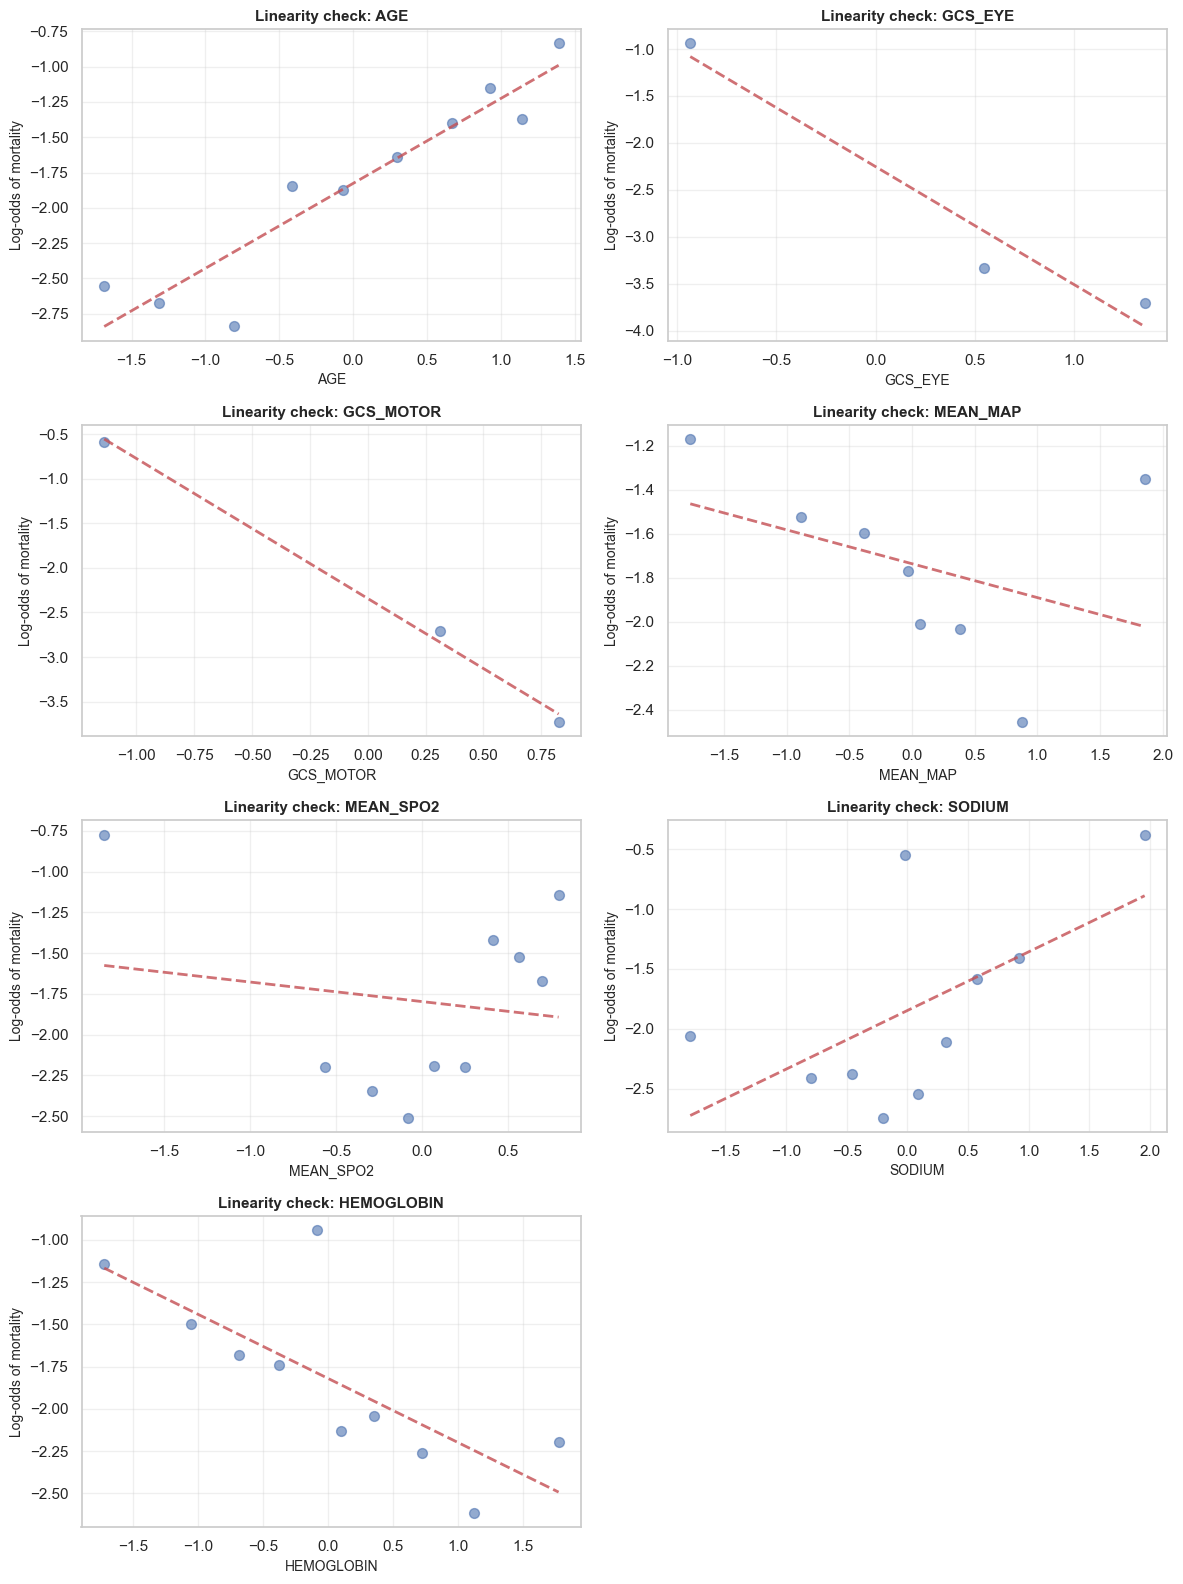

In [96]:
# Check Linearity Assumption (training set)
df_train = X_train[continuous_vars + binary_vars].copy()
df_train["IN_HOSPITAL_MORTALITY"] = y_train

# Create logit plots for continuous variables
n_plots = len(continuous_vars)
n_cols = 2
n_rows = (n_plots + 1) // 2

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows))
if n_rows == 1:
    axes = axes.reshape(1, -1)
axes = axes.flatten()

for idx, var in enumerate(continuous_vars):
    # Create quantile groups
    df_train[f"{var}_quantile"] = pd.qcut(
        df_train[var], q=10, duplicates="drop", labels=False
    )

    # Calculate log-odds for each group
    grouped = df_train.groupby(f"{var}_quantile").agg(
        {var: "mean", "IN_HOSPITAL_MORTALITY": ["sum", "count"]}
    )

    grouped.columns = ["mean_value", "deaths", "total"]
    grouped["prop"] = grouped["deaths"] / grouped["total"]

    # Add small constant to avoid log(0)
    grouped["prop_adj"] = grouped["prop"].clip(0.01, 0.99)
    grouped["logit"] = np.log(grouped["prop_adj"] / (1 - grouped["prop_adj"]))

    # Plot
    axes[idx].scatter(grouped["mean_value"], grouped["logit"], alpha=0.6, s=50)
    axes[idx].set_xlabel(var, fontsize=10)
    axes[idx].set_ylabel("Log-odds of mortality", fontsize=10)
    axes[idx].set_title(f"Linearity check: {var}", fontsize=11, fontweight="bold")
    axes[idx].grid(True, alpha=0.3)

    # Add trend line
    z = np.polyfit(grouped["mean_value"], grouped["logit"], 1)
    p = np.poly1d(z)
    axes[idx].plot(
        grouped["mean_value"], p(grouped["mean_value"]), "r--", alpha=0.8, linewidth=2
    )

# Remove extra subplots
for idx in range(len(continuous_vars), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.savefig(
    "figures/linearity_check_logit_plots.png",
    dpi=300,
    bbox_inches="tight"
)

# Drop temporary quantile columns
df_train = df_train.drop([f"{var}_quantile" for var in continuous_vars], axis=1)

We can see that ``MEAN_MAP`` and ``MEAN_SPO2`` are non-linear. To handle this, we will categorize the variables into clinically meaningful categories.

In [97]:
# Categorize MEAN_MAP
df["MAP_category"] = pd.cut(
    df["MEAN_MAP"],
    bins=[-float("inf"), 65, 100, float("inf")],
    labels=["Low", "Normal", "High"],
)
# Categorize MEAN_SPO2
df["SpO2_category"] = pd.cut(
    df["MEAN_SPO2"], bins=[-float("inf"), 90, 95, 100], labels=["Low", "Mild", "Normal"]
)

# Drop original non-linear columns
df = df.drop(columns=["MEAN_MAP", "MEAN_SPO2"])

When we one-hot encode a categorical variable with k categories, it creates k columns.

These columns are perfectly collinear because for each row, exactly one column is 1 and the others are 0.

To avoid perfect multicollinearity, we will drop one category (Normal).

In [98]:
categorical_cols = ["MAP_category", "SpO2_category"]

# Drop 'Normal' from first and second column
encoder = OneHotEncoder(
    sparse_output=False,
    drop=["Normal", "Normal"],
)

encoded_array = encoder.fit_transform(df[categorical_cols])
encoded_col_names = encoder.get_feature_names_out(categorical_cols)
encoded_df = pd.DataFrame(encoded_array, columns=encoded_col_names, index=df.index)

# Drop original columns and join encoded
df = df.drop(columns=categorical_cols).join(encoded_df)

In [99]:
target = "IN_HOSPITAL_MORTALITY"
binary_vars = ["GENDER", "MECH_VENT"]
continuous_vars = ["AGE", "GCS_EYE", "GCS_MOTOR", "SODIUM", "HEMOGLOBIN"]
one_hot_cols = [
    col for col in df.columns if col not in continuous_vars + binary_vars + [target]
]

X = df[continuous_vars + binary_vars + one_hot_cols]
y = df[target]

In [100]:
# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Train shape: {X_train.shape}")
print(y_train.value_counts(normalize=True))

print(f"\nTest shape: {X_test.shape}")
print(y_test.value_counts(normalize=True))

Train shape: (1900, 11)
IN_HOSPITAL_MORTALITY
0    0.844737
1    0.155263
Name: proportion, dtype: float64

Test shape: (815, 11)
IN_HOSPITAL_MORTALITY
0    0.844172
1    0.155828
Name: proportion, dtype: float64


In [101]:
# Standardize continuous variables
scaler = StandardScaler()
X_train[continuous_vars] = scaler.fit_transform(X_train[continuous_vars])
X_test[continuous_vars] = scaler.transform(X_test[continuous_vars])

Assessing multicollinearity is essential because highly correlated predictors can inflate the standard errors of regression coefficients, reducing the reliability of estimated effects and making it difficult to interpret individual predictor contributions.   

Multicollinearity among continuous predictors was assessed using the Variance Inflation Factor (VIF). Variables with excessive collinearity (VIF ≥ 10) were sequentially removed. The final model included predictors with acceptable collinearity and strong clinical interpretability.

In [102]:
# Check multicollinearity using VIF
X_train_vif = X_train.copy()

vif_data = pd.DataFrame()
vif_data["Variable"] = X_train_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_train_vif.values, i)
    for i in range(X_train_vif.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)
print(vif_data.to_string(index=False))

          Variable      VIF
           GCS_EYE 2.334860
         GCS_MOTOR 2.234099
         MECH_VENT 1.330159
            GENDER 1.300313
               AGE 1.134959
        HEMOGLOBIN 1.132406
  MAP_category_Low 1.080989
SpO2_category_Mild 1.059548
 SpO2_category_Low 1.055197
            SODIUM 1.049544
 MAP_category_High 1.033245


Interpretation: 
- VIF < 5: No multicollinearity  
- VIF 5-10: Moderate multicollinearity  
- VIF > 10: Severe multicollinearity  

The ratio of events to predictors, known as Events Per Variable (EPV), was calculated to evaluate the adequacy of the sample size relative to the number of predictors included in the model. EPV is an important metric in regression modeling because a low EPV increases the risk of overfitting, leading to unstable coefficient estimates and reduced generalizability. An EPV of at least 10 is commonly considered the minimum to avoid overfitting, while values of 15 or higher are preferred for robust and reliable model estimation. In this analysis, the EPV was calculated as the number of events divided by the number of predictors.

In [103]:
# Count number of events (mortality = 1)
num_events = y_train.sum()
print("Number of events (deaths):", num_events)

# Count number of predictors/features in the model
num_predictors = X_train.shape[1]
print("Number of predictors:", num_predictors)

# Calculate EPV
EPV = num_events / num_predictors
print(f"Events per variable (EPV): {EPV:.2f}")
if EPV < 10:
    print("  - EPV < 10 may lead to overfitting!")
elif EPV < 15:
    print("  - EPV is acceptable but borderline (aim for 15+)")
else:
    print("  - EPV is adequate (≥15)")

Number of events (deaths): 295
Number of predictors: 11
Events per variable (EPV): 26.82
  - EPV is adequate (≥15)


A logistic regression model was developed to predict the binary outcome using L2 regularization (ridge penalty) to reduce overfitting and improve coefficient stability. The liblinear solver was used due to its efficiency with smaller datasets and support for L2 regularization. To account for class imbalance in the outcome, class weights were set to “balanced,” ensuring that minority class observations contributed proportionally to the model fitting. The maximum number of iterations was increased to 1000 to ensure convergence.  

Model performance was assessed using stratified 5-fold cross-validation on the training set, evaluating accuracy, precision, recall, F1-score, and area under the receiver operating characteristic curve (AUC). After cross-validation, the model was fitted on the full training set and evaluated on the independent test set using the same performance metrics. Predicted probabilities were used to generate ROC curves, providing a visual comparison of model discrimination between training and test sets.

Cross-validated performance (5-fold):
  - Accuracy: 0.805
  - Precision: 0.432
  - Recall: 0.800
  - F1-score: 0.560
  - AUC: 0.893

Optimal threshold (max F1 on training data):
  - Threshold: 0.74

Test set performance:
  - Accuracy: 0.860
  - Precision: 0.549
  - Recall: 0.575
  - F1-score: 0.562
  - AUC: 0.885


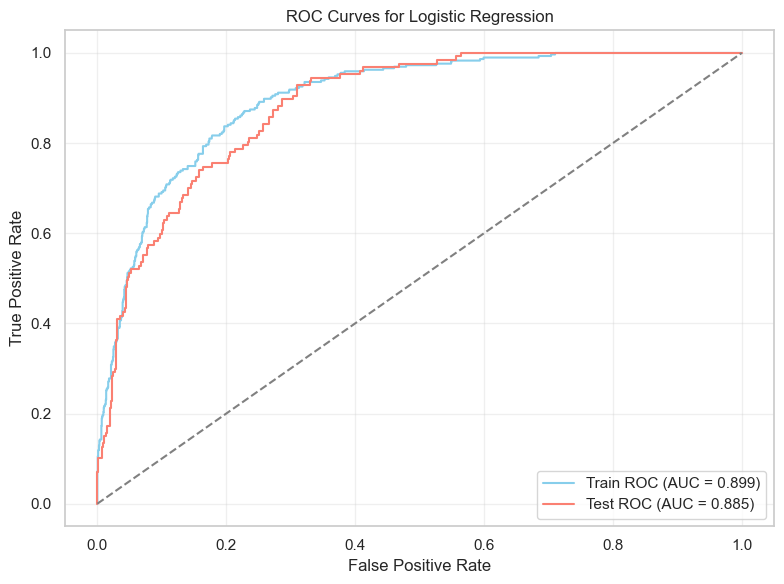

In [104]:
# Weighted logistic regression (with ridge regularization)
model = LogisticRegression(
    penalty="l2",  # Ridge regularization
    solver="liblinear",
    class_weight="balanced",  # Handles class imbalance
    max_iter=1000,
    random_state=42,
)

# Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1-score": "f1",
    "AUC": "roc_auc",
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
)

print("Cross-validated performance (5-fold):")
for metric in scoring:
    print(f"  - {metric}: {cv_results['test_' + metric].mean():.3f}")

# Train final model
model.fit(X_train, y_train)

# Probabilities
y_train_prob = model.predict_proba(X_train)[:, 1]
y_test_prob = model.predict_proba(X_test)[:, 1]

# Threshold tuning (training set)
thresholds = np.linspace(0.01, 0.99, 99)
f1_scores = []

for t in thresholds:
    y_train_pred_t = (y_train_prob >= t).astype(int)
    f1_scores.append(f1_score(y_train, y_train_pred_t))

best_threshold = thresholds[np.argmax(f1_scores)]

print("\nOptimal threshold (max F1 on training data):")
print(f"  - Threshold: {best_threshold:.2f}")

# Test set evaluation
y_test_pred = (y_test_prob >= best_threshold).astype(int)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_prob)

print("\nTest set performance:")
print(f"  - Accuracy: {test_accuracy:.3f}")
print(f"  - Precision: {test_precision:.3f}")
print(f"  - Recall: {test_recall:.3f}")
print(f"  - F1-score: {test_f1:.3f}")
print(f"  - AUC: {test_auc:.3f}")

# ROC Curves
fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

auc_train = auc(fpr_train, tpr_train)
auc_test = auc(fpr_test, tpr_test)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr_train, tpr_train, label=f"Train ROC (AUC = {auc_train:.3f})", color="skyblue"
)
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {auc_test:.3f})", color="salmon")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/roc_curve_logistic_regression.png", dpi=300, bbox_inches="tight")
plt.show()

AUC interpretation:  
- < 0.7: Discrimination: Poor  
- < 0.8: Discrimination: Acceptable  
- < 0.9: Discrimination: Good  
- else: Discrimination: Excellent  

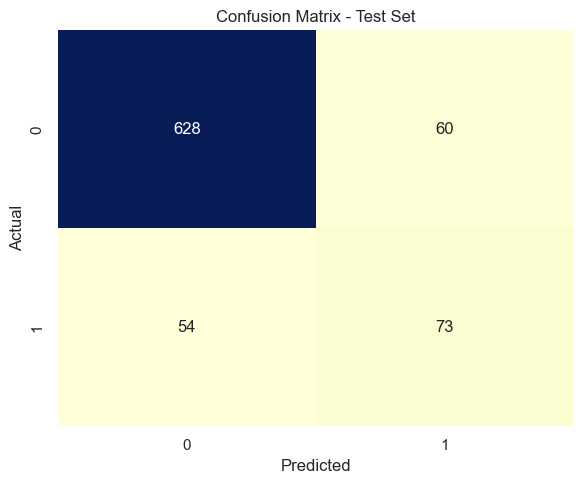

In [105]:
# Confusion matrix (test set)
cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="YlGnBu", cbar=False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Test Set")
plt.tight_layout()
plt.savefig("figures/confussion_matrix_test.png", dpi=300, bbox_inches="tight")
plt.show()

In [106]:
# Classification report (test set)
report_test = classification_report(y_test, y_test_pred, digits=3)
print("Classification Report - Test Set:\n")
print(report_test)

Classification Report - Test Set:

              precision    recall  f1-score   support

           0      0.921     0.913     0.917       688
           1      0.549     0.575     0.562       127

    accuracy                          0.860       815
   macro avg      0.735     0.744     0.739       815
weighted avg      0.863     0.860     0.861       815



A weighted logistic regression model with L2 (ridge) regularization was developed to predict in-hospital mortality. To address class imbalance, the decision threshold was tuned on the training data to maximize the F1-score for the mortality class (to achieve a more balance trade-off between precision and recall). Resulting in an optimal threshold of 0.74.  

During 5-fold cross-validation on the training set, the model achieved an average accuracy of 0.805, precision of 0.432, recall of 0.800, and an F1-score of 0.560 for the mortality class, with an AUC of 0.893, indicating strong discriminative performance.  

On the held-out test set, the model demonstrated consistent performance, achieving an accuracy of 0.860 and AUC of 0.885. For the mortality class specifically, precision was 0.549, recall 0.575, and the F1-score 0.562, confirming good generalization.  

As expected, classification performance was higher for the majority class (survival), while the model maintained a clinically appropriate balance between sensitivity and specificity for mortality prediction.

Finally, feature importance was assessed using the absolute value of the standardized coefficients, with higher values indicating stronger predictive influence on the model.

In [107]:
feature_importance = pd.DataFrame(
    {"feature": X_train.columns, "coefficient": model.coef_[0]}
)

feature_importance["abs_coefficient"] = np.abs(feature_importance["coefficient"])
feature_importance = feature_importance.sort_values(
    by="abs_coefficient", ascending=False
)

print(feature_importance.head(10))

               feature  coefficient  abs_coefficient
9    SpO2_category_Low     2.460729         2.460729
0                  AGE     1.098866         1.098866
2            GCS_MOTOR    -1.072933         1.072933
10  SpO2_category_Mild     0.954500         0.954500
7    MAP_category_High     0.893542         0.893542
1              GCS_EYE    -0.661381         0.661381
3               SODIUM     0.378517         0.378517
4           HEMOGLOBIN    -0.237670         0.237670
8     MAP_category_Low    -0.191411         0.191411
6            MECH_VENT     0.165815         0.165815


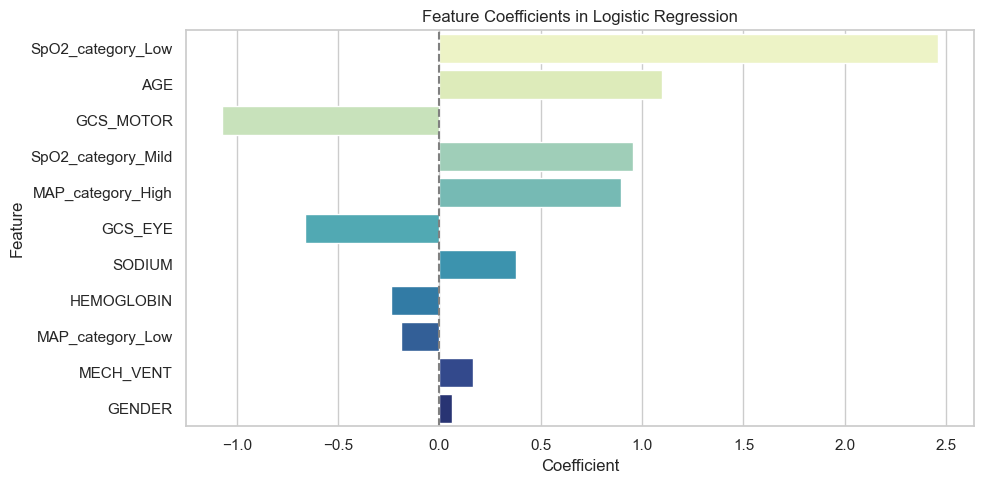

In [108]:
# Plot
plt.figure(figsize=(10, 5))
sns.barplot(x="coefficient", y="feature", data=feature_importance, palette="YlGnBu")
plt.axvline(0, color="gray", linestyle="--")  # Reference line at 0
plt.title("Feature Coefficients in Logistic Regression")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/logistic_regression_feature_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

Interpretation:  
The horizontal bars show the direction and magnitude of each coefficient.
- Positive coefficients (right of 0) → increase risk of mortality.
- Negative coefficients (left of 0) → decrease risk of mortality.

The horizontal bars represent the direction and magnitude of each coefficient. Positive coefficients indicate an increased risk of in-hospital mortality, while negative coefficients indicate a decreased risk.

The logistic regression model identified several key predictors of in-hospital mortality among the patient cohort. It specifically identified oxygenation status and neurological function as the most influential predictors.   

The most influential variable was low SpO₂ (``SpO₂_category_Low``), with a positive coefficient of 2.461, indicating that patients with low oxygen saturation have a substantially higher likelihood of in-hospital mortality compared to those with normal oxygen levels. This underscores the critical role of hypoxemia in patient prognosis.

Advanced age (``AGE``) was the next most influential positive predictor, underscoring the well-established association between increasing age and mortality risk.   

Moderate oxygen desaturation (``SpO₂_category_Mild``) also demonstrated a positive association with mortality, suggesting a graded increase in risk with worsening oxygenation.

Blood pressure abnormalities showed asymmetric effects. High mean arterial pressure (``MAP_category_High``) was positively associated with mortality, whereas low MAP (``MAP_category_Low``) exhibited a small negative coefficient, indicating a minimal independent effect after adjustment for other covariates.

Neurological status emerged as a strong protective factor. Both ``GCS_MOTOR`` and ``GCS_EYE`` displayed negative coefficients, indicating that higher neurological scores were associated with a reduced probability of in-hospital mortality. Among these, ``GCS_MOTOR`` demonstrated a larger absolute effect size, highlighting its particular prognostic relevance.

Laboratory variables showed more modest contributions. Serum sodium (``SODIUM``) was positively associated with mortality, while hemoglobin (``HEMOGLOBIN``) had a small negative coefficient, suggesting a limited protective effect.   

Mechanical ventilation (``MECH_VENT``) exhibited a relatively small positive coefficient, indicating only a minor independent association with mortality once other clinical factors were accounted for.

Overall, the model emphasizes the dominant prognostic role of oxygenation status and neurological impairment in predicting in-hospital mortality, with age contributing substantially and hemodynamic and laboratory variables providing additional, but comparatively smaller, predictive information.